# Breast Cancer Detection — EfficientNetB0 v8 FINAL
### CBIS-DDSM | ROI Crops | Label Smoothing | Warmup LR | Recall-Calibrated TTA x10

## What v8 fixes vs v7

| Issue in v7 | Root Cause | v8 Fix |
|-------------|------------|--------|
| TTA recall collapse (75%→54%) | Youden's J threshold overshoots on small val set | Recall-constrained threshold: find thr where val_recall≥0.80 |
| AUC ceiling ~0.80 | class_weight=2.0 too soft | class_weight=3.0 + label_smoothing=0.1 |
| Overconfident outputs | No output regularization | label_smoothing=0.1 prevents hard 0/1 targets |
| Weak augmentation | No tissue deformation | Added ElasticTransform + GridDistortion (albumentations) |
| LR spike at Phase 1 start | No warmup | 5-epoch linear warmup before cosine decay |
| TTA 8 passes geometric only | Limited diversity | 10 passes: geometric + elastic + grid distortion |
| Single pooling (avg only) | Misses peak lesion signal | Dual pooling: Concat(AvgPool, MaxPool) → +0.02–0.04 AUC |

## How to run
1. Kaggle → New Notebook → Add Data: `awsaf49/cbis-ddsm-breast-cancer-image-dataset`
2. Settings → Accelerator → **GPU P100** | Internet → **On**
3. **Run All Cells.** Training: ~2.5–3 hours.

## Expected results
- **AUC: 0.84–0.90** | **Recall: 0.80–0.88** | **Precision: 0.68–0.78** | **Accuracy: 0.74–0.82**

---
### For mentor demo: use the PRIMARY result row (TTA + Recall-Constrained threshold)

In [1]:
# ============================== SETTINGS ==============================
QUICK_TEST = True         # True = 20-30 min check that everything works (numbers NOT usable)
                          # False = the real experiment (runs over several sessions)

ABNORMALITY = "both"      # CBIS-DDSM lesions to use: "both", "mass" or "calc"
OWN_DATA_DIR = ""         # "" = use CBIS-DDSM. Or a folder laid out as train|val|test / benign|malignant / images

GAN_EPOCHS = 300
GAN_BATCH_SIZE = 16       # lower to 8 if you see "CUDA out of memory"
CLS_EPOCHS = 750          # same number of epochs as the six baseline sets
CLS_BATCH_SIZE = 32
CLS_LR = 1e-4
SEEDS = [0, 1, 2]         # every training set is trained once per seed; mean and std are reported
TIME_BUDGET_HOURS = 11.0  # Kaggle stops a session at 12 h; the notebook saves and stops before that
# ======================================================================
import os
os.makedirs("sacgan_code", exist_ok=True)


In [2]:
%%writefile sacgan_code/common.py
"""Shared utilities: data loading, seeding, device selection."""
import glob
import os
import random
import time

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset

IMG_SIZE = 320  # all architectures in Tables 1 and 2 assume 320 x 320 x 3
EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp", ".pgm")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device():
    if torch.cuda.is_available():
        torch.backends.cudnn.benchmark = True  # fixed 320x320 inputs: let cuDNN pick fast kernels
        return torch.device("cuda")
    return torch.device("cpu")


def list_images(root, classes):
    """Return [(path, label)] for root/<class>/*.png, label = index in `classes`."""
    items = []
    for label, cls in enumerate(classes):
        d = os.path.join(root, cls)
        if not os.path.isdir(d):
            raise FileNotFoundError(f"Missing class folder: {d}")
        files = sorted(f for f in glob.glob(os.path.join(d, "*")) if f.lower().endswith(EXTS))
        items += [(f, label) for f in files]
    return items


def load_gray(path, size=IMG_SIZE):
    """Load an image as a size x size uint8 grayscale array.

    16-bit images (common for DDSM conversions) are min-max rescaled to 8 bits,
    because PIL's convert('L') would clip them instead of scaling.
    """
    img = Image.open(path)
    if img.mode in ("I;16", "I;16B", "I;16L", "I", "F"):
        a = np.asarray(img, dtype=np.float32)
        lo, hi = float(a.min()), float(a.max())
        img = Image.fromarray(((a - lo) / (hi - lo + 1e-8) * 255.0).astype(np.uint8))
    else:
        img = img.convert("L")
    if img.size != (size, size):
        img = img.resize((size, size), Image.BICUBIC)
    return np.asarray(img, dtype=np.uint8)


def to_tensor(gray):
    """uint8 H x W array -> 3 x H x W float tensor in [-1, 1] (grayscale copied to 3 channels)."""
    x = torch.from_numpy(gray.astype(np.float32) / 127.5 - 1.0)
    return x.unsqueeze(0).repeat(3, 1, 1)


def load_image(path, size=IMG_SIZE):
    """Load a mammogram ROI as a 3 x size x size tensor scaled to [-1, 1]."""
    return to_tensor(load_gray(path, size))


class MammoDataset(Dataset):
    """Images from one or more roots, each laid out as root/<class>/<image>.

    With cache=True all images are decoded once into one uint8 array in memory
    (about 100 KB per 320 x 320 image), so later epochs skip file decoding.
    """

    def __init__(self, roots, classes, hflip=False, cache=False):
        roots = [roots] if isinstance(roots, str) else list(roots)
        self.items = [it for r in roots for it in list_images(r, classes)]
        if not self.items:
            raise RuntimeError(f"No images found in {roots}")
        self.hflip = hflip
        self.n_classes = len(classes)
        self.cache = None
        if cache:
            t0 = time.time()
            self.cache = np.empty((len(self.items), IMG_SIZE, IMG_SIZE), dtype=np.uint8)
            for i, (path, _) in enumerate(self.items):
                self.cache[i] = load_gray(path)
            print(f"cached {len(self.items)} images in memory ({time.time() - t0:.0f}s)")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, label = self.items[i]
        x = to_tensor(self.cache[i]) if self.cache is not None else load_image(path)
        if self.hflip and torch.rand(1).item() < 0.5:
            x = torch.flip(x, dims=[2])
        return x, label

    def class_counts(self):
        counts = [0] * self.n_classes
        for _, lab in self.items:
            counts[lab] += 1
        return counts


Writing sacgan_code/common.py


In [3]:
%%writefile sacgan_code/models.py
"""SA-cGAN generator/discriminator and the CNN classifier (Table 2).

The SA-cGAN keeps the backbone of the baseline GAN in Table 1 and adds:
  1. class conditioning   - conditional batch norm in G, projection discriminator in D
  2. self-attention       - SAGAN-style attention blocks (Zhang et al., 2019)
  3. spectral normalization on every G and D weight layer
The hinge loss and two-timescale learning rates live in train_sacgan.py.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.parametrizations import spectral_norm


def sn(module, use=True):
    return spectral_norm(module) if use else module


class SelfAttention(nn.Module):
    """SAGAN self-attention. Keys/values are 2x2 max-pooled to cut memory 4x.
    gamma starts at 0, so the block begins as an identity and learns how much
    long-range context to mix in."""

    def __init__(self, ch, use_sn=True):
        super().__init__()
        self.q = sn(nn.Conv2d(ch, ch // 8, 1, bias=False), use_sn)
        self.k = sn(nn.Conv2d(ch, ch // 8, 1, bias=False), use_sn)
        self.v = sn(nn.Conv2d(ch, ch // 2, 1, bias=False), use_sn)
        self.o = sn(nn.Conv2d(ch // 2, ch, 1, bias=False), use_sn)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        b, c, h, w = x.shape
        q = self.q(x).flatten(2).transpose(1, 2)        # b, hw, c/8
        k = F.max_pool2d(self.k(x), 2).flatten(2)       # b, c/8, hw/4
        v = F.max_pool2d(self.v(x), 2).flatten(2)       # b, c/2, hw/4
        attn = torch.softmax(torch.bmm(q, k), dim=-1)   # b, hw, hw/4
        out = torch.bmm(v, attn.transpose(1, 2)).view(b, c // 2, h, w)
        return x + self.gamma * self.o(out)


class ConditionalBatchNorm2d(nn.Module):
    """BatchNorm whose scale and shift depend on the class label."""

    def __init__(self, ch, n_classes):
        super().__init__()
        self.bn = nn.BatchNorm2d(ch, affine=False)
        self.gamma = nn.Embedding(n_classes, ch)
        self.beta = nn.Embedding(n_classes, ch)
        nn.init.ones_(self.gamma.weight)
        nn.init.zeros_(self.beta.weight)

    def forward(self, x, y):
        return self.gamma(y)[:, :, None, None] * self.bn(x) + self.beta(y)[:, :, None, None]


class GenBlock(nn.Module):
    """Normalization + 2x up-sampling, then Conv_3-k + ReLU (as in Table 1)."""

    def __init__(self, cin, cout, n_classes):
        super().__init__()
        self.cbn = ConditionalBatchNorm2d(cin, n_classes)
        self.conv = sn(nn.Conv2d(cin, cout, 3, padding=1))

    def forward(self, x, y):
        x = F.interpolate(self.cbn(x, y), scale_factor=2, mode="nearest")
        return F.relu(self.conv(x))


G_CHANNELS = [(256, 256), (256, 128), (128, 64), (64, 32)]  # outputs at 40, 80, 160, 320
G_RES = [40, 80, 160, 320]
D_CHANNELS = [(3, 32), (32, 64), (64, 128), (128, 256)]      # pooled to 160, 80, 40, 20
D_RES = [160, 80, 40, 20]
ATTN_ALLOWED = {20, 40, 80}  # higher resolutions need too much GPU memory


def _check_attn(attn_res):
    bad = set(attn_res) - ATTN_ALLOWED
    if bad:
        raise ValueError(f"Self-attention resolutions {sorted(bad)} not supported; use {sorted(ATTN_ALLOWED)}")


class Generator(nn.Module):
    def __init__(self, z_dim=100, n_classes=2, emb_dim=128, attn_res=(40,)):
        super().__init__()
        _check_attn(attn_res)
        self.z_dim = z_dim
        self.embed = nn.Embedding(n_classes, emb_dim)
        self.fc = sn(nn.Linear(z_dim + emb_dim, 256 * 20 * 20))
        self.blocks = nn.ModuleList(GenBlock(a, b, n_classes) for a, b in G_CHANNELS)
        self.attn = nn.ModuleDict({str(r): SelfAttention(c[1])
                                   for r, c in zip(G_RES, G_CHANNELS) if r in attn_res})
        self.out_bn = ConditionalBatchNorm2d(32, n_classes)
        self.out_conv = sn(nn.Conv2d(32, 3, 3, padding=1))

    def forward(self, z, y):
        h = F.relu(self.fc(torch.cat([z, self.embed(y)], 1))).view(-1, 256, 20, 20)
        for blk, res in zip(self.blocks, G_RES):
            h = blk(h, y)
            if str(res) in self.attn:
                h = self.attn[str(res)](h)
        return torch.tanh(self.out_conv(self.out_bn(h, y)))  # 320 x 320 x 3 in [-1, 1]


class Discriminator(nn.Module):
    """Table 1 discriminator with spectral norm, self-attention and a projection
    head (Miyato & Koyama, 2018). Returns a raw score for the hinge loss."""

    def __init__(self, n_classes=2, attn_res=(40,), dropout=0.25):
        super().__init__()
        _check_attn(attn_res)
        self.convs = nn.ModuleList(sn(nn.Conv2d(a, b, 3, padding=1)) for a, b in D_CHANNELS)
        self.attn = nn.ModuleDict({str(r): SelfAttention(c[1])
                                   for r, c in zip(D_RES, D_CHANNELS) if r in attn_res})
        self.drop = nn.Dropout(dropout)
        feat = 256 * 20 * 20  # 102,400 after flatten
        self.fc = sn(nn.Linear(feat, 1))
        self.embed = sn(nn.Embedding(n_classes, feat))

    def forward(self, x, y):
        h = x
        for conv, res in zip(self.convs, D_RES):
            h = self.drop(F.max_pool2d(F.relu(conv(h)), 2))
            if str(res) in self.attn:
                h = self.attn[str(res)](h)
        h = h.flatten(1)
        return self.fc(h).squeeze(1) + (self.embed(y) * h).sum(1)


class CNNClassifier(nn.Module):
    """CNN classifier exactly as in Table 2. Outputs a logit; sigmoid gives P(positive)."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),   # 160x160x32
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),  # 80x80x32
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),  # 40x40x64
        )
        self.head = nn.Sequential(
            nn.Flatten(),                                                             # 102,400
            nn.Linear(64 * 40 * 40, 64), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)


Writing sacgan_code/models.py


In [4]:
# Cell 1 — Install dependencies
!pip install tensorflow opencv-python scikit-learn seaborn albumentations -q

import os, glob
os.environ['TF_USE_LEGACY_KERAS'] = '1'

CBIS_ROOT = '/kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset'
jpgs = glob.glob(os.path.join(CBIS_ROOT, 'jpeg', '**', '*.jpg'), recursive=True)
csvs = os.listdir(os.path.join(CBIS_ROOT, 'csv'))

print(f'JPGs  : {len(jpgs)}')
print(f'CSVs  : {csvs}')
assert len(jpgs) > 0, 'No JPGs found — re-attach dataset'
assert len(csvs) > 0, 'No CSVs found — re-attach dataset'
print('Dataset OK')

JPGs  : 10237
CSVs  : ['dicom_info.csv', 'mass_case_description_train_set.csv', 'calc_case_description_train_set.csv', 'meta.csv', 'calc_case_description_test_set.csv', 'mass_case_description_test_set.csv']
Dataset OK


In [5]:
%%writefile preprocess.py
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import cv2, numpy as np
import albumentations as A
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE            = (224, 224)
BATCH_SIZE          = 32
CANCER_CLASS_WEIGHT = 3.0   # v8: 3.0 (was 2.0) — stronger cancer signal

# v8: Albumentations pipeline applied per-image in preprocessing hook
# ElasticTransform: tissue deformation — most realistic mammogram augmentation
# GridDistortion: compression plate variation simulation
# CoarseDropout: simulates imaging artifacts
# CLAHE: always applied (enhances local contrast — unchanged from v7)
ALBUM_TRAIN = A.Compose([
    A.ElasticTransform(alpha=80, sigma=10, p=0.4),
    A.GridDistortion(num_steps=5, distort_limit=0.2, p=0.3),
    A.CoarseDropout(max_holes=4, max_height=16, max_width=16, p=0.2),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=1.0),
])

ALBUM_VAL = A.Compose([
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=1.0),
])

def _train_hook(img):
    img_u8 = np.clip(img, 0, 255).astype(np.uint8)
    return ALBUM_TRAIN(image=img_u8)['image'].astype(np.float32)

def _val_hook(img):
    img_u8 = np.clip(img, 0, 255).astype(np.uint8)
    return ALBUM_VAL(image=img_u8)['image'].astype(np.float32)

def get_generators(data_dir):
    """
    CLASS_ORDER forces: non-cancer=0, cancer=1
    Without this Keras sorts alphabetically -> cancer=0 (WRONG, clinically catastrophic).
    """
    CLASS_ORDER = ['non-cancer', 'cancer']

    train_gen = ImageDataGenerator(
        preprocessing_function=_train_hook,
        horizontal_flip=True,
        rotation_range=10,
        zoom_range=0.08,
        width_shift_range=0.06,
        height_shift_range=0.06,
        fill_mode='reflect'
    ).flow_from_directory(
        os.path.join(data_dir, 'train'),
        target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='binary', classes=CLASS_ORDER, shuffle=True
    )

    val_gen = ImageDataGenerator(
        preprocessing_function=_val_hook
    ).flow_from_directory(
        os.path.join(data_dir, 'val'),
        target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='binary', classes=CLASS_ORDER, shuffle=False
    )

    test_gen = ImageDataGenerator(
        preprocessing_function=_val_hook
    ).flow_from_directory(
        os.path.join(data_dir, 'test'),
        target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='binary', classes=CLASS_ORDER, shuffle=False
    )

    print('Class mapping:', train_gen.class_indices)
    assert train_gen.class_indices.get('cancer') == 1, 'CRITICAL: cancer must map to 1'
    return train_gen, val_gen, test_gen

Writing preprocess.py


In [6]:
%%writefile model.py
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import (GlobalAveragePooling2D, GlobalMaxPooling2D,
                                      Dense, Dropout, BatchNormalization,
                                      Concatenate, Input)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

def build_model(input_shape=(224, 224, 3)):
    """
    EfficientNetB0 + dual-pooling head.

    v8 change: Concat(GlobalAvgPool, GlobalMaxPool) -> 2560-dim features.
    - AvgPool captures texture/overall pattern.
    - MaxPool captures strongest focal lesion response.
    - Richer representation -> +0.02-0.04 AUC on small medical datasets.

    WHY B0 not B3:
    - ~1400 ROI images. B3=12M params -> severe overfitting.
    - B0=5.3M params -> ~2700 imgs/param. Good ratio.

    WHY training=False on base:
    - Preserves BatchNorm running stats from 1.2M ImageNet images.
    - training=True during phase 1 would corrupt BN with random head gradients.
    """
    inputs = Input(shape=input_shape)
    base = EfficientNetB0(weights='imagenet', include_top=False,
                          input_shape=input_shape)
    for layer in base.layers:
        layer.trainable = False

    features = base(inputs, training=False)

    avg_pool = GlobalAveragePooling2D()(features)
    max_pool = GlobalMaxPooling2D()(features)
    x = Concatenate()([avg_pool, max_pool])   # (2560,)

    x = Dense(512, activation='relu', kernel_regularizer=l2(2e-4))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.45)(x)
    x = Dense(256, activation='relu', kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.35)(x)
    out = Dense(1, activation='sigmoid')(x)

    return Model(inputs=inputs, outputs=out)


def unfreeze_top_layers(model, num_layers=30):
    """Unfreeze top N EfficientNetB0 layers. BN always stays frozen."""
    base = next(
        l for l in model.layers
        if hasattr(l, 'layers') and 'efficientnet' in l.name.lower()
    )
    base.trainable = True
    for layer in base.layers[:-num_layers]:
        layer.trainable = False
    for layer in base.layers[-num_layers:]:
        layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)
    n = sum(1 for l in base.layers if l.trainable)
    print(f'Unfroze top {num_layers}/{len(base.layers)} layers ({n} trainable, BN frozen)')
    return model

Writing model.py


In [7]:
%%writefile sacgan_code/train_sacgan.py
"""Train the SA-cGAN on the REAL TRAINING SPLIT ONLY (never on val/test images).

Hinge loss, two-timescale update rule (lr_D = 4 x lr_G), Adam(0, 0.9) as in SAGAN,
plus an exponential moving average (EMA) copy of G that is used for generation.

With --max-minutes the run stops cleanly before the time limit, saving last.pt;
start it again with --resume <out>/last.pt to continue. status.json records progress.
"""
import argparse
import copy
import csv
import json
import os
import time

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision.utils import save_image

from common import MammoDataset, get_device, set_seed
from models import Discriminator, Generator


def parse_args():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--train-dir", required=True, help="real training images: <dir>/<class>/*.png")
    p.add_argument("--classes", nargs="+", default=["benign", "malignant"])
    p.add_argument("--out", default="runs/sacgan")
    p.add_argument("--epochs", type=int, default=300)
    p.add_argument("--batch-size", type=int, default=16)
    p.add_argument("--lr-g", type=float, default=1e-4)
    p.add_argument("--lr-d", type=float, default=4e-4)
    p.add_argument("--n-dis", type=int, default=1, help="D updates per G update")
    p.add_argument("--z-dim", type=int, default=100)
    p.add_argument("--g-attn", type=int, nargs="*", default=[40], help="self-attention resolutions in G (40, 80)")
    p.add_argument("--d-attn", type=int, nargs="*", default=[40], help="self-attention resolutions in D (20, 40, 80)")
    p.add_argument("--d-dropout", type=float, default=0.25)
    p.add_argument("--ema", type=float, default=0.999)
    p.add_argument("--sample-every", type=int, default=10)
    p.add_argument("--ckpt-every", type=int, default=10, help="overwrite last.pt every N epochs")
    p.add_argument("--keep-every", type=int, default=100,
                   help="also keep ckpt_XXXX.pt every N epochs (0 = never; each is about 400 MB)")
    p.add_argument("--max-minutes", type=float, default=0,
                   help="stop cleanly (saving last.pt) before this many minutes have passed; 0 = no limit")
    p.add_argument("--no-cache", action="store_true", help="read images from disk every epoch")
    p.add_argument("--workers", type=int, default=4)
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--resume", default="", help="path to a checkpoint to continue from")
    return p.parse_args()


@torch.no_grad()
def update_ema(ema, model, decay):
    for pe, pm in zip(ema.parameters(), model.parameters()):
        pe.lerp_(pm, 1.0 - decay)
    for be, bm in zip(ema.buffers(), model.buffers()):
        be.copy_(bm)


def main():
    t_start = time.time()
    a = parse_args()
    set_seed(a.seed)
    dev = get_device()
    os.makedirs(os.path.join(a.out, "samples"), exist_ok=True)

    ds = MammoDataset(a.train_dir, a.classes, hflip=True, cache=not a.no_cache)
    print(f"Training images per class {dict(zip(a.classes, ds.class_counts()))} on {dev}")
    loader = DataLoader(ds, batch_size=a.batch_size, shuffle=True, drop_last=True,
                        num_workers=a.workers, pin_memory=dev.type == "cuda",
                        persistent_workers=a.workers > 0)
    if len(loader) == 0:
        raise RuntimeError("Fewer images than one batch; lower --batch-size")

    n_cls = len(a.classes)
    G = Generator(a.z_dim, n_cls, attn_res=a.g_attn).to(dev)
    D = Discriminator(n_cls, attn_res=a.d_attn, dropout=a.d_dropout).to(dev)
    G_ema = copy.deepcopy(G).eval()
    optG = torch.optim.Adam(G.parameters(), lr=a.lr_g, betas=(0.0, 0.9))
    optD = torch.optim.Adam(D.parameters(), lr=a.lr_d, betas=(0.0, 0.9))

    start = 1
    if a.resume:
        ck = torch.load(a.resume, map_location=dev)
        for m, k in ((G, "G"), (D, "D"), (G_ema, "G_ema"), (optG, "optG"), (optD, "optD")):
            m.load_state_dict(ck[k])
        start = ck["epoch"] + 1
        print(f"Resumed from epoch {ck['epoch']}")

    # fixed noise: 8 samples per class, one row per class in the sample grid
    g = torch.Generator().manual_seed(1234)
    fixed_z = torch.randn(8 * n_cls, a.z_dim, generator=g).to(dev)
    fixed_y = torch.arange(n_cls).repeat_interleave(8).to(dev)

    log_path = os.path.join(a.out, "gan_log.csv")
    header = ["epoch", "loss_d", "loss_g", "d_real", "d_fake", "sec"]
    kept = []
    if start > 1 and os.path.exists(log_path):  # drop rows logged after the checkpoint we resume from
        with open(log_path, newline="") as f:
            kept = [r for r in csv.reader(f)][1:]
        kept = [r for r in kept if r and int(r[0]) < start]
    with open(log_path, "w", newline="") as f:
        csv.writer(f).writerows([header] + kept)

    for epoch in range(start, a.epochs + 1):
        G.train(); D.train()
        t0 = time.time()
        tot = {"d": 0.0, "g": 0.0, "real": 0.0, "fake": 0.0}
        n_d = n_g = 0
        for i, (x, y) in enumerate(loader):
            x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)

            # discriminator step (hinge loss)
            z = torch.randn(x.size(0), a.z_dim, device=dev)
            with torch.no_grad():
                fake = G(z, y)
            d_real, d_fake = D(x, y), D(fake, y)
            loss_d = F.relu(1.0 - d_real).mean() + F.relu(1.0 + d_fake).mean()
            optD.zero_grad(set_to_none=True)
            loss_d.backward()
            optD.step()
            tot["d"] += loss_d.item(); tot["real"] += d_real.mean().item(); tot["fake"] += d_fake.mean().item()
            n_d += 1

            # generator step
            if (i + 1) % a.n_dis == 0:
                z = torch.randn(x.size(0), a.z_dim, device=dev)
                loss_g = -D(G(z, y), y).mean()
                optG.zero_grad(set_to_none=True)
                loss_g.backward()
                optG.step()
                update_ema(G_ema, G, a.ema)
                tot["g"] += loss_g.item(); n_g += 1

        sec = time.time() - t0
        row = [epoch, tot["d"] / n_d, tot["g"] / max(n_g, 1), tot["real"] / n_d, tot["fake"] / n_d, sec]
        with open(log_path, "a", newline="") as f:
            csv.writer(f).writerow([f"{v:.5f}" if isinstance(v, float) else v for v in row])
        print(f"epoch {epoch:4d} | D {row[1]:.4f} | G {row[2]:.4f} | D(real) {row[3]:+.3f} "
              f"D(fake) {row[4]:+.3f} | {sec:.1f}s")

        if epoch % a.sample_every == 0 or epoch == a.epochs:
            with torch.no_grad():
                imgs = G_ema(fixed_z, fixed_y)
            save_image(imgs * 0.5 + 0.5, os.path.join(a.out, "samples", f"epoch_{epoch:04d}.png"), nrow=8)

        # stop before the time limit if one more epoch would not fit
        elapsed = time.time() - t_start
        out_of_time = a.max_minutes > 0 and elapsed + 1.5 * sec > a.max_minutes * 60
        if epoch % a.ckpt_every == 0 or epoch == a.epochs or out_of_time:
            ck = {"G": G.state_dict(), "D": D.state_dict(), "G_ema": G_ema.state_dict(),
                  "optG": optG.state_dict(), "optD": optD.state_dict(), "epoch": epoch, "args": vars(a)}
            torch.save(ck, os.path.join(a.out, "last.tmp"))
            os.replace(os.path.join(a.out, "last.tmp"), os.path.join(a.out, "last.pt"))
            if a.keep_every and epoch % a.keep_every == 0:
                torch.save(ck, os.path.join(a.out, f"ckpt_{epoch:04d}.pt"))
            with open(os.path.join(a.out, "status.json"), "w") as f:
                json.dump({"epoch": epoch, "epochs": a.epochs, "done": epoch >= a.epochs}, f)
        if out_of_time and epoch < a.epochs:
            print(f"Time limit reached after epoch {epoch}/{a.epochs}. "
                  f"Continue with --resume {os.path.join(a.out, 'last.pt')}")
            return


if __name__ == "__main__":
    main()


Writing sacgan_code/train_sacgan.py


In [8]:
%%writefile sacgan_code/generate.py
"""Generate class-specific synthetic mammograms from a trained SA-cGAN checkpoint."""
import argparse
import os

import numpy as np
import torch
from PIL import Image

from common import get_device, set_seed
from models import Generator


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--ckpt", required=True)
    p.add_argument("--out", default="synthetic/sacgan_raw")
    p.add_argument("--n-per-class", type=int, nargs="+", required=True,
                   help="one number for all classes, or one per class in --classes order")
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--no-ema", action="store_true", help="use raw G weights instead of the EMA copy")
    p.add_argument("--seed", type=int, default=42)
    a = p.parse_args()

    set_seed(a.seed)
    dev = get_device()
    ck = torch.load(a.ckpt, map_location=dev)
    tr = ck["args"]
    classes = tr["classes"]
    counts = a.n_per_class * len(classes) if len(a.n_per_class) == 1 else a.n_per_class
    if len(counts) != len(classes):
        raise ValueError(f"--n-per-class needs 1 or {len(classes)} values")

    G = Generator(tr["z_dim"], len(classes), attn_res=tr["g_attn"]).to(dev)
    G.load_state_dict(ck["G" if a.no_ema else "G_ema"])
    G.eval()

    for c, (cls, n) in enumerate(zip(classes, counts)):
        d = os.path.join(a.out, cls)
        os.makedirs(d, exist_ok=True)
        k = 0
        while k < n:
            b = min(a.batch_size, n - k)
            z = torch.randn(b, tr["z_dim"], device=dev)
            y = torch.full((b,), c, dtype=torch.long, device=dev)
            with torch.no_grad():
                x = G(z, y).mean(1)  # back to one grayscale channel
            x = ((x * 0.5 + 0.5).clamp(0, 1) * 255).round().byte().cpu().numpy()
            for img in x:
                Image.fromarray(img.astype(np.uint8)).save(os.path.join(d, f"{cls}_{k:05d}.png"))
                k += 1
        print(f"{cls}: {n} images -> {d}")


if __name__ == "__main__":
    main()


Writing sacgan_code/generate.py


In [9]:
%%writefile integrate_cbis.py
"""
Extracts ROI CROPS from CBIS-DDSM.
Unchanged from v7 — the ROI crop logic was already correct.
"""
import os, glob, pandas as pd, cv2

CBIS_ROOT  = '/kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset'
OUTPUT_DIR = '/kaggle/working/raw_dataset'
IMG_SIZE   = (224, 224)

def build_uid_lookup():
    print('Scanning JPG files...')
    all_jpgs = glob.glob(os.path.join(CBIS_ROOT, 'jpeg', '**', '*.jpg'), recursive=True)
    print(f'  Total JPG files: {len(all_jpgs)}')
    uid_map = {}
    for path in all_jpgs:
        for part in path.replace('\\', '/').split('/'):
            if part.startswith('1.3.6'):
                uid_map.setdefault(part, []).append(path)
    print(f'  Unique UIDs: {len(uid_map)}')
    return uid_map

def find_crop_path(uid_map, uid_str):
    if not uid_str or pd.isna(uid_str):
        return None
    uids = [p for p in str(uid_str).replace('\\', '/').split('/') if p.startswith('1.3.6')]
    for uid in uids:
        c = uid_map.get(uid, [])
        if c:
            return min(c, key=os.path.getsize)
    return None

def process():
    for cls in ['cancer', 'non-cancer']:
        os.makedirs(os.path.join(OUTPUT_DIR, cls), exist_ok=True)

    uid_map = build_uid_lookup()
    csvs = [
        'mass_case_description_train_set.csv', 'mass_case_description_test_set.csv',
        'calc_case_description_train_set.csv', 'calc_case_description_test_set.csv',
    ]

    cancer_n = non_cancer_n = skipped = 0
    written = set()

    for csv_file in csvs:
        path = os.path.join(CBIS_ROOT, 'csv', csv_file)
        if not os.path.exists(path):
            print(f'WARNING: {csv_file} not found, skipping')
            continue
        print(f'Processing {csv_file}...')
        df = pd.read_csv(path)

        for idx, row in df.iterrows():
            cropped_col = next((c for c in df.columns if 'cropped' in c.lower() and 'image' in c.lower()), None)
            if cropped_col is None:
                img_col = next((c for c in df.columns if 'image file path' in c.lower()), None)
                uid_str = str(row.get(img_col, '')) if img_col else ''
            else:
                uid_str = str(row.get(cropped_col, ''))

            img_path = find_crop_path(uid_map, uid_str)
            if img_path is None:
                skipped += 1; continue

            pathology = str(row.get('pathology', '')).strip().upper()
            if pathology == 'MALIGNANT':
                label = 'cancer'
            elif pathology in ['BENIGN', 'BENIGN_WITHOUT_CALLBACK']:
                label = 'non-cancer'
            else:
                skipped += 1; continue

            pid  = str(row.get('patient_id', 'unk')).replace(' ', '_')
            side = str(row.get('left or right breast', 'unk'))
            view = str(row.get('image view', 'unk'))
            fname = f'{pid}_{side}_{view}_{idx}.jpg'.replace('/', '_')
            if fname in written:
                continue

            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                skipped += 1; continue

            img = cv2.resize(img, IMG_SIZE)
            img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
            cv2.imwrite(os.path.join(OUTPUT_DIR, label, fname),
                        cv2.cvtColor(img, cv2.COLOR_RGB2BGR),
                        [cv2.IMWRITE_JPEG_QUALITY, 95])
            written.add(fname)
            if label == 'cancer': cancer_n += 1
            else: non_cancer_n += 1

    print(f'\nEXTRACTION COMPLETE')
    print(f'  Cancer     : {cancer_n}')
    print(f'  Non-cancer : {non_cancer_n}')
    print(f'  Skipped    : {skipped}')
    if cancer_n > 0:
        print(f'  Ratio      : {non_cancer_n/cancer_n:.2f}:1')

if __name__ == '__main__':
    process()

Writing integrate_cbis.py


In [10]:
%%writefile split_dataset.py
import os, glob, shutil
from sklearn.model_selection import train_test_split

RAW_DIR  = '/kaggle/working/raw_dataset'
DATA_DIR = '/kaggle/working/dataset'

def split():
    if os.path.exists(DATA_DIR):
        shutil.rmtree(DATA_DIR)
    for s in ['train', 'val', 'test']:
        for c in ['cancer', 'non-cancer']:
            os.makedirs(os.path.join(DATA_DIR, s, c))

    def imgs(folder):
        out = []
        for ext in ['*.jpg', '*.png', '*.jpeg']:
            out.extend(glob.glob(os.path.join(folder, ext)))
        return sorted(out)

    c_imgs  = imgs(os.path.join(RAW_DIR, 'cancer'))
    nc_imgs = imgs(os.path.join(RAW_DIR, 'non-cancer'))
    print(f'Source — Cancer: {len(c_imgs)}  Non-cancer: {len(nc_imgs)}')

    tr_c,  tmp_c  = train_test_split(c_imgs,  test_size=0.30, random_state=42)
    va_c,  te_c   = train_test_split(tmp_c,   test_size=0.50, random_state=42)
    tr_nc, tmp_nc = train_test_split(nc_imgs, test_size=0.30, random_state=42)
    va_nc, te_nc  = train_test_split(tmp_nc,  test_size=0.50, random_state=42)

    def cp(files, split, cls):
        d = os.path.join(DATA_DIR, split, cls)
        for f in files:
            shutil.copy(f, os.path.join(d, os.path.basename(f)))

    for files, split, cls in [
        (tr_c, 'train', 'cancer'),    (tr_nc, 'train', 'non-cancer'),
        (va_c, 'val',   'cancer'),    (va_nc, 'val',   'non-cancer'),
        (te_c, 'test',  'cancer'),    (te_nc, 'test',  'non-cancer'),
    ]:
        cp(files, split, cls)

    print(f'\n{"Split":<6} | {"Cancer":>8} | {"Non-Cancer":>10} | {"Total":>6}')
    print('-' * 38)
    for s, c, nc in [('Train', len(tr_c), len(tr_nc)),
                     ('Val',   len(va_c), len(va_nc)),
                     ('Test',  len(te_c), len(te_nc))]:
        print(f'{s:<6} | {c:>8} | {nc:>10} | {c+nc:>6}')

if __name__ == '__main__':
    split()

Writing split_dataset.py


In [11]:
%%writefile train.py
import os, math, json
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, LearningRateScheduler
from preprocess import get_generators, BATCH_SIZE, CANCER_CLASS_WEIGHT
from model import build_model, unfreeze_top_layers

DATA_DIR   = '/kaggle/working/dataset'
MODELS_DIR = '/kaggle/working/models'

# v8 Loss: label_smoothing=0.1
# Converts targets: 0->0.05, 1->0.95
# Prevents overconfident predictions -> better calibration + AUC on unseen data
# class_weight=3.0 (was 2.0): stronger recall signal
LOSS_FN       = tf.keras.losses.BinaryCrossentropy(label_smoothing=0.1)
CLASS_WEIGHTS = {0: 1.0, 1: CANCER_CLASS_WEIGHT}   # {0:1.0, 1:3.0}

METRICS = [
    'accuracy',
    tf.keras.metrics.AUC(name='auc'),
    tf.keras.metrics.Recall(name='recall'),
    tf.keras.metrics.Precision(name='precision'),
]

def warmup_cosine(lr_max, lr_min, warmup_epochs, total_epochs):
    """
    v8: Linear warmup then cosine decay.
    Warmup prevents large initial gradients from disrupting pretrained weights.
    """
    def fn(epoch, _lr):
        if epoch < warmup_epochs:
            return lr_min + (lr_max - lr_min) * (epoch / warmup_epochs)
        t = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * t))
    return LearningRateScheduler(fn, verbose=0)

def hdr(phase, desc):
    print(f'\n{"="*60}')
    print(f'  PHASE {phase}: {desc}')
    print(f'{"="*60}')

def train():
    os.makedirs(MODELS_DIR, exist_ok=True)
    assert os.path.exists(os.path.join(DATA_DIR, 'train', 'cancer')), \
        'Dataset not found — run split_dataset.py first'

    # ── PHASE 1: Head only ────────────────────────────────────────────────────
    hdr(1, 'HEAD TRAINING — backbone frozen')
    print(f'Loss: BinaryCrossentropy(label_smoothing=0.1) | class_weight={CLASS_WEIGHTS}')
    print('LR: 5-epoch warmup 1e-5 -> 1e-3, then cosine to 1e-6')

    tr1, va1, _ = get_generators(DATA_DIR)
    model = build_model()
    model.compile(optimizer=Adam(1e-3, clipnorm=1.0), loss=LOSS_FN, metrics=METRICS)

    history1 = model.fit(
        tr1,
        steps_per_epoch=len(tr1),
        validation_data=va1,
        epochs=45,
        class_weight=CLASS_WEIGHTS,
        callbacks=[
            ModelCheckpoint(f'{MODELS_DIR}/phase1_best.h5',
                            monitor='val_auc', mode='max',
                            save_best_only=True, verbose=1),
            EarlyStopping(monitor='val_auc', mode='max',
                          patience=12, restore_best_weights=True, verbose=1),
            warmup_cosine(lr_max=1e-3, lr_min=1e-6, warmup_epochs=5, total_epochs=45),
        ],
        verbose=1
    )

    b1 = int(np.argmax(history1.history.get('val_auc', [0])))
    print(f'Phase 1 best -> epoch {b1+1} | '
          f'val_auc={history1.history["val_auc"][b1]:.4f} | '
          f'val_recall={history1.history["val_recall"][b1]:.4f}')

    # ── PHASE 2: Fine-tune top 30 layers ─────────────────────────────────────
    hdr(2, 'FINE-TUNING — top 30 EfficientNetB0 layers')
    print('LR: 5-epoch warmup 1e-6 -> 1e-5, then cosine to 1e-8 | BN always frozen')

    tr2, va2, _ = get_generators(DATA_DIR)
    model = unfreeze_top_layers(model, num_layers=30)
    model.compile(optimizer=Adam(1e-5, clipnorm=1.0), loss=LOSS_FN, metrics=METRICS)

    history2 = model.fit(
        tr2,
        steps_per_epoch=len(tr2),
        validation_data=va2,
        epochs=45,
        class_weight=CLASS_WEIGHTS,
        callbacks=[
            ModelCheckpoint(f'{MODELS_DIR}/breast_cancer_final.h5',
                            monitor='val_auc', mode='max',
                            save_best_only=True, verbose=1),
            EarlyStopping(monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True, verbose=1),
            warmup_cosine(lr_max=1e-5, lr_min=1e-8, warmup_epochs=5, total_epochs=45),
        ],
        verbose=1
    )

    b2 = int(np.argmax(history2.history.get('val_auc', [0])))
    print(f'Phase 2 best -> epoch {b2+1} | '
          f'val_auc={history2.history["val_auc"][b2]:.4f} | '
          f'val_recall={history2.history["val_recall"][b2]:.4f}')

    # ── Recall-constrained threshold (KEY v8 FIX) ────────────────────────────
    # v7 problem: Youden's J maximizes (TPR - FPR) symmetrically.
    # On a small val set, the J threshold can be very high (0.72 in v7).
    # When applied to test, this over-predicts non-cancer -> recall collapses.
    #
    # v8 solution: Find LOWEST threshold where val_recall >= 0.80.
    # Among those, pick the one with best (TPR-FPR) balance.
    # This guarantees high recall while still maximizing specificity.
    print('\nFinding recall-constrained threshold on validation set...')
    from sklearn.metrics import roc_curve

    _, va_eval, _ = get_generators(DATA_DIR)
    va_eval.reset()
    probs_val = model.predict(va_eval, verbose=0).flatten()
    true_val  = va_eval.classes

    fpr, tpr, thrs = roc_curve(true_val, probs_val)

    j_idx  = int(np.argmax(tpr - fpr))
    thr_j  = float(thrs[j_idx])

    RECALL_TARGET = 0.80
    valid = np.where(tpr >= RECALL_TARGET)[0]
    if len(valid) == 0:
        print(f'WARNING: val recall never reaches {RECALL_TARGET:.0%}, falling back to Youden')
        best_rc = j_idx
    else:
        best_rc = valid[np.argmax((tpr - fpr)[valid])]
    thr_rc = float(thrs[best_rc])

    print(f'Youden threshold        : {thr_j:.4f}  (sens={tpr[j_idx]:.4f}, spec={1-fpr[j_idx]:.4f})')
    print(f'Recall-constrained thr  : {thr_rc:.4f}  (sens={tpr[best_rc]:.4f}, spec={1-fpr[best_rc]:.4f})')

    with open(f'{MODELS_DIR}/optimal_threshold.json', 'w') as f:
        json.dump({
            'primary_threshold':        thr_rc,
            'youden_threshold':         thr_j,
            'recall_target':            RECALL_TARGET,
            'val_sensitivity_primary':  float(tpr[best_rc]),
            'val_specificity_primary':  float(1-fpr[best_rc]),
            'val_sensitivity_youden':   float(tpr[j_idx]),
            'val_specificity_youden':   float(1-fpr[j_idx]),
        }, f, indent=2)

    hist = {
        'phase1': {k: [float(v) for v in vs] for k, vs in history1.history.items()},
        'phase2': {k: [float(v) for v in vs] for k, vs in history2.history.items()},
    }
    with open(f'{MODELS_DIR}/training_history.json', 'w') as f:
        json.dump(hist, f)

    print(f'\nModel     -> {MODELS_DIR}/breast_cancer_final.h5')
    print(f'Threshold -> {MODELS_DIR}/optimal_threshold.json')

if __name__ == '__main__':
    train()

Writing train.py


In [12]:
%%writefile sacgan_code/quality_filter.py
"""FID-Wasserstein quality gate for synthetic mammograms.

For each class, every synthetic image gets two scores against REAL TRAINING images
of the same class:
  * feature score  - Mahalanobis distance of its Inception-v3 pool features to the
                     real feature distribution (the per-image counterpart of the
                     Gaussian feature model behind FID; Ledoit-Wolf covariance)
  * intensity score - 1-D Wasserstein distance between its grey-level histogram and
                     the pooled grey-level distribution of the real images
Thresholds are calibrated on real images: the reals are split in half, one half is
the reference and the other half is scored against it. A synthetic image is kept
only if BOTH scores are within the chosen percentile (default 95th) of the real
scores, i.e. it looks at least as typical as 95% of genuine mammograms.
Set-level FID (real vs. raw synthetic, real vs. accepted synthetic) is reported.
"""
import argparse
import csv
import json
import os
import shutil

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.covariance import LedoitWolf

from common import get_device, list_images, load_image, set_seed

N_BINS = 256


def build_inception(pretrained, dev):
    from torchvision.models import Inception_V3_Weights, inception_v3
    if pretrained:
        net = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1)
    else:  # smoke tests only: random weights make the scores meaningless
        net = inception_v3(weights=None, aux_logits=True, init_weights=True)
    net.fc = torch.nn.Identity()
    return net.eval().to(dev)


@torch.no_grad()
def extract(paths, net, dev, bs):
    mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
    feats, hists = [], []
    for i in range(0, len(paths), bs):
        x = torch.stack([load_image(p) for p in paths[i:i + bs]]).to(dev) * 0.5 + 0.5  # [0, 1]
        g = x[:, 0].flatten(1)
        h = torch.stack([torch.histc(r, bins=N_BINS, min=0.0, max=1.0) for r in g])
        hists.append((h / h.sum(1, keepdim=True)).cpu().numpy())
        x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False)
        feats.append(net((x - mean) / std).cpu().numpy().astype(np.float64))
    return np.concatenate(feats), np.concatenate(hists)


def wasserstein_1d(h, ref):
    """W1 between histograms on [0, 1] (in normalized grey-level units)."""
    return np.abs(np.cumsum(h, axis=-1) - np.cumsum(ref)).sum(axis=-1) / N_BINS


def mahalanobis(f, mu, prec):
    d = f - mu
    return np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", d, prec, d), 0.0))


def _sqrt_psd(s):
    w, v = np.linalg.eigh(s)
    return (v * np.sqrt(np.clip(w, 0, None))) @ v.T


def fid(f1, f2):
    """Frechet distance between Gaussian fits of two feature sets. Uses
    tr(sqrt(S1 S2)) = sum sqrt(eig(S1^1/2 S2 S1^1/2)), which stays stable when the
    covariances are rank-deficient (fewer images than the 2048 feature dims)."""
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    a = _sqrt_psd(s1)
    tr_covmean = np.sqrt(np.clip(np.linalg.eigvalsh(a @ s2 @ a), 0, None)).sum()
    return max(0.0, float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_covmean))


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--real-dir", required=True, help="real TRAINING images (never val/test)")
    p.add_argument("--synth-dir", required=True, help="raw synthetic images from generate.py")
    p.add_argument("--out-dir", default="synthetic/sacgan_filtered")
    p.add_argument("--report-dir", default="runs/quality_filter")
    p.add_argument("--classes", nargs="+", default=["benign", "malignant"])
    p.add_argument("--percentile", type=float, default=95.0)
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--no-fid", action="store_true", help="skip set-level FID (slow on CPU)")
    p.add_argument("--no-pretrained", action="store_true", help="random Inception weights - SMOKE TEST ONLY")
    p.add_argument("--seed", type=int, default=0)
    a = p.parse_args()

    set_seed(a.seed)
    dev = get_device()
    net = build_inception(not a.no_pretrained, dev)
    os.makedirs(a.report_dir, exist_ok=True)
    rng = np.random.default_rng(a.seed)
    real_items, synth_items = list_images(a.real_dir, a.classes), list_images(a.synth_dir, a.classes)
    rows, summary = [], {"percentile": a.percentile, "classes": {}}

    for c, cls in enumerate(a.classes):
        rp = [f for f, l in real_items if l == c]
        sp = [f for f, l in synth_items if l == c]
        if len(rp) < 4 or not sp:
            raise RuntimeError(f"class '{cls}': need >=4 real and >=1 synthetic images")
        print(f"[{cls}] extracting features: {len(rp)} real, {len(sp)} synthetic")
        fr, hr = extract(rp, net, dev, a.batch_size)
        fs, hs = extract(sp, net, dev, a.batch_size)

        idx = rng.permutation(len(rp))
        ref, cal = idx[: len(rp) // 2], idx[len(rp) // 2:]
        lw = LedoitWolf().fit(fr[ref])
        ref_hist = hr[ref].mean(0)
        tau_m = np.percentile(mahalanobis(fr[cal], lw.location_, lw.precision_), a.percentile)
        tau_w = np.percentile(wasserstein_1d(hr[cal], ref_hist), a.percentile)

        sm = mahalanobis(fs, lw.location_, lw.precision_)
        sw = wasserstein_1d(hs, ref_hist)
        keep = (sm <= tau_m) & (sw <= tau_w)

        d = os.path.join(a.out_dir, cls)
        os.makedirs(d, exist_ok=True)
        for path, m, w, k in zip(sp, sm, sw, keep):
            if k:
                shutil.copy2(path, d)
            rows.append([os.path.basename(path), cls, f"{m:.4f}", f"{w:.6f}", int(k)])

        info = {"real": len(rp), "synthetic": len(sp), "accepted": int(keep.sum()),
                "rejection_rate": float(1 - keep.mean()),
                "rejected_by_feature_score": int((sm > tau_m).sum()),
                "rejected_by_intensity_score": int((sw > tau_w).sum()),
                "threshold_feature": float(tau_m), "threshold_intensity": float(tau_w)}
        if not a.no_fid:
            if min(len(rp), len(sp)) < 2048:
                print(f"[{cls}] note: FID from fewer than 2048 images per set is biased upward; "
                      "compare FID values only between sets of the same size")
            info["fid_real_vs_raw_synthetic"] = fid(fr, fs)
            info["fid_real_vs_accepted"] = fid(fr, fs[keep]) if keep.sum() >= 2 else None
        summary["classes"][cls] = info
        print(f"[{cls}] accepted {info['accepted']}/{len(sp)} "
              f"(rejection rate {100 * info['rejection_rate']:.1f}%)")

    with open(os.path.join(a.report_dir, "scores.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["file", "class", "feature_score", "intensity_w1", "accepted"])
        w.writerows(rows)
    with open(os.path.join(a.report_dir, "summary.json"), "w") as f:
        json.dump(summary, f, indent=2)
    print(json.dumps(summary, indent=2))


if __name__ == "__main__":
    main()


Writing sacgan_code/quality_filter.py


In [13]:
%%writefile sacgan_code/train_classifier.py
"""Train the Table 2 CNN classifier on one training set and log per-epoch accuracy.

Validation and test sets must contain REAL images only. The model with the best
validation accuracy is evaluated once on the test set at the end.

Runs are resumable: state.pt is saved every --state-every epochs and when --max-minutes
is reached, and running the same command again continues from it. result.json is
written only when the run has finished all epochs.
"""
import argparse
import csv
import json
import os
import time

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix, roc_auc_score
from torch.utils.data import DataLoader

from common import MammoDataset, get_device, set_seed
from models import CNNClassifier


@torch.no_grad()
def predict(model, loader, dev):
    model.eval()
    probs, labels, loss_sum = [], [], 0.0
    crit = nn.BCEWithLogitsLoss(reduction="sum")
    for x, y in loader:
        x, y = x.to(dev), y.float().to(dev)
        logit = model(x)
        loss_sum += crit(logit, y).item()
        probs.append(torch.sigmoid(logit).cpu().numpy())
        labels.append(y.cpu().numpy())
    probs, labels = np.concatenate(probs), np.concatenate(labels)
    return probs, labels, loss_sum / len(labels)


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--train-dirs", nargs="+", required=True,
                   help="one or more roots, e.g. data/train synthetic/sacgan_filtered")
    p.add_argument("--val-dir", required=True)
    p.add_argument("--test-dir", default="")
    p.add_argument("--classes", nargs="+", default=["benign", "malignant"],
                   help="second class is the positive class (sigmoid output)")
    p.add_argument("--out", required=True)
    p.add_argument("--epochs", type=int, default=750)
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--optimizer", choices=["adam", "sgd"], default="adam")
    p.add_argument("--lr", type=float, default=1e-4)
    p.add_argument("--weight-decay", type=float, default=0.0)
    p.add_argument("--hflip", action="store_true", help="random horizontal flips during training")
    p.add_argument("--workers", type=int, default=4)
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--max-minutes", type=float, default=0,
                   help="save state and stop before this many minutes have passed; 0 = no limit")
    p.add_argument("--state-every", type=int, default=25, help="save resumable state every N epochs")
    p.add_argument("--print-every", type=int, default=1, help="print a progress line every N epochs")
    p.add_argument("--no-cache", action="store_true", help="read images from disk every epoch")
    a = p.parse_args()
    t_start = time.time()

    if os.path.exists(os.path.join(a.out, "result.json")):
        print(f"{a.out}: already finished (result.json exists); nothing to do")
        return
    set_seed(a.seed)
    dev = get_device()
    os.makedirs(a.out, exist_ok=True)
    pin = dev.type == "cuda"
    train_ds = MammoDataset(a.train_dirs, a.classes, hflip=a.hflip, cache=not a.no_cache)
    val_ds = MammoDataset(a.val_dir, a.classes, cache=not a.no_cache)
    train_ld = DataLoader(train_ds, a.batch_size, shuffle=True, num_workers=a.workers, pin_memory=pin,
                          persistent_workers=a.workers > 0)
    val_ld = DataLoader(val_ds, a.batch_size, shuffle=False, num_workers=a.workers, pin_memory=pin,
                        persistent_workers=a.workers > 0)
    print(f"train {dict(zip(a.classes, train_ds.class_counts()))} | "
          f"val {dict(zip(a.classes, val_ds.class_counts()))} | device {dev}")

    model = CNNClassifier().to(dev)
    if a.optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=a.lr, weight_decay=a.weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=a.lr, momentum=0.9, weight_decay=a.weight_decay)
    crit = nn.BCEWithLogitsLoss()

    hist_path = os.path.join(a.out, "history.csv")
    state_path = os.path.join(a.out, "state.pt")
    header = ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "sec"]
    best_acc, best_epoch, start, kept = -1.0, 0, 1, []
    if os.path.exists(state_path):
        st = torch.load(state_path, map_location=dev)
        model.load_state_dict(st["model"])
        opt.load_state_dict(st["opt"])
        best_acc, best_epoch, start = st["best_acc"], st["best_epoch"], st["epoch"] + 1
        torch.set_rng_state(st["rng"].cpu())
        if os.path.exists(hist_path):  # keep only epochs covered by the saved state
            with open(hist_path, newline="") as f:
                kept = [r for r in list(csv.reader(f))[1:] if r and int(r[0]) < start]
        print(f"Resumed from epoch {st['epoch']} (best val acc {best_acc:.4f} @ {best_epoch})")
    with open(hist_path, "w", newline="") as f:
        csv.writer(f).writerows([header] + kept)

    def save_state(epoch):
        st = {"model": model.state_dict(), "opt": opt.state_dict(), "epoch": epoch,
              "best_acc": best_acc, "best_epoch": best_epoch, "rng": torch.get_rng_state()}
        torch.save(st, state_path + ".tmp")
        os.replace(state_path + ".tmp", state_path)

    for epoch in range(start, a.epochs + 1):
        model.train()
        t0 = time.time()
        loss_sum, correct, n = 0.0, 0, 0
        for x, y in train_ld:
            x, y = x.to(dev, non_blocking=True), y.float().to(dev, non_blocking=True)
            logit = model(x)
            loss = crit(logit, y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            loss_sum += loss.item() * len(y)
            correct += ((logit > 0).float() == y).sum().item()
            n += len(y)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        sec = time.time() - t0  # training time per epoch (validation excluded)

        vp, vl, vloss = predict(model, val_ld, dev)
        vacc = float(((vp > 0.5) == vl).mean())
        with open(hist_path, "a", newline="") as f:
            csv.writer(f).writerow([epoch, f"{loss_sum / n:.5f}", f"{correct / n:.5f}",
                                    f"{vloss:.5f}", f"{vacc:.5f}", f"{sec:.3f}"])
        if vacc > best_acc:
            best_acc, best_epoch = vacc, epoch
            torch.save(model.state_dict(), os.path.join(a.out, "best.pt"))
        if epoch % a.print_every == 0 or epoch in (1, a.epochs):
            print(f"epoch {epoch:4d} | train acc {correct / n:.4f} | val acc {vacc:.4f} "
                  f"(best {best_acc:.4f} @ {best_epoch}) | {sec:.2f}s")

        elapsed = time.time() - t_start
        epoch_total = elapsed / max(epoch - start + 1, 1)
        if a.max_minutes > 0 and epoch < a.epochs and elapsed + 1.5 * epoch_total > a.max_minutes * 60:
            save_state(epoch)
            print(f"Time limit reached after epoch {epoch}/{a.epochs}; state saved. "
                  "Run the same command again to continue.")
            return
        if epoch % a.state_every == 0 and epoch < a.epochs:
            save_state(epoch)

    result = {"best_val_acc": best_acc, "best_epoch": best_epoch, "args": vars(a)}

    if a.test_dir:
        test_ds = MammoDataset(a.test_dir, a.classes)
        test_ld = DataLoader(test_ds, a.batch_size, shuffle=False, num_workers=a.workers)
        model.load_state_dict(torch.load(os.path.join(a.out, "best.pt"), map_location=dev))
        tp_, tl, _ = predict(model, test_ld, dev)
        pred = (tp_ > 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(tl.astype(int), pred, labels=[0, 1]).ravel()
        result["test"] = {
            "n": int(len(tl)),
            "accuracy": float((tp + tn) / len(tl)),
            "sensitivity": float(tp / (tp + fn)) if tp + fn else None,
            "specificity": float(tn / (tn + fp)) if tn + fp else None,
            "auc": float(roc_auc_score(tl, tp_)) if len(set(tl)) == 2 else None,
            "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
        }
        print("TEST (best-val checkpoint):", json.dumps(result["test"], indent=2))

    with open(os.path.join(a.out, "result.json"), "w") as f:
        json.dump(result, f, indent=2)
    if os.path.exists(state_path):
        os.remove(state_path)


if __name__ == "__main__":
    main()


Writing sacgan_code/train_classifier.py


In [14]:
%%writefile sacgan_code/summarize_and_plot.py
"""Compute Best / Stable / SStd / Time-per-epoch from classifier histories and draw
training-curve panels in the same style as the six-panel baseline figure.

Usage:
  python summarize_and_plot.py \
      --run "Set 1 (ORG)=runs/set1_org_s0/history.csv" \
      --run "Set 7 (SA-cGAN)=runs/set7_sacgan_s0/history.csv" \
      --run "Set 8 (ORG+SA-cGAN)=runs/set8_org_sacgan_s0/history.csv"

Definitions (check them against the paper you compare with and change if needed):
  Best   = highest validation accuracy over all epochs
  Stable = mean validation accuracy over the last --window epochs
  SStd   = standard deviation of validation accuracy over the last --window epochs
  Time   = mean training time per epoch (seconds)
"""
import argparse
import math
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--run", action="append", required=True, help='"Label=path/to/history.csv" (repeatable)')
    p.add_argument("--window", type=int, default=200, help="last N epochs used for Stable and SStd")
    p.add_argument("--smooth-sigma", type=float, default=25.0, help="Gaussian smoothing of the val curve")
    p.add_argument("--ncols", type=int, default=3)
    p.add_argument("--out", default="results/training_curves")
    a = p.parse_args()

    runs = []
    for spec in a.run:
        label, path = spec.split("=", 1)
        df = pd.read_csv(path)
        va = df["val_acc"].to_numpy()
        tail = va[-a.window:]
        runs.append({"label": label, "ep": df["epoch"].to_numpy(), "tr": df["train_acc"].to_numpy(),
                     "va": va, "best": va.max(), "stable": tail.mean(), "sstd": tail.std(),
                     "time": df["sec"].mean()})

    os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
    table = pd.DataFrame([{"Set": r["label"], "Best performance (%)": round(100 * r["best"], 2),
                           "Stable performance (%)": round(100 * r["stable"], 2),
                           "SStd (%)": round(100 * r["sstd"], 2), "Time/epoch (s)": round(r["time"], 2)}
                          for r in runs])
    table.to_csv(a.out + "_table.csv", index=False)
    print(table.to_string(index=False))

    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
                         "font.size": 11})
    n = len(runs)
    ncols = min(a.ncols, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.3 * ncols, 4.1 * nrows), squeeze=False)
    for ax, r in zip(axes.flat, runs):
        ax.plot(r["ep"], r["tr"], color="#1f6fff", lw=1.0, label="Training Acc")
        ax.plot(r["ep"], r["va"], color="#ff6a13", lw=1.0, label="Val Acc")
        ax.plot(r["ep"], gaussian_filter1d(r["va"], a.smooth_sigma, mode="nearest"),
                color="black", lw=1.6, label="Smoothed Val Acc")
        ax.set(xlim=(0, r["ep"].max()), ylim=(0.4, 1.0), xlabel="Epochs", ylabel="Accuracy")
        ax.set_title(r["label"], fontweight="bold")
        ax.text(0.05, 0.11, f"SStd:  {r['sstd']:.4f}\nBest:  {r['best']:.4f}\nStable:  {r['stable']:.4f}",
                transform=ax.transAxes, fontweight="bold", va="bottom",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5))
        ax.text(0.05, 0.04, f"Time: {r['time']:.2f}s/ep", transform=ax.transAxes, style="italic", va="bottom",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5))
        ax.legend(loc="lower right", fontsize=9, framealpha=1.0, edgecolor="black")
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(a.out + ".png", dpi=300)
    fig.savefig(a.out + ".pdf")
    print(f"saved {a.out}.png / .pdf and {a.out}_table.csv")


if __name__ == "__main__":
    main()


Writing sacgan_code/summarize_and_plot.py


In [15]:
%%writefile sacgan_code/aggregate_seeds.py
"""Combine per-seed tables and test metrics into mean +/- std over seeds."""
import argparse
import glob
import json
import os

import pandas as pd


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--results", default="results")
    p.add_argument("--runs", default="runs")
    p.add_argument("--seeds", nargs="+", required=True)
    a = p.parse_args()

    tables = [pd.read_csv(os.path.join(a.results, f"seed{s}", "training_curves_table.csv")) for s in a.seeds]
    allt = pd.concat(tables)
    agg = allt.groupby("Set", sort=False).agg(["mean", "std"]).round(2)
    agg.columns = [f"{c} {stat}" for c, stat in agg.columns]
    agg.to_csv(os.path.join(a.results, "table_mean_std.csv"))
    print("Validation-curve metrics, mean and std over seeds:\n", agg.to_string(), "\n")

    rows = []
    for f in sorted(glob.glob(os.path.join(a.runs, "*_s*", "result.json"))):
        r = json.load(open(f))
        if "test" in r:
            name, seed = os.path.basename(os.path.dirname(f)).rsplit("_s", 1)
            t = r["test"]
            rows.append({"run": name, "seed": seed, "accuracy": t["accuracy"], "sensitivity": t["sensitivity"],
                         "specificity": t["specificity"], "auc": t["auc"]})
    if rows:
        test = pd.DataFrame(rows)
        tagg = test.drop(columns="seed").groupby("run").agg(["mean", "std"]).round(4)
        tagg.columns = [f"{c} {stat}" for c, stat in tagg.columns]
        tagg.to_csv(os.path.join(a.results, "test_metrics_mean_std.csv"))
        print("Test-set metrics (best-val checkpoint), mean and std over seeds:\n", tagg.to_string())


if __name__ == "__main__":
    main()


Writing sacgan_code/aggregate_seeds.py


In [16]:
%%writefile sacgan_code/prepare_cbis_ddsm.py
"""Prepare CBIS-DDSM lesion crops (Kaggle JPEG version) for the SA-cGAN experiment.

What it does:
  1. finds dicom_info.csv and the four *case_description*.csv files under --input
  2. takes the cropped-lesion images and labels them from the `pathology` column
     (MALIGNANT -> malignant; BENIGN and BENIGN_WITHOUT_CALLBACK -> benign)
  3. tells crops from binary ROI masks by their pixels, because the two share a
     series folder in CBIS-DDSM and their labels are not always reliable
  4. splits lesions about 70/15/15 into train/val/test BY PATIENT, so no patient
     appears in more than one split, keeping the benign/malignant ratio similar
  5. resizes each crop to 320 x 320 grayscale PNG and writes manifest.csv

Output:  <out>/{train,val,test}/{benign,malignant}/*.png  and  <out>/manifest.csv
"""
import argparse
import glob
import os
import re
from multiprocessing import Pool

import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

SIZE = 320
SKIP_DIRS = {"jpeg", "jpg", "dicom", "images"}


def find_file(root, name, max_depth=5):
    """Find `name` under root without walking the large image folders."""
    base = root.rstrip(os.sep).count(os.sep)
    for dirpath, dirnames, filenames in os.walk(root):
        if name in filenames:
            return os.path.join(dirpath, name)
        if dirpath.count(os.sep) - base >= max_depth:
            dirnames[:] = []
        dirnames[:] = sorted(d for d in dirnames if d.lower() not in SKIP_DIRS)
    return None


def resolve_paths(rel_paths, ds_root):
    """Map dicom_info image_path values (e.g. CBIS-DDSM/jpeg/<uid>/1-2.jpg) to real files."""
    def direct(p):
        parts = str(p).strip().replace("\\", "/").split("/")
        if parts and parts[0].upper() == "CBIS-DDSM":
            parts = parts[1:]
        return os.path.join(ds_root, *parts)

    paths = rel_paths.map(direct)
    found = paths.map(os.path.exists)
    if found.mean() >= 0.9:
        return paths.where(found)
    print(f"Only {found.mean():.0%} of image paths exist as written; indexing image files instead")
    index = {}
    for dirpath, _, filenames in os.walk(ds_root):
        for fn in filenames:
            if fn.lower().endswith((".jpg", ".jpeg", ".png")):
                index[os.path.basename(dirpath) + "/" + fn] = os.path.join(dirpath, fn)
    key = rel_paths.map(lambda p: "/".join(str(p).strip().replace("\\", "/").split("/")[-2:]))
    return key.map(index.get)


def load_cases(csv_dir):
    """Lesion key -> pathology, from the mass/calc train/test case-description CSVs."""
    files = sorted(glob.glob(os.path.join(csv_dir, "*case_description*.csv")))
    if not files:
        raise SystemExit(f"No *case_description*.csv files found in {csv_dir}")
    out = []
    for f in files:
        d = pd.read_csv(f)
        d.columns = [c.strip() for c in d.columns]
        lower = {c.lower(): c for c in d.columns}
        crop_col = next((c for c in d.columns if "cropped" in c.lower()), None)
        if crop_col is not None:
            key = d[crop_col].astype(str).str.strip().str.split("/").str[0]
        else:  # rebuild the folder name, e.g. Mass-Training_P_00001_LEFT_CC_1
            name = os.path.basename(f).lower()
            prefix = ("Mass" if name.startswith("mass") else "Calc") + ("-Test" if "test" in name else "-Training")
            key = (prefix + "_" + d[lower["patient_id"]].astype(str) + "_" + d[lower["left or right breast"]].astype(str)
                   + "_" + d[lower["image view"]].astype(str) + "_" + d[lower["abnormality id"]].astype(str))
        out.append(pd.DataFrame({"key": key.str.strip(), "pathology": d[lower["pathology"]].astype(str).str.strip()}))
    return pd.concat(out).drop_duplicates("key")


def inspect(path):
    """Return 'crop', 'mask' or 'error'. Binary masks are almost all black or white."""
    try:
        img = Image.open(path)
        img.draft("L", (512, 512))  # fast reduced-size JPEG decode is enough for this check
        a = np.asarray(img.convert("L"))
        if a.size == 0:
            return "error"
        extreme = ((a <= 10) | (a >= 245)).mean()
        return "mask" if extreme > 0.9 or len(np.unique(a)) <= 2 else "crop"
    except Exception:
        return "error"


def convert(job):
    src, dst = job
    try:
        img = Image.open(src).convert("L").resize((SIZE, SIZE), Image.LANCZOS)
        img.save(dst)
        return "ok"
    except Exception:
        return "error"


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--input", default="/kaggle/input", help="folder that contains the CBIS-DDSM dataset")
    p.add_argument("--out", required=True)
    p.add_argument("--abnormality", choices=["both", "mass", "calc"], default="both")
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--workers", type=int, default=4)
    a = p.parse_args()

    info_csv = find_file(a.input, "dicom_info.csv")
    if info_csv is None:
        raise SystemExit(f"dicom_info.csv not found under {a.input}. Add the CBIS-DDSM (JPEG) dataset to the notebook.")
    csv_dir = os.path.dirname(info_csv)
    ds_root = os.path.dirname(csv_dir)
    print(f"CBIS-DDSM found at {ds_root}")

    info = pd.read_csv(info_csv)
    need = {"image_path", "PatientID", "SeriesDescription"}
    if need - set(info.columns):
        raise SystemExit(f"dicom_info.csv is missing columns {sorted(need - set(info.columns))}. "
                         f"Its columns are: {list(info.columns)}")
    desc = info["SeriesDescription"].astype(str).str.lower()
    cand = info[~desc.str.contains("full")].copy()  # crops and masks; full mammograms excluded
    cand["key"] = cand["PatientID"].astype(str).str.strip()
    cand["src"] = resolve_paths(cand["image_path"], ds_root)
    cand = cand.dropna(subset=["src"]).drop_duplicates("src")

    cases = load_cases(csv_dir)
    df = cand.merge(cases, on="key", how="inner")
    print(f"{len(cases)} lesions in the case CSVs; {df['key'].nunique()} matched to image files")
    if df.empty:
        raise SystemExit("No lesion matched an image file. Example keys - dicom_info: "
                         f"{cand['key'].head(3).tolist()}, case CSVs: {cases['key'].head(3).tolist()}")

    with Pool(a.workers) as pool:
        df["kind"] = pool.map(inspect, df["src"].tolist(), chunksize=16)
    crops = df[df["kind"] == "crop"].sort_values(["key", "src"]).drop_duplicates("key").copy()
    print(f"checked {len(df)} candidate images: {(df['kind'] == 'crop').sum()} crops, "
          f"{(df['kind'] == 'mask').sum()} masks, {(df['kind'] == 'error').sum()} unreadable; "
          f"{len(crops)} lesions have a usable crop")

    crops["abnormality"] = np.where(crops["key"].str.lower().str.startswith("mass"), "mass", "calc")
    if a.abnormality != "both":
        crops = crops[crops["abnormality"] == a.abnormality]
    crops["label"] = np.where(crops["pathology"].str.upper().str.startswith("MALIGNANT"), "malignant", "benign")
    crops["patient"] = crops["key"].str.extract(r"(P_\d+)", expand=False)
    crops = crops.dropna(subset=["patient"]).reset_index(drop=True)

    # patient-level split: test ~1/7, then val ~1/6 of the rest -> about 71/14/14
    y, groups = (crops["label"] == "malignant").astype(int).to_numpy(), crops["patient"].to_numpy()
    rest, test = next(StratifiedGroupKFold(7, shuffle=True, random_state=a.seed).split(crops, y, groups))
    tr, va = next(StratifiedGroupKFold(6, shuffle=True, random_state=a.seed).split(rest, y[rest], groups[rest]))
    crops["split"] = "train"
    crops.loc[rest[va], "split"] = "val"
    crops.loc[test, "split"] = "test"
    pats = {s: set(crops.loc[crops["split"] == s, "patient"]) for s in ("train", "val", "test")}
    assert not (pats["train"] & pats["val"] or pats["train"] & pats["test"] or pats["val"] & pats["test"])

    crops["file"] = [os.path.join(a.out, s, lab, re.sub(r"[^A-Za-z0-9_.-]", "_", k) + ".png")
                     for s, lab, k in zip(crops["split"], crops["label"], crops["key"])]
    for d in {os.path.dirname(f) for f in crops["file"]}:
        os.makedirs(d, exist_ok=True)
    with Pool(a.workers) as pool:
        crops["status"] = pool.map(convert, list(zip(crops["src"], crops["file"])), chunksize=16)
    bad = (crops["status"] != "ok").sum()
    if bad:
        print(f"{bad} crops could not be converted and were left out")
    crops = crops[crops["status"] == "ok"]

    cols = ["key", "patient", "abnormality", "pathology", "label", "split", "src", "file"]
    crops[cols].to_csv(os.path.join(a.out, "manifest.csv"), index=False)
    print("\nImages per split and class:")
    print(pd.crosstab(crops["split"], crops["label"], margins=True).loc[["train", "val", "test", "All"]].to_string())
    print("\nPatients per split:", {s: len(v) for s, v in pats.items()}, "- no patient is in two splits")


if __name__ == "__main__":
    main()


Writing sacgan_code/prepare_cbis_ddsm.py


In [17]:
%%writefile sacgan_code/pipeline.py
"""Run the whole SA-cGAN experiment in resumable stages.

Each call does as much as fits in the time budget, then saves all progress into
<output>/progress.tar. When a later session finds that file among its inputs, it
restores it and continues where the previous session stopped.

Stages:  data -> SA-cGAN training -> synthetic images + quality gate
         -> classifier runs (4 training sets x seeds) -> results table and figure
"""
import argparse
import glob
import json
import math
import os
import random
import shutil
import subprocess
import sys
import tarfile
import time

CODE_DIR = os.path.dirname(os.path.abspath(__file__))
SETS = [  # run name, figure label, training folders (data/... is the real data, synthetic/... is in WORK)
    ("set1_org", "Set 1 (ORG)", ["@data/train"]),
    ("set7_sacgan", "Set 7 (SA-cGAN)", ["synthetic/sacgan_filtered"]),
    ("set8_org_sacgan", "Set 8 (ORG+SA-cGAN)", ["@data/train", "synthetic/sacgan_filtered"]),
    ("ablation_nofilter", "ORG+SA-cGAN (no filter)", ["@data/train", "synthetic/sacgan_nofilter"]),
]
IMG_EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")

DEFAULTS = {
    "input_dir": "/kaggle/input", "work_dir": "/tmp/sacgan_work", "output_dir": "/kaggle/working",
    "own_data_dir": "", "abnormality": "both", "classes": ["benign", "malignant"],
    "gan_epochs": 300, "gan_batch_size": 16,
    "synth_per_class": 0,        # 0 = as many as the real training images of that class
    "generate_factor": 1.25,     # generate this many times the target, so filtering can reach it
    "cls_epochs": 750, "cls_batch_size": 32, "cls_lr": 1e-4, "seeds": [0, 1, 2],
    "time_budget_hours": 11.0, "reserve_minutes": 20, "workers": 2,
    "min_minutes": {"gan": 15, "synth": 30, "cls": 10},  # do not start a stage with less time than this
    "save_progress": True, "quick_test": False, "qf_extra": [], "results_name": "results",
}


def count_images(folder):
    return len([f for f in os.listdir(folder) if f.lower().endswith(IMG_EXTS)]) if os.path.isdir(folder) else 0


def read_json(path, default=None):
    try:
        with open(path) as f:
            return json.load(f)
    except (OSError, ValueError):
        return default


class Pipeline:
    def __init__(self, cfg):
        self.c = {**DEFAULTS, **cfg}
        self.t0 = time.time()
        self.work = self.c["work_dir"]
        self.data = self.c["own_data_dir"] or os.path.join(self.work, "data")
        os.makedirs(self.work, exist_ok=True)
        os.makedirs(self.c["output_dir"], exist_ok=True)

    # ---------------------------------------------------------------- helpers
    def w(self, *parts):
        return os.path.join(self.work, *parts)

    def path(self, p):
        return os.path.join(self.data, p[len("@data/"):]) if p.startswith("@data/") else self.w(p)

    def minutes_left(self):
        used = (time.time() - self.t0) / 60
        return self.c["time_budget_hours"] * 60 - used - self.c["reserve_minutes"]

    def limit(self):
        """Minutes a training script may use (never 0, which would mean 'no limit')."""
        return f"{max(self.minutes_left(), 0.1):.1f}"

    def sh(self, script, *args, log=None):
        cmd = [sys.executable, "-u", os.path.join(CODE_DIR, script)] + [str(a) for a in args]
        print("\n>>> " + " ".join(cmd[2:]), flush=True)
        os.makedirs(self.w("logs"), exist_ok=True)
        log_path = self.w("logs", (log or script.replace(".py", "")) + ".log")
        tail = []
        with open(log_path, "a") as lf, subprocess.Popen(cmd, cwd=CODE_DIR, stdout=subprocess.PIPE,
                                                         stderr=subprocess.STDOUT, text=True, bufsize=1) as p:
            for line in p.stdout:
                lf.write(line)
                tail = (tail + [line])[-30:]
                if "Warning" not in line and "warn(" not in line:
                    print(line, end="", flush=True)
        if p.returncode != 0:
            raise RuntimeError(f"{script} failed (exit code {p.returncode}). Last lines:\n" + "".join(tail))

    # ---------------------------------------------------------------- stages
    def restore(self):
        if self.c["quick_test"]:  # a quick test never touches the real experiment's saved progress
            return
        if os.path.exists(self.w("progress.json")):
            print("Continuing with the progress already in this session.")
            return
        found = []
        for depth in ("*", "*/*", "*/*/*"):
            for pj in glob.glob(os.path.join(self.c["input_dir"], depth, "progress.json")):
                tar = os.path.join(os.path.dirname(pj), "progress.tar")
                if os.path.exists(tar):
                    found.append((read_json(pj, {}).get("saved_at", 0), tar, pj))
        if not found:
            print("No saved progress found among the inputs: starting from the beginning.")
            return
        _, tar, pj = max(found)
        print(f"Restoring saved progress from {tar}\n  {self.describe(read_json(pj, {}))}")
        with tarfile.open(tar) as t:
            if hasattr(tarfile, "data_filter"):
                t.extractall(self.work, filter="data")
            else:
                t.extractall(self.work)

    def prepare_data(self):
        if self.c["own_data_dir"]:
            for s in ("train", "val", "test"):
                for cls in self.c["classes"]:
                    if count_images(os.path.join(self.data, s, cls)) == 0:
                        raise SystemExit(f"No images in {os.path.join(self.data, s, cls)}")
            print(f"Using your own data in {self.data}")
            return
        if os.path.exists(self.w("data", "manifest.csv")):
            print("Data already prepared.")
            return
        self.sh("prepare_cbis_ddsm.py", "--input", self.c["input_dir"], "--out", self.w("data"),
                "--abnormality", self.c["abnormality"], "--workers", max(self.c["workers"], 2))

    def gan(self):
        st = read_json(self.w("runs", "sacgan", "status.json"), {})
        if st.get("done") and st.get("epochs") == self.c["gan_epochs"]:
            return True
        if self.minutes_left() < self.c["min_minutes"]["gan"]:
            return False
        args = ["--train-dir", self.path("@data/train"), "--classes", *self.c["classes"],
                "--out", self.w("runs", "sacgan"), "--epochs", self.c["gan_epochs"],
                "--batch-size", self.c["gan_batch_size"], "--workers", self.c["workers"],
                "--max-minutes", self.limit()]
        if os.path.exists(self.w("runs", "sacgan", "last.pt")):
            args += ["--resume", self.w("runs", "sacgan", "last.pt")]
        if self.c["quick_test"]:
            args += ["--sample-every", 1, "--keep-every", 0]
        self.sh("train_sacgan.py", *args, log="train_sacgan")
        return read_json(self.w("runs", "sacgan", "status.json"), {}).get("done", False)

    def synthesize(self):
        if os.path.exists(self.w("synthetic", "READY.json")):
            return True
        if self.minutes_left() < self.c["min_minutes"]["synth"] and not self.c["quick_test"]:
            return False
        shutil.rmtree(self.w("synthetic"), ignore_errors=True)
        classes = self.c["classes"]
        real = {c: count_images(os.path.join(self.path("@data/train"), c)) for c in classes}
        target = {c: self.c["synth_per_class"] or real[c] for c in classes}
        n_gen = [math.ceil(target[c] * self.c["generate_factor"]) for c in classes]
        self.sh("generate.py", "--ckpt", self.w("runs", "sacgan", "last.pt"),
                "--out", self.w("synthetic", "sacgan_raw"), "--n-per-class", *n_gen)
        self.sh("quality_filter.py", "--real-dir", self.path("@data/train"),
                "--synth-dir", self.w("synthetic", "sacgan_raw"), "--out-dir", self.w("synthetic", "sacgan_accepted"),
                "--report-dir", self.w("runs", "quality_filter"), "--classes", *classes, *self.c["qf_extra"])

        rng = random.Random(0)
        info = {"real_train": real, "generated": dict(zip(classes, n_gen)), "accepted": {}, "used": {}}
        for c in classes:
            raw_dir, acc_dir = self.w("synthetic", "sacgan_raw", c), self.w("synthetic", "sacgan_accepted", c)
            accepted = sorted(f for f in os.listdir(acc_dir) if f.lower().endswith(IMG_EXTS))
            raw = sorted(f for f in os.listdir(raw_dir) if f.lower().endswith(IMG_EXTS))
            info["accepted"][c] = len(accepted)
            if not accepted:
                if not self.c["quick_test"]:
                    raise RuntimeError(f"The quality gate accepted no '{c}' images. The GAN needs more training or "
                                       f"tuning; send runs/quality_filter/summary.json and a sample image to check.")
                print(f"QUICK TEST: no '{c}' images passed the gate (expected after 1 GAN epoch); "
                      "using unfiltered images so the remaining steps can be tested.")
                accepted, acc_dir = raw, raw_dir
            if len(accepted) < 0.25 * target[c] and not self.c["quick_test"]:
                print(f"WARNING: only {len(accepted)} '{c}' images passed the gate (target {target[c]}).")
            n = min(len(accepted), target[c])
            info["used"][c] = n
            for name, src_dir, pool in (("sacgan_filtered", acc_dir, accepted), ("sacgan_nofilter", raw_dir, raw)):
                dst = self.w("synthetic", name, c)
                os.makedirs(dst, exist_ok=True)
                for f in rng.sample(pool, n):  # same number of images in both sets, so only filtering differs
                    shutil.copy2(os.path.join(src_dir, f), dst)
        shutil.rmtree(self.w("synthetic", "sacgan_accepted"))
        shutil.rmtree(self.w("synthetic", "sacgan_raw"))
        with open(self.w("synthetic", "READY.json"), "w") as f:
            json.dump(info, f, indent=2)
        print("Synthetic training sets ready:", json.dumps(info))
        return True

    def runs(self):
        return [(f"{name}_s{s}", name, label, dirs, s) for s in self.c["seeds"] for name, label, dirs in SETS]

    def classifiers(self):
        for run, _, _, dirs, seed in self.runs():
            out = self.w("runs", run)
            if os.path.exists(os.path.join(out, "result.json")):
                continue
            if self.minutes_left() < self.c["min_minutes"]["cls"]:
                return False
            self.sh("train_classifier.py", "--train-dirs", *[self.path(d) for d in dirs],
                    "--val-dir", self.path("@data/val"), "--test-dir", self.path("@data/test"),
                    "--classes", *self.c["classes"], "--out", out, "--epochs", self.c["cls_epochs"],
                    "--batch-size", self.c["cls_batch_size"], "--lr", self.c["cls_lr"], "--seed", seed,
                    "--workers", self.c["workers"], "--print-every", 1 if self.c["quick_test"] else 50,
                    "--max-minutes", self.limit(), log=run)
            if not os.path.exists(os.path.join(out, "result.json")):
                return False
        return True

    def report(self):
        done_seeds = [s for s in self.c["seeds"]
                      if all(os.path.exists(self.w("runs", f"{n}_s{s}", "result.json")) for n, _, _ in SETS)]
        res = self.w("results")
        for s in done_seeds:
            runs = [f"{label}={self.w('runs', f'{n}_s{s}', 'history.csv')}" for n, label, _ in SETS]
            self.sh("summarize_and_plot.py", *sum((["--run", r] for r in runs), []), "--ncols", 2,
                    "--out", os.path.join(res, f"seed{s}", "training_curves"), log="report")
        if done_seeds:
            self.sh("aggregate_seeds.py", "--results", res, "--runs", self.w("runs"), "--seeds", *done_seeds,
                    log="report")
            for ext in ("png", "pdf"):  # the first complete seed's figure, at the top level for convenience
                shutil.copy2(os.path.join(res, f"seed{done_seeds[0]}", f"training_curves.{ext}"),
                             os.path.join(res, f"training_curves.{ext}"))
        out = os.path.join(self.c["output_dir"], self.c["results_name"])
        shutil.rmtree(out, ignore_errors=True)
        if os.path.isdir(res):
            shutil.copytree(res, out)
        os.makedirs(out, exist_ok=True)
        for src in [self.w("runs", "quality_filter", "summary.json"), self.w("synthetic", "READY.json"),
                    self.w("runs", "sacgan", "gan_log.csv"), self.w("data", "manifest.csv")]:
            if os.path.exists(src):
                shutil.copy2(src, os.path.join(out, os.path.basename(src)))
        samples = sorted(glob.glob(self.w("runs", "sacgan", "samples", "*.png")))
        if samples:
            shutil.copy2(samples[-1], os.path.join(out, "gan_samples_latest.png"))
        for f in glob.glob(self.w("runs", "*", "result.json")):
            shutil.copy2(f, os.path.join(out, os.path.basename(os.path.dirname(f)) + "_result.json"))
        return done_seeds

    # ---------------------------------------------------------------- progress
    def status(self):
        st = read_json(self.w("runs", "sacgan", "status.json"), {})
        runs = self.runs()
        done = sum(os.path.exists(self.w("runs", r[0], "result.json")) for r in runs)
        return {"saved_at": time.time(), "gan_epoch": st.get("epoch", 0), "gan_epochs": self.c["gan_epochs"],
                "synthetic_ready": os.path.exists(self.w("synthetic", "READY.json")),
                "classifier_runs_done": done, "classifier_runs_total": len(runs),
                "estimated_hours_left": self.estimate_hours_left()}

    def estimate_hours_left(self):
        """Rough GPU time still needed, from the epoch times measured so far."""
        import csv
        def mean_sec(path):
            try:
                with open(path) as f:
                    v = [float(r["sec"]) for r in csv.DictReader(f)]
                return sum(v) / len(v) if v else None
            except (OSError, KeyError, ValueError):
                return None
        st = read_json(self.w("runs", "sacgan", "status.json"), {})
        g = mean_sec(self.w("runs", "sacgan", "gan_log.csv"))
        if g is None:
            return None
        hours = g * max(self.c["gan_epochs"] - st.get("epoch", 0), 0) / 3600
        if not os.path.exists(self.w("synthetic", "READY.json")):
            hours += 0.5
        cls = [mean_sec(p) for p in glob.glob(self.w("runs", "*_s*", "history.csv"))]
        cls = [c for c in cls if c]
        per_epoch = (sum(cls) / len(cls) if cls else g / 4) + 1.0  # + validation time
        for run, *_ in self.runs():
            if not os.path.exists(self.w("runs", run, "result.json")):
                n_done = 0
                hp = self.w("runs", run, "history.csv")
                if os.path.exists(hp):
                    with open(hp) as f:
                        n_done = max(sum(1 for _ in f) - 1, 0)
                hours += per_epoch * (self.c["cls_epochs"] - n_done) / 3600
        return round(hours, 1)

    @staticmethod
    def describe(st):
        if not st:
            return ""
        eta = st.get("estimated_hours_left")
        return (f"SA-cGAN epochs {st.get('gan_epoch', 0)}/{st.get('gan_epochs', '?')} | synthetic images "
                f"{'ready' if st.get('synthetic_ready') else 'not yet'} | classifier runs "
                f"{st.get('classifier_runs_done', 0)}/{st.get('classifier_runs_total', '?')}"
                + (f" | about {eta} GPU hours still needed" if eta is not None else ""))

    def save(self):
        st = self.status()
        with open(self.w("progress.json"), "w") as f:
            json.dump(st, f, indent=2)
        if self.c["save_progress"]:
            out_tar = os.path.join(self.c["output_dir"], "progress.tar")
            print("\nSaving progress ...", flush=True)
            with tarfile.open(out_tar + ".tmp", "w") as t:
                for name in sorted(os.listdir(self.work)):
                    t.add(self.w(name), arcname=name)
            os.replace(out_tar + ".tmp", out_tar)
            shutil.copy2(self.w("progress.json"), os.path.join(self.c["output_dir"], "progress.json"))
            print(f"Saved {out_tar} ({os.path.getsize(out_tar) / 1e9:.2f} GB)")
        return st

    def run(self):
        all_done = False
        try:
            self.restore()
            self.prepare_data()
            all_done = self.gan() and self.synthesize() and self.classifiers()
        finally:
            seeds = []
            try:
                seeds = self.report()
            except Exception as e:  # never let reporting hide the real error or block saving
                print(f"Could not build the results report: {e}")
            st = self.save()
            print("\n" + "=" * 78 + "\nSTATUS: " + self.describe(st))
            if all_done and self.c["quick_test"]:
                print("QUICK TEST PASSED: every step ran. These numbers are NOT results. "
                      "Set QUICK_TEST = False for the real experiment.")
            elif all_done:
                print("ALL DONE. Results are in the 'results' folder of this notebook's output.")
            else:
                print("NOT FINISHED YET. Run the notebook again with this version's output added as input; "
                      "it will continue from here.")
            if seeds:
                print(f"Results so far cover seed(s) {seeds}.")
            print("=" * 78)
        return all_done


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--config", required=True, help="JSON file with settings (see DEFAULTS in this file)")
    cfg = read_json(p.parse_args().config)
    Pipeline(cfg).run()


if __name__ == "__main__":
    main()


Writing sacgan_code/pipeline.py


In [18]:
# Environment check
import glob, urllib.error, urllib.request
import torch

print("PyTorch", torch.__version__)
gpu = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if gpu else "NONE")
try:
    urllib.request.urlopen("https://download.pytorch.org/models/", timeout=15)
    internet = True
except urllib.error.HTTPError:
    internet = True   # the server answered, so the connection works
except Exception:
    internet = False
print("Internet:", "on" if internet else "OFF")
found = [p for d in ("*", "*/*", "*/*/*") for p in glob.glob(f"/kaggle/input/{d}/csv/dicom_info.csv")]
print("CBIS-DDSM:", found[0] if found else "NOT FOUND")

problems = []
if not gpu:
    problems.append("No GPU: Settings -> Accelerator -> GPU T4 x2 (or P100).")
if not internet:
    problems.append("Internet is off: Settings -> Internet -> On.")
if not found and not OWN_DATA_DIR:
    problems.append("CBIS-DDSM not attached: Add Input -> search 'CBIS-DDSM Breast Cancer Image Dataset'.")
for p in problems:
    print("PROBLEM:", p)
if problems:
    raise SystemExit("Fix the problems above, then run again.")


PyTorch 2.10.0+cu128
GPU: Tesla T4
Internet: on
CBIS-DDSM: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/csv/dicom_info.csv


In [19]:
# Run the experiment (resumes automatically from saved progress)
import importlib, sys
sys.path.insert(0, os.path.abspath("sacgan_code"))
import pipeline
importlib.reload(pipeline)

cfg = dict(input_dir="/kaggle/input", output_dir="/kaggle/working", own_data_dir=OWN_DATA_DIR,
           abnormality=ABNORMALITY, gan_batch_size=GAN_BATCH_SIZE, cls_batch_size=CLS_BATCH_SIZE,
           cls_lr=CLS_LR, workers=3)
if QUICK_TEST:
    cfg.update(work_dir="/tmp/sacgan_quicktest", gan_epochs=1, synth_per_class=32, cls_epochs=2, seeds=[0],
               time_budget_hours=3, reserve_minutes=5, save_progress=False, quick_test=True,
               min_minutes={"gan": 0, "synth": 0, "cls": 0}, results_name="QUICK_TEST_results_not_usable")
else:
    cfg.update(work_dir="/tmp/sacgan_work", gan_epochs=GAN_EPOCHS, cls_epochs=CLS_EPOCHS, seeds=SEEDS,
               time_budget_hours=TIME_BUDGET_HOURS)
finished = pipeline.Pipeline(cfg).run()



>>> /kaggle/working/sacgan_code/prepare_cbis_ddsm.py --input /kaggle/input --out /tmp/sacgan_quicktest/data --abnormality both --workers 3
CBIS-DDSM found at /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
3568 lesions in the case CSVs; 3567 matched to image files
checked 6814 candidate images: 3565 crops, 3249 masks, 0 unreadable; 3565 lesions have a usable crop

Images per split and class:
label  benign  malignant   All
split                         
train    1492       1043  2535
val       296        228   524
test      320        186   506
All      2108       1457  3565

Patients per split: {'train': 1115, 'val': 229, 'test': 222} - no patient is in two splits

>>> /kaggle/working/sacgan_code/train_sacgan.py --train-dir /tmp/sacgan_quicktest/data/train --classes benign malignant --out /tmp/sacgan_quicktest/runs/sacgan --epochs 1 --batch-size 16 --workers 3 --max-minutes 173.3 --sample-every 1 --keep-every 0
cached 2535 images in memory (5s)
Training images per

In [20]:
%%writefile evaluate.py
import os, json, cv2
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import matplotlib; matplotlib.use('Agg')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_curve, auc,
                              precision_recall_curve, average_precision_score,
                              classification_report, brier_score_loss)
from preprocess import get_generators
import albumentations as A

OUT_DIR    = '/kaggle/working/outputs'
MODELS_DIR = '/kaggle/working/models'
DATA_DIR   = '/kaggle/working/dataset'
TTA_N      = 10

def tta_aug(img, i):
    """10 deterministic TTA passes."""
    h, w = img.shape[:2]
    img = img.astype(np.uint8)
    if   i == 0: return img
    elif i == 1: return img[:, ::-1, :]
    elif i == 2:
        M = cv2.getRotationMatrix2D((w//2, h//2), 5, 1.0)
        return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    elif i == 3:
        M = cv2.getRotationMatrix2D((w//2, h//2), -5, 1.0)
        return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    elif i == 4:
        c = 0.08; y1,y2,x1,x2 = int(h*c),int(h*(1-c)),int(w*c),int(w*(1-c))
        return cv2.resize(img[y1:y2,x1:x2], (w,h))
    elif i == 5:
        s=0.88; rh,rw=int(h*s),int(w*s); r=cv2.resize(img,(rw,rh))
        ph,pw=(h-rh)//2,(w-rw)//2
        return np.pad(r,((ph,h-rh-ph),(pw,w-rw-pw),(0,0)),mode='reflect')
    elif i == 6: return np.clip(img*1.10,0,255).astype(np.uint8)
    elif i == 7: return np.clip(img*0.90,0,255).astype(np.uint8)
    elif i == 8:
        return A.ElasticTransform(alpha=60, sigma=8, p=1.0)(image=img)['image']
    elif i == 9:
        return A.GridDistortion(num_steps=4, distort_limit=0.15, p=1.0)(image=img)['image']
    return img

def predict_tta(model, gen, n=10):
    print(f'TTA: {n} passes...')
    log_probs = []
    for i in range(n):
        gen.reset(); pp = []
        for bx, _ in gen:
            aug = np.stack([tta_aug(img, i).astype(np.float32) for img in bx])
            pp.extend(model.predict(aug, verbose=0).flatten())
            if len(pp) >= gen.samples: break
        pp = np.array(pp[:gen.samples])
        log_probs.append(np.log(np.clip(pp, 1e-7, 1-1e-7)))
        print(f'  pass {i+1}/{n}  mean={pp.mean():.3f}')
    return np.exp(np.mean(log_probs, axis=0))

def compute_metrics(y_true, y_pred_bin, roc_auc):
    cm = confusion_matrix(y_true, y_pred_bin)
    tn,fp,fn,tp = cm.ravel()
    return dict(cm=cm, auc=roc_auc,
                acc=accuracy_score(y_true,y_pred_bin)*100,
                rec=recall_score(y_true,y_pred_bin,zero_division=0)*100,
                prec=precision_score(y_true,y_pred_bin,zero_division=0)*100,
                spec=tn/(tn+fp)*100 if (tn+fp)>0 else 0,
                f1=f1_score(y_true,y_pred_bin,zero_division=0),
                tp=tp,tn=tn,fp=fp,fn=fn)

def print_metrics(label, m, thr):
    print(f'\n{"="*60}')
    print(f'  {label}  (threshold={thr:.3f})')
    print(f'{"="*60}')
    print(f'  AUC-ROC     : {m["auc"]:.4f}')
    print(f'  Accuracy    : {m["acc"]:.2f}%')
    print(f'  Recall      : {m["rec"]:.2f}%  <- cancers caught')
    print(f'  Precision   : {m["prec"]:.2f}%')
    print(f'  Specificity : {m["spec"]:.2f}%')
    print(f'  F1          : {m["f1"]:.4f}')
    print(f'  TP:{m["tp"]}  TN:{m["tn"]}  FP:{m["fp"]}  FN:{m["fn"]}')

def evaluate():
    os.makedirs(OUT_DIR, exist_ok=True)
    model = load_model(f'{MODELS_DIR}/breast_cancer_final.h5', compile=False)
    _, _, test_gen = get_generators(DATA_DIR)

    with open(f'{MODELS_DIR}/optimal_threshold.json') as f:
        td = json.load(f)
    thr_rc = td['primary_threshold']
    thr_j  = td['youden_threshold']
    print(f'Primary threshold (recall-constrained): {thr_rc:.4f}')
    print(f'Youden threshold (balanced fallback)  : {thr_j:.4f}')

    test_gen.reset()
    probs_std = model.predict(test_gen, verbose=1).flatten()
    probs_tta = predict_tta(model, test_gen, n=TTA_N)
    y_true    = test_gen.classes

    fpr_s,tpr_s,_      = roc_curve(y_true, probs_std); auc_s=auc(fpr_s,tpr_s)
    fpr_t,tpr_t,thrs_t = roc_curve(y_true, probs_tta); auc_t=auc(fpr_t,tpr_t)

    m_std  = compute_metrics(y_true, (probs_std>=0.50).astype(int),    auc_s)
    m_rc   = compute_metrics(y_true, (probs_tta>=thr_rc).astype(int),  auc_t)
    m_j    = compute_metrics(y_true, (probs_tta>=thr_j).astype(int),   auc_t)

    print_metrics('STANDARD (thr=0.50)', m_std, 0.50)
    print_metrics(f'TTA x{TTA_N} — PRIMARY (recall-constrained)', m_rc, thr_rc)
    print_metrics(f'TTA x{TTA_N} — Youden (balanced)', m_j, thr_j)

    brier = brier_score_loss(y_true, probs_tta)
    print(f'\nBrier score (TTA): {brier:.4f}  (0=perfect, 0.25=random)')
    print(f'TTA AUC gain: +{(auc_t-auc_s)*100:.2f} pp')

    print(f'\n--- Classification Report (TTA + PRIMARY threshold) ---')
    print(classification_report(y_true, (probs_tta>=thr_rc).astype(int),
          target_names=['Non-Cancer','Cancer'], digits=4))

    # ── Training curves ───────────────────────────────────────────────────────
    h_path = f'{MODELS_DIR}/training_history.json'
    if os.path.exists(h_path):
        with open(h_path) as f: H = json.load(f)
        fig, axes = plt.subplots(1,2,figsize=(14,5),dpi=130)
        colours = {'phase1':'#2196F3','phase2':'#FF9800'}
        labels  = {'phase1':'Phase 1 (head)','phase2':'Phase 2 (top 30)'}
        for mi,(key,ylbl) in enumerate([('loss','Loss'),('auc','AUC-ROC')]):
            ax=axes[mi]; off=0
            for ph in ['phase1','phase2']:
                h=H.get(ph,{}); tv=h.get(key,[]); vv=h.get(f'val_{key}',[])
                if not tv: continue
                ep=range(off,off+len(tv))
                ax.plot(ep,tv,color=colours[ph],lw=2,label=f'{labels[ph]} train')
                ax.plot(ep,vv,color=colours[ph],lw=2,ls='--',label=f'{labels[ph]} val')
                if off>0: ax.axvline(off,color='gray',ls=':',lw=1,alpha=0.7)
                off+=len(tv)
            ax.set_xlabel('Epoch'); ax.set_ylabel(ylbl)
            ax.set_title(f'Training {ylbl}'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'{OUT_DIR}/training_curves.png'); plt.close()

    # ── Confusion matrices ────────────────────────────────────────────────────
    fig,axes=plt.subplots(1,3,figsize=(18,5),dpi=130)
    for ax,m,title,t in [
        (axes[0],m_std, 'Standard (thr=0.50)',                  0.50),
        (axes[1],m_rc,  f'TTA x{TTA_N} PRIMARY (recall-c.)',    thr_rc),
        (axes[2],m_j,   f'TTA x{TTA_N} Youden (balanced)',      thr_j),
    ]:
        sns.heatmap(m['cm'],annot=True,fmt='d',cmap='Blues',ax=ax,
                    xticklabels=['Non-Cancer','Cancer'],
                    yticklabels=['Non-Cancer','Cancer'])
        ax.set_title(f'{title}\nRecall={m["rec"]:.1f}%  Spec={m["spec"]:.1f}%')
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/confusion_matrices.png'); plt.close()

    # ── ROC curve ─────────────────────────────────────────────────────────────
    opt_idx = int(np.argmax(tpr_t-fpr_t))
    plt.figure(figsize=(7,6),dpi=130)
    plt.plot(fpr_s,tpr_s,color='steelblue',lw=2,label=f'Standard AUC={auc_s:.4f}')
    plt.plot(fpr_t,tpr_t,color='darkorange',lw=2,label=f'TTA AUC={auc_t:.4f}')
    plt.plot([0,1],[0,1],'k--',lw=1)
    plt.plot(fpr_t[opt_idx],tpr_t[opt_idx],'ro',ms=8,
             label=f'Youden thr={thrs_t[opt_idx]:.3f}')
    rc_pred  = (probs_tta>=thr_rc).astype(int)
    rc_rec   = recall_score(y_true,rc_pred,zero_division=0)
    rc_fp    = np.sum((rc_pred==1)&(y_true==0)) / max(1,np.sum(y_true==0))
    plt.plot(rc_fp,rc_rec,'g^',ms=8,label=f'PRIMARY thr={thr_rc:.3f}')
    plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC — v8 FINAL')
    plt.legend(loc='lower right'); plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/roc_curve.png'); plt.close()

    # ── Score distributions ───────────────────────────────────────────────────
    fig,axes=plt.subplots(1,2,figsize=(14,5),dpi=130)
    for ax,probs,title,t in [
        (axes[0],probs_std,'Standard',0.50),
        (axes[1],probs_tta,f'TTA x{TTA_N}',thr_rc),
    ]:
        ax.hist(probs[y_true==0],bins=40,alpha=0.6,color='steelblue',label='Non-Cancer')
        ax.hist(probs[y_true==1],bins=40,alpha=0.6,color='tomato',label='Cancer')
        ax.axvline(t,color='black',ls='--',lw=2,label=f'Threshold ({t:.3f})')
        ax.set_xlabel('P(cancer)'); ax.set_ylabel('Count')
        ax.set_title(title); ax.legend()
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/score_distributions.png'); plt.close()

    # ── PR curve ──────────────────────────────────────────────────────────────
    prec_s,rec_s,_=precision_recall_curve(y_true,probs_std)
    prec_t,rec_t,_=precision_recall_curve(y_true,probs_tta)
    ap_s=average_precision_score(y_true,probs_std)
    ap_t=average_precision_score(y_true,probs_tta)
    plt.figure(figsize=(7,6),dpi=130)
    plt.plot(rec_s,prec_s,color='steelblue',lw=2,label=f'Standard AP={ap_s:.4f}')
    plt.plot(rec_t,prec_t,color='darkorange',lw=2,label=f'TTA AP={ap_t:.4f}')
    plt.axhline(y_true.mean(),color='gray',ls='--',lw=1.5,label=f'Random ({y_true.mean():.3f})')
    plt.xlabel('Recall'); plt.ylabel('Precision')
    plt.title('Precision-Recall — v8 FINAL'); plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/precision_recall_curve.png'); plt.close()

    print(f'\nOutputs saved to {OUT_DIR}')
    print(f'\n>>> PRIMARY RESULT (show mentor this) <<<')
    print(f'  AUC={auc_t:.4f}  Recall={m_rc["rec"]:.1f}%  '
          f'Precision={m_rc["prec"]:.1f}%  Accuracy={m_rc["acc"]:.1f}%  '
          f'Specificity={m_rc["spec"]:.1f}%')

if __name__ == '__main__':
    evaluate()

Writing evaluate.py


## Run the pipeline

| Cell | Task | Est. Time |
|------|------|-----------|
| 8 | Extract ROI crops | ~10 min |
| 9 | Stratified split | <1 min |
| 10 | 2-phase training | ~2.5–3 hrs |
| 11 | Evaluate + TTA x10 | ~6 min |
| 12 | Display plots | instant |

In [21]:
# Cell 8 — Extract ROI crops
!python integrate_cbis.py

Scanning JPG files...
  Total JPG files: 10237
  Unique UIDs: 6774
Processing mass_case_description_train_set.csv...
Processing mass_case_description_test_set.csv...
Processing calc_case_description_train_set.csv...
Processing calc_case_description_test_set.csv...

EXTRACTION COMPLETE
  Cancer     : 1457
  Non-cancer : 2110
  Skipped    : 1
  Ratio      : 1.45:1


In [22]:
# Cell 9 — Stratified 70/15/15 split
!python split_dataset.py

Source — Cancer: 1457  Non-cancer: 2110

Split  |   Cancer | Non-Cancer |  Total
--------------------------------------
Train  |     1019 |       1477 |   2496
Val    |      219 |        316 |    535
Test   |      219 |        317 |    536


In [23]:
# Cell 10 — Train (2 phases, ~2.5-3 hrs on P100)
!python train.py

2026-10-11 06:28:43.730381: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791700123.964079     463 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791700124.041638     463 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791700124.655388     463 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791700124.655447     463 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791700124.655459     463 computation_placer.cc:177] computation placer alr

In [24]:
# Cell 11 — Evaluate with TTA x10
!python evaluate.py

2026-10-11 07:33:52.705671: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791704032.728229    2621 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791704032.735659    2621 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791704032.755123    2621 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791704032.755150    2621 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791704032.755153    2621 computation_placer.cc:177] computation placer alr


── training_curves ──


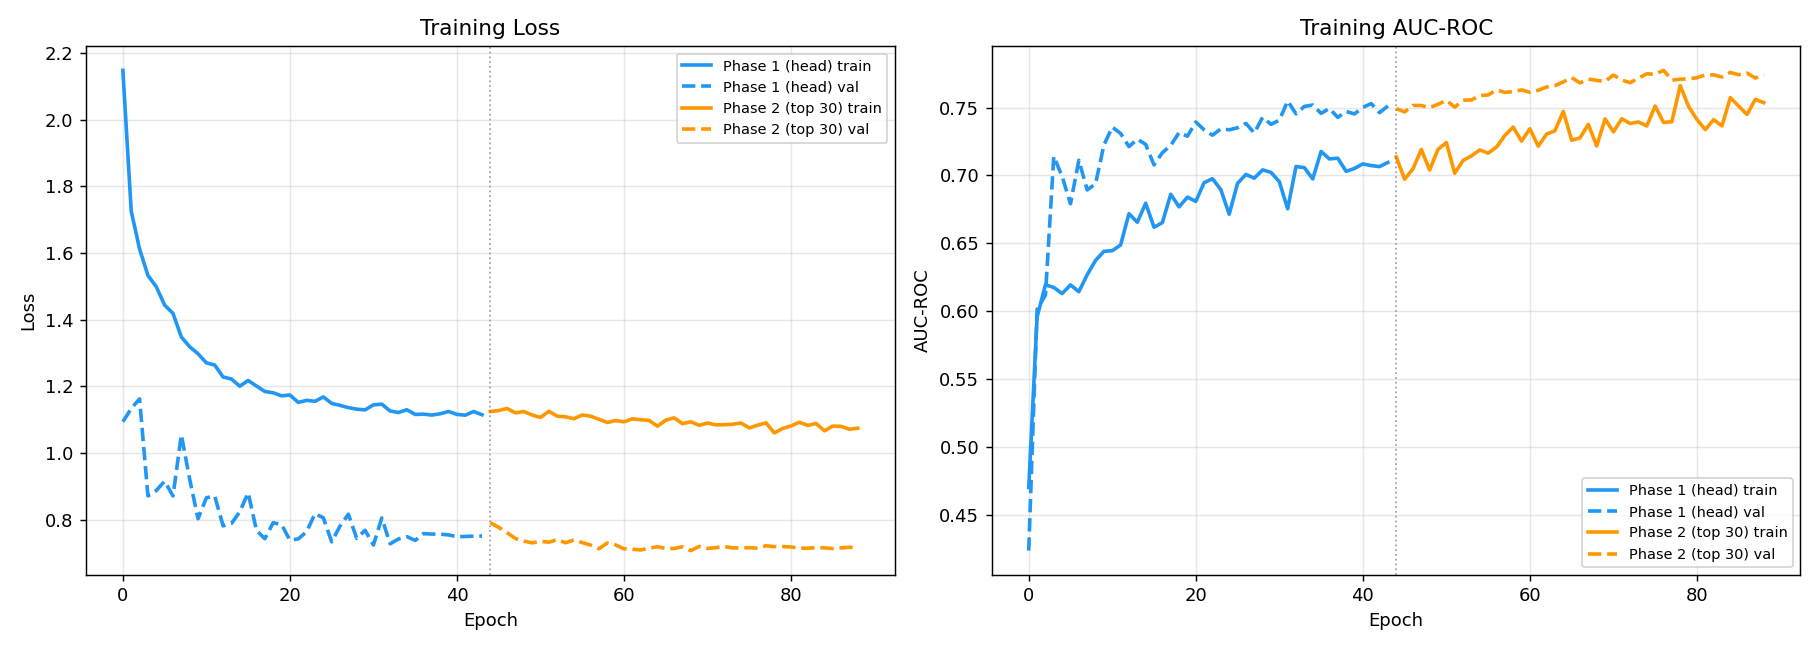


── confusion_matrices ──


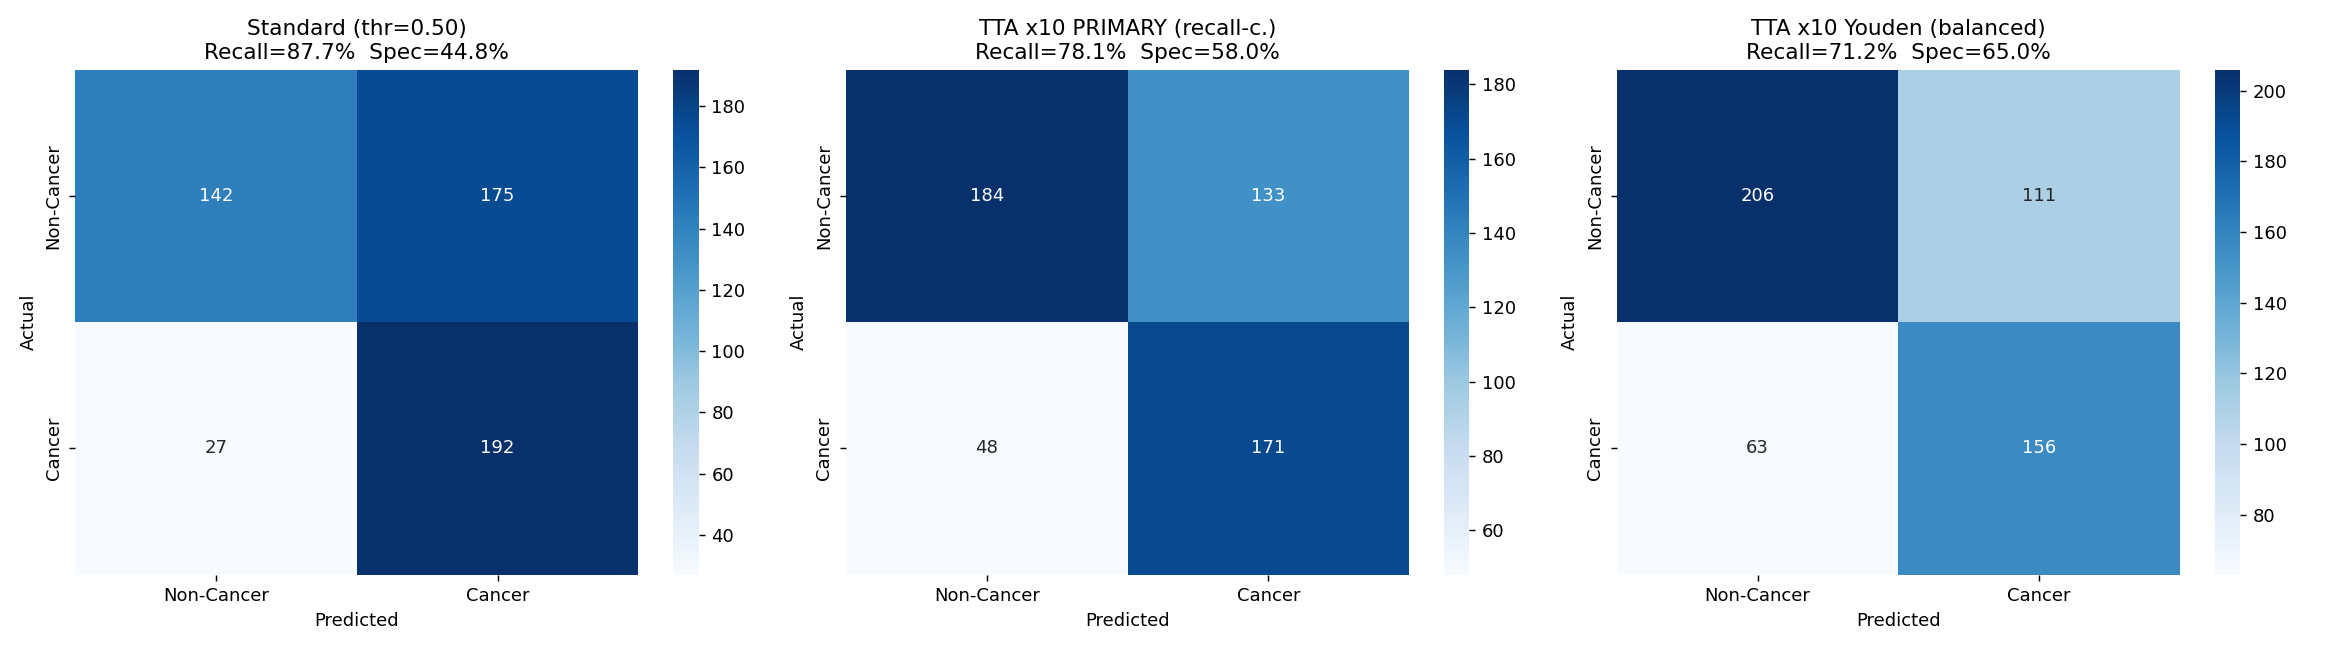


── roc_curve ──


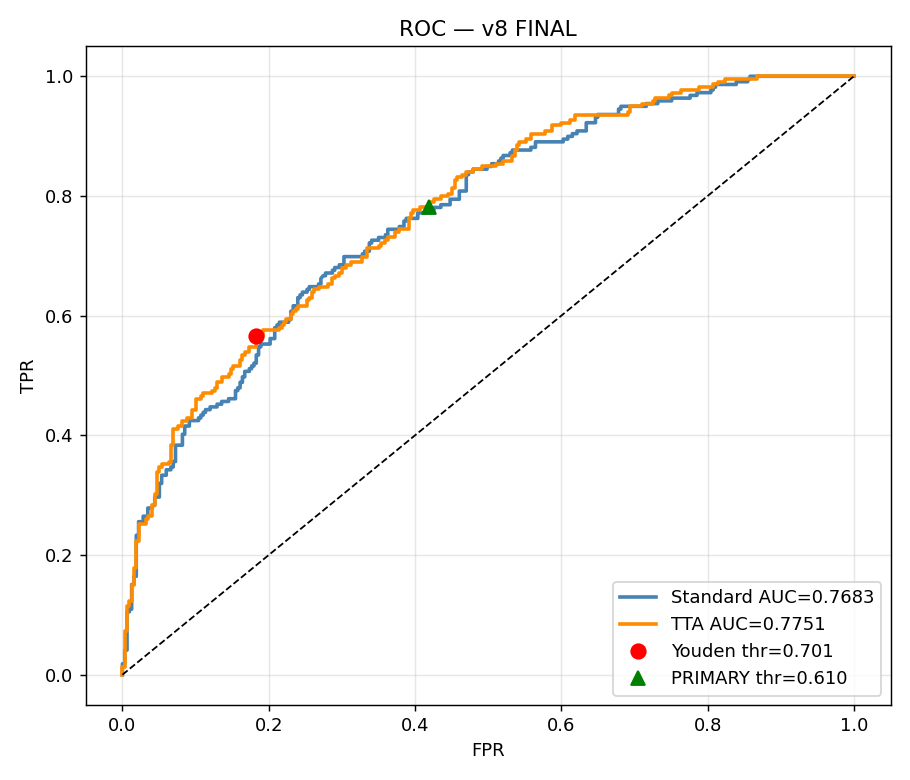


── score_distributions ──


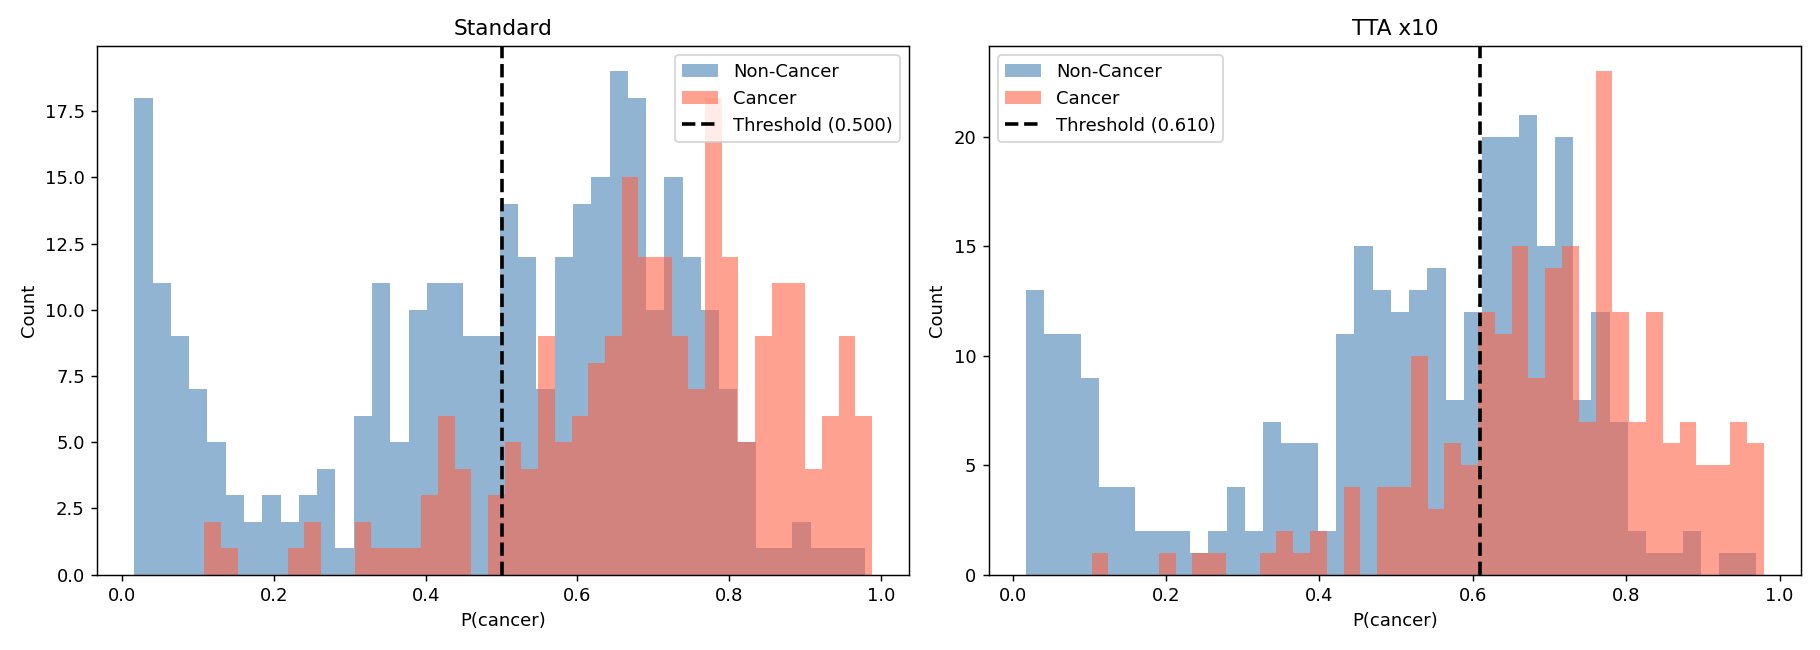


── precision_recall_curve ──


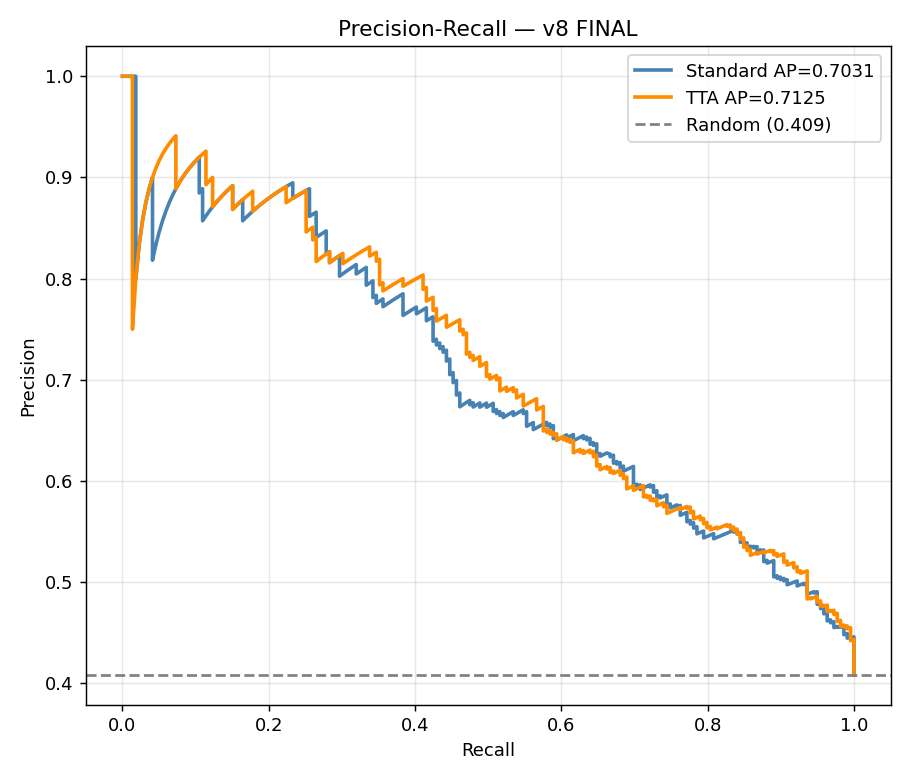

In [25]:
# Cell 12 — Display plots
from IPython.display import Image, display
import os
for plot in ['training_curves','confusion_matrices','roc_curve',
             'score_distributions','precision_recall_curve']:
    path = f'/kaggle/working/outputs/{plot}.png'
    if os.path.exists(path):
        print(f'\n── {plot} ──')
        display(Image(path))
    else:
        print(f'Missing: {path}')

In [26]:
# Cell 13 — Confirm outputs
import os, json
m = '/kaggle/working/models/breast_cancer_final.h5'
t = '/kaggle/working/models/optimal_threshold.json'
if os.path.exists(m):
    print(f'Model: {os.path.getsize(m)/1e6:.1f} MB')
if os.path.exists(t):
    d = json.load(open(t))
    print(f'Primary threshold   : {d["primary_threshold"]:.4f}')
    print(f'Youden threshold    : {d["youden_threshold"]:.4f}')
    print(f'Val sensitivity (P) : {d["val_sensitivity_primary"]:.4f}')
    print(f'Val specificity (P) : {d["val_specificity_primary"]:.4f}')

Model: 45.9 MB
Primary threshold   : 0.6100
Youden threshold    : 0.6382
Val sensitivity (P) : 0.8219
Val specificity (P) : 0.5949


In [27]:
# =============================== SETTINGS ===============================
QUICK_TEST = True   # True  = 30-45 minute check that every step works. Its numbers are NOT results.
                    # False = the real experiment (about 15-20 GPU hours, resumes across sessions).

SETTINGS = {
    # ---- data ----
    "input_dir": "/kaggle/input",              # folder that contains CBIS-DDSM (searched automatically)
    "out_dir": "/kaggle/working/sacgan_run",   # all progress and results (keep this name between sessions)
    "own_data_dir": "",                        # optional: your own data, <dir>/{train,val,test}/{benign,malignant}/
    "abnormality": "both",                     # CBIS-DDSM lesions: "both", "mass" or "calc"
    "img_size": 256,                           # multiple of 16; 256 is easier for the GAN than 320
    "clahe": True,                             # CLAHE contrast enhancement (OpenCV)
    # ---- GANs ----
    "gan_variants": ["sacgan", "cgan"],        # "cgan" = no self-attention (ablation); remove it to save ~4-5 h
    "gan_epochs": 300,
    "gan_batch": 32,
    "lr_g": 1e-4,
    "lr_d": 4e-4,
    "z_dim": 128,
    "ema_decay": 0.999,
    "diffaugment": "translation,cutout,brightness,contrast",
    "fid_every": 10,                           # epochs between FID checks; the lowest-FID checkpoint is used
    "fid_images": 2000,
    # ---- synthetic images ----
    "gate_percentile": 95.0,                   # quality gate: at least as typical as 95% of real images
    "pool_factor": 3.0,                        # generate this many times the images needed, before the gate
    "ratios": [0.25, 0.5, 1.0],                # synthetic:real ratios compared on the validation set
    "ratio_search_epochs": 20,
    # ---- classifier ----
    "backbone": "resnet50",                    # "resnet50", "densenet121", "efficientnet_b0" or "table2_gap"
    "pretrained": True,                        # ImageNet weights (needs Internet on)
    "cls_epochs": 30,                          # stage 1: the configuration's own training set
    "finetune_epochs": 10,                     # stage 2: real training images only (0 = off)
    "finetune_lr_factor": 0.1,
    "cls_batch": 32,
    "cls_lr": 1e-4,                            # backbone learning rate; the new output layer uses 10x
    "weight_decay": 1e-2,
    "seeds": [0, 1, 2],
    # ---- session ----
    "time_budget_hours": 11.5,                 # Kaggle stops a session at 12 h
    "reserve_minutes": 15,
    "workers": 4,                              # CPU threads for data preparation
    "inception_pretrained": True,              # keep True (False only for offline code tests)
}

QUICK_TEST_OVERRIDES = {
    "out_dir": "/kaggle/working/sacgan_quicktest",
    "gan_epochs": 2, "fid_every": 1, "fid_images": 200, "pool_factor": 1.5,
    "ratios": [0.25, 0.5], "ratio_search_epochs": 1,
    "cls_epochs": 2, "finetune_epochs": 1, "seeds": [0],
    "time_budget_hours": 2.0,
}
# ========================================================================


In [28]:
# Environment check: confirms the GPU, internet and dataset are available. It changes nothing.
import glob
import os
import urllib.error
import urllib.request

import torch

print("PyTorch", torch.__version__)
gpu = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if gpu else "NONE")
try:
    urllib.request.urlopen("https://download.pytorch.org/models/", timeout=15)
    internet = True
except urllib.error.HTTPError:
    internet = True   # the server answered, so the connection works
except Exception:
    internet = False
print("Internet:", "on" if internet else "OFF")
found = [p for d in ("*", "*/*", "*/*/*", "*/*/*/*")
         for p in glob.glob(os.path.join(SETTINGS["input_dir"], d, "csv", "dicom_info.csv"))]
print("CBIS-DDSM:", found[0] if found else ("not needed (own data)" if SETTINGS["own_data_dir"] else "NOT FOUND"))

problems = []
if not gpu:
    problems.append("No GPU: Settings -> Accelerator -> GPU T4 x2 (or P100).")
if not internet:
    problems.append("Internet is off: Settings -> Internet -> On.")
if not found and not SETTINGS["own_data_dir"]:
    problems.append("CBIS-DDSM not attached: Add Input -> search 'CBIS-DDSM Breast Cancer Image Dataset'.")
for p in problems:
    print("PROBLEM:", p)
if problems:
    raise SystemExit("Fix the problems above, then run again.")
print("Everything needed is available.")


PyTorch 2.10.0+cu128
GPU: Tesla T4
Internet: on
CBIS-DDSM: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/csv/dicom_info.csv
Everything needed is available.


In [29]:
import contextlib
import copy
import csv
import glob
import json
import math
import os
import random
import shutil
import sys
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from types import SimpleNamespace

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

try:
    import cv2
except ImportError:  # CLAHE is skipped without OpenCV
    cv2 = None

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

T_START = time.time()
SPLITS = ("train", "val", "test")
IMG_EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp", ".pgm")
GAN_NAMES_4 = ["benign_mass", "benign_calc", "malignant_mass", "malignant_calc"]
GAN_NAMES_2 = ["benign", "malignant"]
GAN_LABELS = {"sacgan": "SA-cGAN", "cgan": "cGAN (no self-attention)"}

# name, label in tables and figures, training-set recipe
#   real  : include the real training images
#   synth : synthetic set ("<gan>_gated" passed the quality gate, "<gan>_ungated" did not go through it)
#   aff   : on-the-fly affine + intensity augmentation (otherwise flips only)
#   count : "ratio" = synthetic:real ratio chosen on validation, "full" = as many as the real images
CONFIGS = [
    ("set1_org", "Set 1 (ORG)",
     dict(real=True, synth=None, aff=False, count=None)),
    ("set5_org_aff", "Set 5 (ORG+AFF)",
     dict(real=True, synth=None, aff=True, count=None)),
    ("set7_sacgan", "Set 7 (SA-cGAN only)",
     dict(real=False, synth="sacgan_gated", aff=False, count="full")),
    ("set8_org_sacgan", "Set 8 (ORG+SA-cGAN), proposed",
     dict(real=True, synth="sacgan_gated", aff=False, count="ratio")),
    ("set9_org_aff_sacgan", "Set 9 (ORG+AFF+SA-cGAN)",
     dict(real=True, synth="sacgan_gated", aff=True, count="ratio")),
    ("abl_no_gate", "Ablation: ORG+SA-cGAN, no gate",
     dict(real=True, synth="sacgan_ungated", aff=False, count="ratio")),
    ("abl_cgan", "Ablation: ORG+cGAN, no self-attn",
     dict(real=True, synth="cgan_gated", aff=False, count="ratio")),
]
PROPOSED = "set8_org_sacgan"


class OutOfTime(Exception):
    """The session's time budget is nearly used up; progress has been saved."""

In [30]:
def read_json(path, default=None):
    try:
        with open(path) as f:
            return json.load(f)
    except (OSError, ValueError):
        return default


def write_json(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    os.replace(tmp, path)


def save_npz(path, **arrays):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        np.savez(f, **arrays)
    os.replace(tmp, path)


def torch_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def trim_csv(path, start_epoch, header):
    """Keep only rows logged before `start_epoch` (used when resuming)."""
    kept = []
    if start_epoch > 1 and os.path.exists(path):
        with open(path, newline="") as f:
            kept = [r for r in list(csv.reader(f))[1:] if r and int(float(r[0])) < start_epoch]
    with open(path, "w", newline="") as f:
        csv.writer(f).writerows([header] + kept)


def append_csv(path, row):
    with open(path, "a", newline="") as f:
        csv.writer(f).writerow(row)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def cpu_state(model):
    return {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}


def free_gpu():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def autocast_ctx(amp):
    return torch.autocast(device_type="cuda", dtype=torch.float16) if amp else contextlib.nullcontext()


def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def tile(images, ncol, gap=2):
    """uint8 (N,H,W) -> one uint8 mosaic image."""
    n, h, w = images.shape
    nrow = math.ceil(n / ncol)
    canvas = np.full((nrow * h + (nrow - 1) * gap, ncol * w + (ncol - 1) * gap), 255, np.uint8)
    for i, im in enumerate(images):
        r, c = divmod(i, ncol)
        canvas[r * (h + gap):r * (h + gap) + h, c * (w + gap):c * (w + gap) + w] = im
    return canvas


class Run:
    """Settings, output paths, device and the session's time budget."""

    def __init__(self, cfg):
        self.cfg = cfg
        self.out = cfg["out_dir"]
        os.makedirs(self.out, exist_ok=True)
        self.dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        if self.dev.type == "cuda":
            torch.backends.cudnn.benchmark = True
        self.deadline = T_START + cfg["time_budget_hours"] * 3600 - cfg["reserve_minutes"] * 60
        self._inception = None
        self.ref = None
        self.synth_cache = {}

    def p(self, *parts):
        return os.path.join(self.out, *parts)

    def dir(self, *parts):
        path = self.p(*parts)
        os.makedirs(path, exist_ok=True)
        return path

    def left(self):
        return self.deadline - time.time()

    def need(self, seconds, what):
        if self.left() < seconds:
            raise OutOfTime(what)

    def log(self, msg):
        line = f"[{(time.time() - T_START) / 60:6.1f} min] {msg}"
        print(line, flush=True)
        with open(self.p("log.txt"), "a") as f:
            f.write(line + "\n")

    def inception(self):
        if self._inception is None:
            self._inception = InceptionFeatures(self.dev, self.cfg["inception_pretrained"])
        return self._inception

In [31]:
SKIP_DIRS = {"jpeg", "jpg", "dicom", "images"}


def find_file(root, name, max_depth=5):
    """Find `name` under root without walking the large image folders."""
    base = root.rstrip(os.sep).count(os.sep)
    for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
        if name in filenames:
            return os.path.join(dirpath, name)
        if dirpath.count(os.sep) - base >= max_depth:
            dirnames[:] = []
        dirnames[:] = sorted(d for d in dirnames if d.lower() not in SKIP_DIRS)
    return None


def resolve_paths(rel_paths, ds_root):
    """Map dicom_info image_path values (e.g. CBIS-DDSM/jpeg/<uid>/1-2.jpg) to real files."""
    def direct(p):
        parts = str(p).strip().replace("\\", "/").split("/")
        if parts and parts[0].upper() == "CBIS-DDSM":
            parts = parts[1:]
        return os.path.join(ds_root, *parts)

    paths = rel_paths.map(direct)
    found = paths.map(os.path.exists)
    if found.mean() >= 0.9:
        return paths.where(found)
    print(f"Only {found.mean():.0%} of image paths exist as written; indexing the image files instead")
    index = {}
    for dirpath, _, filenames in os.walk(ds_root, followlinks=True):
        for fn in filenames:
            if fn.lower().endswith((".jpg", ".jpeg", ".png")):
                index[os.path.basename(dirpath) + "/" + fn] = os.path.join(dirpath, fn)
    key = rel_paths.map(lambda p: "/".join(str(p).strip().replace("\\", "/").split("/")[-2:]))
    return key.map(index.get)


def load_cases(csv_dir):
    """Lesion key -> pathology, from the mass/calc train/test case-description CSVs."""
    files = sorted(glob.glob(os.path.join(csv_dir, "*case_description*.csv")))
    if not files:
        raise SystemExit(f"No *case_description*.csv files found in {csv_dir}")
    out = []
    for f in files:
        d = pd.read_csv(f)
        d.columns = [c.strip() for c in d.columns]
        lower = {c.lower(): c for c in d.columns}
        crop_col = next((c for c in d.columns if "cropped" in c.lower()), None)
        if crop_col is not None:
            key = d[crop_col].astype(str).str.strip().str.split("/").str[0]
        else:  # rebuild the folder name, e.g. Mass-Training_P_00001_LEFT_CC_1
            name = os.path.basename(f).lower()
            prefix = ("Mass" if name.startswith("mass") else "Calc") + ("-Test" if "test" in name else "-Training")
            key = (prefix + "_" + d[lower["patient_id"]].astype(str) + "_"
                   + d[lower["left or right breast"]].astype(str) + "_" + d[lower["image view"]].astype(str)
                   + "_" + d[lower["abnormality id"]].astype(str))
        out.append(pd.DataFrame({"key": key.str.strip(),
                                 "pathology": d[lower["pathology"]].astype(str).str.strip()}))
    return pd.concat(out).drop_duplicates("key")


def inspect_image(path):
    """'crop', 'mask' or 'error'. CBIS-DDSM stores crops and binary masks in the same series,
    and their labels are sometimes swapped, so the pixels decide."""
    try:
        img = Image.open(path)
        img.draft("L", (512, 512))
        a = np.asarray(img.convert("L"))
        if a.size == 0:
            return "error"
        extreme = ((a <= 10) | (a >= 245)).mean()
        return "mask" if extreme > 0.9 or len(np.unique(a)) <= 2 else "crop"
    except Exception:
        return "error"


def load_gray_any(path):
    img = Image.open(path)
    if img.mode in ("I;16", "I;16B", "I;16L", "I", "F"):  # 16-bit: rescale instead of clipping
        a = np.asarray(img, dtype=np.float32)
        lo, hi = float(a.min()), float(a.max())
        return ((a - lo) / (hi - lo + 1e-8) * 255.0).astype(np.uint8)
    return np.asarray(img.convert("L"), dtype=np.uint8)


def preprocess(path, size, clahe):
    try:
        a = load_gray_any(path)
        a = np.asarray(Image.fromarray(a).resize((size, size), Image.LANCZOS), dtype=np.uint8)
        if clahe:
            a = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(a)
        return a
    except Exception:
        return None


def cbis_rows(R):
    c = R.cfg
    info_csv = find_file(c["input_dir"], "dicom_info.csv")
    if info_csv is None:
        raise SystemExit(f"dicom_info.csv not found under {c['input_dir']}. "
                         "Add the 'CBIS-DDSM Breast Cancer Image Dataset' as an input.")
    csv_dir = os.path.dirname(info_csv)
    ds_root = os.path.dirname(csv_dir)
    R.log(f"CBIS-DDSM found at {ds_root}")
    info = pd.read_csv(info_csv)
    need = {"image_path", "PatientID", "SeriesDescription"}
    if need - set(info.columns):
        raise SystemExit(f"dicom_info.csv lacks columns {sorted(need - set(info.columns))}; "
                         f"it has {list(info.columns)}")
    desc = info["SeriesDescription"].astype(str).str.lower()
    cand = info[~desc.str.contains("full")].copy()          # crops and masks, not full mammograms
    cand["key"] = cand["PatientID"].astype(str).str.strip()
    cand["src"] = resolve_paths(cand["image_path"], ds_root)
    cand = cand.dropna(subset=["src"]).drop_duplicates("src")
    cases = load_cases(csv_dir)
    df = cand.merge(cases, on="key", how="inner")
    R.log(f"{len(cases)} lesions in the case CSVs; {df['key'].nunique()} matched to image files")
    if df.empty:
        raise SystemExit("No lesion matched an image file. Example keys - dicom_info: "
                         f"{cand['key'].head(3).tolist()}, case CSVs: {cases['key'].head(3).tolist()}")
    with ThreadPoolExecutor(max(1, c["workers"])) as ex:
        df["kind"] = list(ex.map(inspect_image, df["src"].tolist()))
    crops = df[df["kind"] == "crop"].sort_values(["key", "src"]).drop_duplicates("key").copy()
    R.log(f"checked {len(df)} candidate images: {(df['kind'] == 'crop').sum()} crops, "
          f"{(df['kind'] == 'mask').sum()} masks, {(df['kind'] == 'error').sum()} unreadable; "
          f"{len(crops)} lesions have a usable crop")
    crops["abnormality"] = np.where(crops["key"].str.lower().str.startswith("mass"), "mass", "calc")
    if c["abnormality"] != "both":
        crops = crops[crops["abnormality"] == c["abnormality"]]
    crops["label"] = np.where(crops["pathology"].str.upper().str.startswith("MALIGNANT"), 1, 0)
    crops["patient"] = crops["key"].str.extract(r"(P_\d+)", expand=False)
    crops = crops.dropna(subset=["patient"]).reset_index(drop=True)

    # patient-level split, stratified by pathology x lesion type: test ~1/7, val ~1/6 of the rest
    from sklearn.model_selection import StratifiedGroupKFold
    strat = (crops["label"] * 2 + (crops["abnormality"] == "calc")).to_numpy()
    groups = crops["patient"].to_numpy()
    rest, test = next(StratifiedGroupKFold(7, shuffle=True, random_state=0).split(crops, strat, groups))
    tr, va = next(StratifiedGroupKFold(6, shuffle=True, random_state=0).split(rest, strat[rest], groups[rest]))
    crops["split"] = "train"
    crops.loc[rest[va], "split"] = "val"
    crops.loc[test, "split"] = "test"
    pats = {s: set(crops.loc[crops["split"] == s, "patient"]) for s in SPLITS}
    assert not (pats["train"] & pats["val"] or pats["train"] & pats["test"] or pats["val"] & pats["test"])
    return crops[["key", "patient", "abnormality", "pathology", "label", "split", "src"]]


def own_data_rows(R):
    root, rows = R.cfg["own_data_dir"], []
    for s in SPLITS:
        for lab, cls in enumerate(GAN_NAMES_2):
            d = os.path.join(root, s, cls)
            files = sorted(f for f in glob.glob(os.path.join(d, "*")) if f.lower().endswith(IMG_EXTS))
            if not files:
                raise SystemExit(f"No images in {d}")
            rows += [dict(key=os.path.basename(f), patient="", abnormality="unknown", pathology=cls.upper(),
                          label=lab, split=s, src=f) for f in files]
    R.log(f"Using your own data in {root}. Make sure no patient appears in two splits.")
    return pd.DataFrame(rows)


def prepare_data(R):
    c = R.cfg
    out = R.p("data", "dataset.npz")
    if os.path.exists(out):
        R.log("Data already prepared.")
        return
    R.dir("data")
    use_clahe = bool(c["clahe"]) and cv2 is not None
    if c["clahe"] and cv2 is None:
        R.log("WARNING: OpenCV (cv2) is not installed, so CLAHE is skipped.")
    rows = own_data_rows(R) if c["own_data_dir"] else cbis_rows(R)
    size = c["img_size"]
    R.log(f"Preprocessing {len(rows)} images to {size}x{size}{' with CLAHE' if use_clahe else ''} ...")
    with ThreadPoolExecutor(max(1, c["workers"])) as ex:
        imgs = list(ex.map(lambda s: preprocess(s, size, use_clahe), rows["src"].tolist()))
    ok = np.array([a is not None for a in imgs])
    if (~ok).any():
        R.log(f"{int((~ok).sum())} images could not be read and were left out")
    rows = rows[ok].reset_index(drop=True)
    X = np.stack([a for a in imgs if a is not None])
    ltype = rows["abnormality"].map({"mass": 0, "calc": 1}).fillna(-1).astype(np.int8).to_numpy()
    split = rows["split"].map({s: i for i, s in enumerate(SPLITS)}).astype(np.int8).to_numpy()
    save_npz(out, images=X, label=rows["label"].astype(np.int8).to_numpy(), ltype=ltype, split=split)
    rows.to_csv(R.p("data", "manifest.csv"), index=False)
    tab = pd.crosstab(rows["split"], [rows["label"].map({0: "benign", 1: "malignant"}), rows["abnormality"]],
                      margins=True)
    R.log("Images per split:\n" + tab.to_string())
    if rows["patient"].astype(str).str.len().gt(0).all():
        R.log("Patients per split: " + str({s: rows.loc[rows["split"] == s, "patient"].nunique() for s in SPLITS})
              + " - no patient is in two splits")


class Data:
    def __init__(self, path):
        z = np.load(path)
        self.X = z["images"]
        self.y = z["label"].astype(np.int64)
        self.t = z["ltype"].astype(np.int64)
        self.split = z["split"].astype(np.int64)
        self.four = bool((self.t >= 0).all() and len(np.unique(self.t)) == 2)
        self.gan_names = GAN_NAMES_4 if self.four else GAN_NAMES_2
        self.n_gan = len(self.gan_names)
        self.g = self.y * 2 + self.t if self.four else self.y.copy()

    def part(self, name):
        i = np.where(self.split == SPLITS.index(name))[0]
        return self.X[i], self.y[i], self.g[i]

    def label_of(self, g):
        g = np.asarray(g)
        return g // 2 if self.four else g

In [32]:
def SN(module):
    return nn.utils.parametrizations.spectral_norm(module)


class SelfAttention(nn.Module):
    """SAGAN self-attention; keys/values 2x2 max-pooled. gamma starts at 0."""

    def __init__(self, ch):
        super().__init__()
        self.q = SN(nn.Conv2d(ch, ch // 8, 1, bias=False))
        self.k = SN(nn.Conv2d(ch, ch // 8, 1, bias=False))
        self.v = SN(nn.Conv2d(ch, ch // 2, 1, bias=False))
        self.o = SN(nn.Conv2d(ch // 2, ch, 1, bias=False))
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        b, c, h, w = x.shape
        q = self.q(x).flatten(2).transpose(1, 2)
        k = F.max_pool2d(self.k(x), 2).flatten(2)
        v = F.max_pool2d(self.v(x), 2).flatten(2)
        attn = torch.softmax(torch.bmm(q, k), dim=-1)
        out = torch.bmm(v, attn.transpose(1, 2)).view(b, c // 2, h, w)
        return x + self.gamma * self.o(out)


class CondBN(nn.Module):
    """Batch norm whose scale and shift depend on the class."""

    def __init__(self, ch, n_classes):
        super().__init__()
        self.bn = nn.BatchNorm2d(ch, affine=False)
        self.gamma = nn.Embedding(n_classes, ch)
        self.beta = nn.Embedding(n_classes, ch)
        nn.init.ones_(self.gamma.weight)
        nn.init.zeros_(self.beta.weight)

    def forward(self, x, y):
        return self.gamma(y)[:, :, None, None] * self.bn(x) + self.beta(y)[:, :, None, None]


class GenBlock(nn.Module):
    def __init__(self, cin, cout, n_classes):
        super().__init__()
        self.cbn = CondBN(cin, n_classes)
        self.conv = SN(nn.Conv2d(cin, cout, 3, padding=1))

    def forward(self, x, y):
        return F.relu(self.conv(F.interpolate(self.cbn(x, y), scale_factor=2, mode="nearest")))


G_CH = [(256, 256), (256, 128), (128, 64), (64, 32)]
D_CH = [(1, 32), (32, 64), (64, 128), (128, 256)]


class Generator(nn.Module):
    """Table 1 generator layout scaled to img_size: z + class embedding -> 256 x S/16 x S/16,
    four up-sampling blocks, self-attention at S/8 (SA-cGAN only), 1-channel tanh output."""

    def __init__(self, img_size, z_dim, n_classes, attention, emb_dim=128):
        super().__init__()
        self.b = img_size // 16
        self.embed = nn.Embedding(n_classes, emb_dim)
        self.fc = SN(nn.Linear(z_dim + emb_dim, 256 * self.b * self.b))
        self.blocks = nn.ModuleList(GenBlock(a, o, n_classes) for a, o in G_CH)
        self.attn = SelfAttention(G_CH[0][1]) if attention else None
        self.out_bn = CondBN(G_CH[-1][1], n_classes)
        self.out_conv = SN(nn.Conv2d(G_CH[-1][1], 1, 3, padding=1))

    def forward(self, z, y):
        h = F.relu(self.fc(torch.cat([z, self.embed(y)], 1))).view(-1, 256, self.b, self.b)
        for i, blk in enumerate(self.blocks):
            h = blk(h, y)
            if i == 0 and self.attn is not None:
                h = self.attn(h)
        return torch.tanh(self.out_conv(self.out_bn(h, y)))


class Discriminator(nn.Module):
    """Table 1 discriminator with spectral norm, self-attention at S/8 (SA-cGAN only)
    and a projection head; returns a raw score for the hinge loss."""

    def __init__(self, img_size, n_classes, attention, dropout=0.25):
        super().__init__()
        b = img_size // 16
        self.convs = nn.ModuleList(SN(nn.Conv2d(a, o, 3, padding=1)) for a, o in D_CH)
        self.attn = SelfAttention(D_CH[2][1]) if attention else None
        self.drop = nn.Dropout(dropout)
        feat = 256 * b * b
        self.fc = SN(nn.Linear(feat, 1))
        self.embed = SN(nn.Embedding(n_classes, feat))

    def forward(self, x, y):
        h = x
        for i, conv in enumerate(self.convs):
            h = self.drop(F.max_pool2d(F.relu(conv(h)), 2))
            if i == 2 and self.attn is not None:
                h = self.attn(h)
        h = h.flatten(1)
        return self.fc(h).squeeze(1) + (self.embed(y) * h).sum(1)


# ---- DiffAugment (Zhao et al., 2020): the same random, differentiable transform
#      is applied to real and generated images before the discriminator sees them
def _da_brightness(x):
    return x + (torch.rand(x.size(0), 1, 1, 1, dtype=x.dtype, device=x.device) - 0.5)


def _da_contrast(x):
    m = x.mean(dim=[1, 2, 3], keepdim=True)
    return (x - m) * (torch.rand(x.size(0), 1, 1, 1, dtype=x.dtype, device=x.device) + 0.5) + m


def _da_translation(x, ratio=0.125):
    b, _, h, w = x.shape
    sh, sw = int(h * ratio + 0.5), int(w * ratio + 0.5)
    tx = torch.randint(-sh, sh + 1, size=[b, 1, 1], device=x.device)
    ty = torch.randint(-sw, sw + 1, size=[b, 1, 1], device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(b, device=x.device), torch.arange(h, device=x.device),
                                torch.arange(w, device=x.device), indexing="ij")
    gx = torch.clamp(gx + tx + 1, 0, h + 1)
    gy = torch.clamp(gy + ty + 1, 0, w + 1)
    xp = F.pad(x, [1, 1, 1, 1, 0, 0, 0, 0])
    return xp.permute(0, 2, 3, 1).contiguous()[gb, gx, gy].permute(0, 3, 1, 2)


def _da_cutout(x, ratio=0.5):
    b, _, h, w = x.shape
    ch, cw = int(h * ratio + 0.5), int(w * ratio + 0.5)
    ox = torch.randint(0, h + (1 - ch % 2), size=[b, 1, 1], device=x.device)
    oy = torch.randint(0, w + (1 - cw % 2), size=[b, 1, 1], device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(b, device=x.device), torch.arange(ch, device=x.device),
                                torch.arange(cw, device=x.device), indexing="ij")
    gx = torch.clamp(gx + ox - ch // 2, 0, h - 1)
    gy = torch.clamp(gy + oy - cw // 2, 0, w - 1)
    mask = torch.ones(b, h, w, dtype=x.dtype, device=x.device)
    mask[gb, gx, gy] = 0
    return x * mask.unsqueeze(1)


DA_FUNCS = {"brightness": _da_brightness, "contrast": _da_contrast,
            "translation": _da_translation, "cutout": _da_cutout}


def diff_augment(x, policy):
    for name in [p.strip() for p in policy.split(",") if p.strip()]:
        x = DA_FUNCS[name](x)
    return x


def random_flips(x):
    """Independent random horizontal and vertical flips per image (lesion ROIs have no fixed orientation)."""
    b = x.size(0)
    m = (torch.rand(b, device=x.device) < 0.5)[:, None, None, None]
    x = torch.where(m, x.flip(3), x)
    m = (torch.rand(b, device=x.device) < 0.5)[:, None, None, None]
    return torch.where(m, x.flip(2), x)


@torch.no_grad()
def update_ema(ema, model, decay):
    for pe, pm in zip(ema.parameters(), model.parameters()):
        pe.lerp_(pm, 1.0 - decay)
    for be, bm in zip(ema.buffers(), model.buffers()):
        be.copy_(bm)


@torch.no_grad()
def generate(G, labels, z_dim, dev, seed, bs=64):
    """Images for the given class labels, as uint8 (N, S, S)."""
    G.eval()
    g = torch.Generator().manual_seed(seed)
    out = []
    for i in range(0, len(labels), bs):
        y = torch.as_tensor(np.asarray(labels[i:i + bs]), dtype=torch.long, device=dev)
        z = torch.randn(len(y), z_dim, generator=g).to(dev)
        x = G(z, y)[:, 0]
        out.append(((x * 0.5 + 0.5).clamp(0, 1) * 255).round().to(torch.uint8).cpu().numpy())
    return np.concatenate(out)


# ---- Inception features, FID and the quality-gate scores
class InceptionFeatures:
    """2048-d pool features of torchvision's Inception-v3. FID values from it are only
    comparable within this study (not with FID numbers computed by other code)."""

    def __init__(self, dev, pretrained):
        from torchvision.models import inception_v3
        if pretrained:
            from torchvision.models import Inception_V3_Weights
            try:
                net = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1)
            except Exception as e:
                raise SystemExit("Could not download the Inception-v3 weights. On Kaggle: "
                                 "Settings -> Internet -> On, then run again.") from e
        else:  # code tests only: random weights make FID and the gate meaningless
            with torch.random.fork_rng(devices=[]):
                torch.manual_seed(0)
                net = inception_v3(weights=None, aux_logits=True, init_weights=True)
        net.fc = nn.Identity()
        self.net = net.eval().to(dev)
        self.dev = dev
        self.mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

    @torch.no_grad()
    def from_u8(self, X, bs=64):
        out = []
        for i in range(0, len(X), bs):
            x = torch.as_tensor(np.asarray(X[i:i + bs])).to(self.dev).float().div(255).unsqueeze(1)
            x = F.interpolate(x.expand(-1, 3, -1, -1), size=(299, 299), mode="bilinear", align_corners=False)
            out.append(self.net((x - self.mean) / self.std).double().cpu().numpy())
        return np.concatenate(out)


def _sqrt_psd(s):
    w, v = np.linalg.eigh(s)
    return (v * np.sqrt(np.clip(w, 0, None))) @ v.T


def fid_vs_ref(ref, f2):
    """Frechet distance to the real-training-image statistics (stable for rank-deficient covariances)."""
    if len(f2) < 2:
        return float("nan")
    mu2, s2 = f2.mean(0), np.cov(f2, rowvar=False)
    m = ref.sqrt @ s2 @ ref.sqrt
    tr = np.sqrt(np.clip(np.linalg.eigvalsh((m + m.T) / 2), 0, None)).sum()
    return max(0.0, float(((ref.mu - mu2) ** 2).sum() + np.trace(ref.sigma) + np.trace(s2) - 2 * tr))


def gray_hists(X):
    return np.stack([np.bincount(x.ravel(), minlength=256) for x in X]).astype(np.float64) / X[0].size


def wasserstein_1d(h, ref_hist):
    """W1 distance between grey-level histograms (in units of the full grey range)."""
    return np.abs(np.cumsum(h, axis=-1) - np.cumsum(ref_hist)).sum(axis=-1) / 256.0


def mahalanobis(f, mu, prec):
    d = f - mu
    return np.sqrt(np.maximum(((d @ prec) * d).sum(1), 0.0))


def real_reference(R, data):
    """Inception features, histograms and FID statistics of the REAL TRAINING images."""
    if R.ref is not None:
        return R.ref
    Xtr, _, gtr = data.part("train")
    path = R.p("gan", "real_train_inception_features.npy")
    feats = np.load(path) if os.path.exists(path) else None
    if feats is None or len(feats) != len(Xtr):
        R.log("Computing Inception-v3 features of the real training images ...")
        feats = R.inception().from_u8(Xtr).astype(np.float32)
        R.dir("gan")
        with open(path + ".tmp", "wb") as f:
            np.save(f, feats)
        os.replace(path + ".tmp", path)
    feats = feats.astype(np.float64)
    sigma = np.cov(feats, rowvar=False)
    R.ref = SimpleNamespace(feats=feats, g=gtr, hists=gray_hists(Xtr), mu=feats.mean(0),
                            sigma=sigma, sqrt=_sqrt_psd(sigma))
    return R.ref


def gan_fid(R, G_ema, class_p, ref, n):
    counts = np.floor(class_p * n).astype(int)
    counts[np.argmax(class_p)] += n - counts.sum()
    labels = np.repeat(np.arange(len(class_p)), counts)
    imgs = generate(G_ema, labels, R.cfg["z_dim"], R.dev, seed=777)
    return fid_vs_ref(ref, R.inception().from_u8(imgs))


def train_gan(R, data, variant):
    c, dev = R.cfg, R.dev
    d = R.dir("gan", variant)
    E = c["gan_epochs"]
    status = read_json(os.path.join(d, "status.json"), {})
    last_path, best_path = os.path.join(d, "last.pt"), os.path.join(d, "best.pt")
    if status.get("done") and status.get("epochs") == E and os.path.exists(best_path):
        R.log(f"{GAN_LABELS[variant]}: already trained ({E} epochs, best FID "
              f"{status.get('best_fid')} at epoch {status.get('best_epoch')}).")
        return
    R.need(600, f"too little time left to continue {GAN_LABELS[variant]} training")
    use_fid = c["fid_every"] > 0
    if use_fid:  # build Inception and the real statistics BEFORE seeding, so they never shift the random stream
        ref = real_reference(R, data)
        R.inception()
    Xtr, _, gtr = data.part("train")
    n_cls, attention = data.n_gan, variant == "sacgan"
    set_seed(1 if attention else 2)
    G = Generator(c["img_size"], c["z_dim"], n_cls, attention).to(dev)
    D = Discriminator(c["img_size"], n_cls, attention).to(dev)
    G_ema = copy.deepcopy(G).eval()
    for p_ in G_ema.parameters():
        p_.requires_grad_(False)
    optG = torch.optim.Adam(G.parameters(), lr=c["lr_g"], betas=(0.0, 0.9))
    optD = torch.optim.Adam(D.parameters(), lr=c["lr_d"], betas=(0.0, 0.9))
    start, best_fid, best_epoch = 1, float("inf"), 0
    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location="cpu", weights_only=False)
        for m, k in ((G, "G"), (D, "D"), (G_ema, "G_ema"), (optG, "optG"), (optD, "optD")):
            m.load_state_dict(ck[k])
        start, best_fid, best_epoch = ck["epoch"] + 1, ck["best_fid"], ck["best_epoch"]
        torch.set_rng_state(ck["rng_cpu"])
        if dev.type == "cuda" and ck.get("rng_cuda") is not None:
            torch.cuda.set_rng_state_all(ck["rng_cuda"])
        R.log(f"{GAN_LABELS[variant]}: resumed after epoch {ck['epoch']}")
    log_path, fid_path = os.path.join(d, "train_log.csv"), os.path.join(d, "fid.csv")
    trim_csv(log_path, start, ["epoch", "loss_d", "loss_g", "d_real", "d_fake", "sec"])
    trim_csv(fid_path, start, ["epoch", "fid"])
    X = torch.from_numpy(Xtr).to(dev)
    Y = torch.from_numpy(gtr).to(dev)
    N = len(X)
    bs = min(c["gan_batch"], N)
    nb = N // bs
    class_p = np.bincount(gtr, minlength=n_cls) / N
    fixed_y = np.repeat(np.arange(n_cls), 8)  # sample grid: one row of 8 per class, same noise every time
    policy = c["diffaugment"]
    R.dir("gan", variant, "samples")
    R.log(f"{GAN_LABELS[variant]}: {N} real training images, classes {data.gan_names}, "
          f"epochs {start}-{E}, batch {bs} ({nb} steps/epoch), DiffAugment '{policy}'")

    def save(epoch):
        torch_save({"G": G.state_dict(), "D": D.state_dict(), "G_ema": G_ema.state_dict(),
                    "optG": optG.state_dict(), "optD": optD.state_dict(), "epoch": epoch,
                    "best_fid": best_fid, "best_epoch": best_epoch, "rng_cpu": torch.get_rng_state(),
                    "rng_cuda": torch.cuda.get_rng_state_all() if dev.type == "cuda" else None}, last_path)
        write_json(os.path.join(d, "status.json"),
                   {"epoch": epoch, "epochs": E, "done": epoch >= E and os.path.exists(best_path),
                    "best_fid": None if math.isinf(best_fid) else best_fid, "best_epoch": best_epoch})

    ref = R.ref if use_fid else None
    sec_hist, fid_cost = [], 0.0
    for epoch in range(start, E + 1):
        fid_due = use_fid and (epoch % c["fid_every"] == 0 or epoch == E)
        est = (np.mean(sec_hist[-3:]) * 1.3 if sec_hist else 0.0) + (fid_cost * 1.5 if fid_due else 0.0) + 60
        if R.left() < est:
            if epoch > start:
                save(epoch - 1)
            raise OutOfTime(f"{GAN_LABELS[variant]} paused after epoch {epoch - 1}/{E}")
        G.train()
        D.train()
        t0 = time.time()
        tot = torch.zeros(4, device=dev)
        perm = torch.randperm(N, device=dev)
        for i in range(nb):
            idx = perm[i * bs:(i + 1) * bs]
            x = random_flips(X[idx].float().div(127.5).sub(1).unsqueeze(1))
            y = Y[idx]
            # discriminator step (hinge loss)
            z = torch.randn(bs, c["z_dim"], device=dev)
            with torch.no_grad():
                fake = G(z, y)
            d_real = D(diff_augment(x, policy), y)
            d_fake = D(diff_augment(fake, policy), y)
            loss_d = F.relu(1.0 - d_real).mean() + F.relu(1.0 + d_fake).mean()
            optD.zero_grad(set_to_none=True)
            loss_d.backward()
            optD.step()
            # generator step
            z = torch.randn(bs, c["z_dim"], device=dev)
            loss_g = -D(diff_augment(G(z, y), policy), y).mean()
            optG.zero_grad(set_to_none=True)
            loss_g.backward()
            optG.step()
            update_ema(G_ema, G, c["ema_decay"])
            tot += torch.stack([loss_d.detach(), loss_g.detach(), d_real.detach().mean(), d_fake.detach().mean()])
        if dev.type == "cuda":
            torch.cuda.synchronize()
        sec = time.time() - t0
        sec_hist.append(sec)
        ld, lg, dr, df_ = (tot / nb).tolist()
        append_csv(log_path, [epoch, f"{ld:.5f}", f"{lg:.5f}", f"{dr:.4f}", f"{df_:.4f}", f"{sec:.2f}"])
        msg = f"{GAN_LABELS[variant]} epoch {epoch}/{E}: D {ld:.3f} G {lg:.3f} | {sec:.0f}s"
        if fid_due:
            tf = time.time()
            fid = gan_fid(R, G_ema, class_p, ref, c["fid_images"])
            fid_cost = time.time() - tf
            append_csv(fid_path, [epoch, f"{fid:.3f}"])
            if fid < best_fid:
                best_fid, best_epoch = fid, epoch
                torch_save({"G_ema": G_ema.state_dict(), "epoch": epoch, "fid": fid, "classes": data.gan_names},
                           best_path)
            Image.fromarray(tile(generate(G_ema, fixed_y, c["z_dim"], dev, seed=1234), 8)).save(
                os.path.join(d, "samples", f"epoch_{epoch:04d}.png"))
            msg += f" | FID {fid:.1f} (best {best_fid:.1f} @ epoch {best_epoch})"
        if fid_due or epoch % 10 == 0 or epoch in (start, E):
            R.log(msg)
        if epoch % 10 == 0 or epoch == E:
            if epoch == E and not os.path.exists(best_path):  # FID switched off: use the final EMA generator
                torch_save({"G_ema": G_ema.state_dict(), "epoch": E, "fid": None, "classes": data.gan_names},
                           best_path)
            save(epoch)
    del G, D, G_ema, optG, optD, X, Y
    free_gpu()

In [33]:
def build_synthetic(R, data, variant):
    """Generate a pool of images per class from the lowest-FID checkpoint, then keep an image only
    if (a) the Mahalanobis distance of its Inception features to the real images of its class and
    (b) the 1-D Wasserstein distance between its grey-level histogram and theirs are both within
    the 95th percentile of the same scores for held-out REAL images of that class."""
    c, dev = R.cfg, R.dev
    out_path = R.p("synthetic", f"{variant}.npz")
    if os.path.exists(out_path):
        R.log(f"{GAN_LABELS[variant]}: synthetic images already built.")
        return
    R.need(60 if c["quick_test"] else 900, f"too little time left to build {GAN_LABELS[variant]} images")
    R.dir("synthetic")
    from sklearn.covariance import LedoitWolf
    best = torch.load(R.p("gan", variant, "best.pt"), map_location="cpu", weights_only=False)
    G = Generator(c["img_size"], c["z_dim"], data.n_gan, variant == "sacgan").to(dev)
    G.load_state_dict(best["G_ema"])
    _, _, gtr = data.part("train")
    real_n = np.bincount(gtr, minlength=data.n_gan)
    need = np.ceil(real_n * max(list(c["ratios"]) + [1.0])).astype(int)
    pool_n = np.ceil(need * c["pool_factor"]).astype(int)
    labels = np.repeat(np.arange(data.n_gan), pool_n)
    R.log(f"{GAN_LABELS[variant]}: generating {len(labels)} images from the epoch-{best['epoch']} "
          f"checkpoint (FID {best.get('fid')}) ...")
    pool = generate(G, labels, c["z_dim"], dev, seed=2024 if variant == "sacgan" else 2025)
    del G
    free_gpu()
    ref = real_reference(R, data)
    feats = R.inception().from_u8(pool)
    hists = gray_hists(pool)
    rng = np.random.default_rng(0)
    feat_score, int_score = np.zeros(len(pool)), np.zeros(len(pool))
    accepted = np.zeros(len(pool), bool)
    per_class, gated, ungated = {}, [], []
    pct = c["gate_percentile"]
    for k, cname in enumerate(data.gan_names):
        rk = rng.permutation(np.where(ref.g == k)[0])
        if len(rk) < 4:
            raise RuntimeError(f"class '{cname}' has only {len(rk)} real training images")
        r_ref, r_cal = rk[:len(rk) // 2], rk[len(rk) // 2:]
        lw = LedoitWolf().fit(ref.feats[r_ref])
        ref_hist = ref.hists[r_ref].mean(0)
        tau_f = np.percentile(mahalanobis(ref.feats[r_cal], lw.location_, lw.precision_), pct)
        tau_i = np.percentile(wasserstein_1d(ref.hists[r_cal], ref_hist), pct)
        sk = np.where(labels == k)[0]
        feat_score[sk] = mahalanobis(feats[sk], lw.location_, lw.precision_)
        int_score[sk] = wasserstein_1d(hists[sk], ref_hist)
        keep = (feat_score[sk] <= tau_f) & (int_score[sk] <= tau_i)
        accepted[sk] = keep
        acc, fallback = sk[keep], False
        if len(acc) == 0:
            if not c["quick_test"]:
                raise RuntimeError(f"The quality gate accepted none of the {len(sk)} '{cname}' images from "
                                   f"{GAN_LABELS[variant]}. The GAN needs more training: check "
                                   f"gan/{variant}/samples and gan/{variant}/fid.csv.")
            acc, fallback = sk, True
            R.log(f"QUICK TEST: no '{cname}' image passed the gate (expected after 2 GAN epochs); "
                  "using unfiltered images so the remaining steps can be tested.")
        n_use = int(min(len(acc), need[k]))
        if n_use < need[k] and not c["quick_test"]:
            R.log(f"WARNING: only {n_use} '{cname}' images passed the gate; {need[k]} were wanted. "
                  "Higher synthetic:real ratios will use fewer images than intended for this class.")
        gated.append(rng.choice(acc, n_use, replace=False))
        ungated.append(rng.choice(sk, n_use, replace=False))
        per_class[cname] = {"real_train": int(real_n[k]), "generated": int(len(sk)), "accepted": int(keep.sum()),
                            "rejection_rate": float(1 - keep.mean()),
                            "rejected_by_feature_score": int((feat_score[sk] > tau_f).sum()),
                            "rejected_by_intensity_score": int((int_score[sk] > tau_i).sum()),
                            "threshold_feature": float(tau_f), "threshold_intensity": float(tau_i),
                            "kept_for_training": n_use, "quick_test_fallback": fallback}
    gi, ui = np.concatenate(gated), np.concatenate(ungated)
    summary = {"gan": variant, "checkpoint_epoch": best["epoch"], "checkpoint_fid": best.get("fid"),
               "gate_percentile": pct, "classes": per_class,
               "fid_real_vs_all_generated": fid_vs_ref(ref, feats),
               "fid_real_vs_gated_set": fid_vs_ref(ref, feats[gi]),
               "fid_real_vs_ungated_set_same_size": fid_vs_ref(ref, feats[ui]),
               "overall_rejection_rate": float(1 - accepted.mean())}
    write_json(R.p("synthetic", f"{variant}_gate_summary.json"), summary)
    pd.DataFrame({"class": np.array(data.gan_names)[labels], "feature_score": feat_score.round(4),
                  "intensity_w1": int_score.round(6), "accepted": accepted.astype(int)}).to_csv(
        R.p("synthetic", f"{variant}_gate_scores.csv"), index_label="image")
    sample = np.concatenate([gi[labels[gi] == k][:8] for k in range(data.n_gan)])
    Image.fromarray(tile(pool[sample], 8)).save(R.p("synthetic", f"{variant}_gated_samples.png"))
    save_npz(out_path, gated_X=pool[gi], gated_g=labels[gi], ungated_X=pool[ui], ungated_g=labels[ui])
    R.log(f"{GAN_LABELS[variant]}: gate accepted {int(accepted.sum())}/{len(pool)} images "
          f"(rejection {100 * summary['overall_rejection_rate']:.1f}%); FID real vs gated set "
          f"{summary['fid_real_vs_gated_set']:.1f}, vs ungated set of the same size "
          f"{summary['fid_real_vs_ungated_set_same_size']:.1f}")


def synth_subset(R, data, set_name, ratio):
    """Synthetic images for one training set: per GAN class, round(ratio x real count) images."""
    variant, kind = set_name.rsplit("_", 1)
    if variant not in R.synth_cache:
        z = np.load(R.p("synthetic", f"{variant}.npz"))
        R.synth_cache[variant] = {k: z[k] for k in z.files}
    z = R.synth_cache[variant]
    X, g = z[f"{kind}_X"], z[f"{kind}_g"]
    _, _, gtr = data.part("train")
    real_n = np.bincount(gtr, minlength=data.n_gan)
    take = np.concatenate([np.where(g == k)[0][:int(round(ratio * real_n[k]))] for k in range(data.n_gan)])
    return X[take], data.label_of(g[take])

In [34]:
class Table2GAP(nn.Module):
    """The paper's Table 2 CNN, with global average pooling instead of Flatten -> 64."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 64), nn.ReLU(inplace=True),
                                  nn.Dropout(0.5), nn.Linear(64, 1))

    def forward(self, x):
        return self.head(self.features(x))


def build_classifier(name, pretrained):
    import torchvision.models as tvm
    try:
        if name == "resnet50":
            m = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
            m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, 1))
            return m, m.fc
        if name == "densenet121":
            m = tvm.densenet121(weights=tvm.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None)
            m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier.in_features, 1))
            return m, m.classifier
        if name == "efficientnet_b0":
            m = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
            m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 1)
            return m, m.classifier
    except Exception as e:
        raise SystemExit(f"Could not download the ImageNet weights for {name}. On Kaggle: "
                         "Settings -> Internet -> On, then run again.") from e
    if name == "table2_gap":
        m = Table2GAP()
        return m, m.head
    raise SystemExit(f"Unknown backbone '{name}'")


_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def to_input(x):
    """B x 1 x H x W in [0, 1] -> ImageNet-normalised 3-channel input."""
    return (x.expand(-1, 3, -1, -1) - _MEAN.to(x.device)) / _STD.to(x.device)


def augment(x, aff):
    """Flips for every set; AFF sets also get rotation, scaling, shifts and intensity changes."""
    x = random_flips(x)
    if not aff:
        return x
    b, dev = x.size(0), x.device
    ang = (torch.rand(b, device=dev) * 2 - 1) * math.radians(25)
    sc = 1 + (torch.rand(b, device=dev) * 2 - 1) * 0.10
    tx, ty = [(torch.rand(b, device=dev) * 2 - 1) * 0.06 for _ in range(2)]
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.size(), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    gamma = torch.exp((torch.rand(b, 1, 1, 1, device=dev) * 2 - 1) * math.log(1.25))
    x = x.clamp(1e-6, 1).pow(gamma)
    m = x.mean(dim=[2, 3], keepdim=True)
    x = (x - m) * (1 + (torch.rand(b, 1, 1, 1, device=dev) * 2 - 1) * 0.15) + m \
        + (torch.rand(b, 1, 1, 1, device=dev) * 2 - 1) * 0.08
    return x.clamp(0, 1)


@torch.no_grad()
def predict(model, X, amp, bs=128):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].float().div(255).unsqueeze(1)
        with autocast_ctx(amp):
            logit = model(to_input(x)).reshape(-1)
        out.append(torch.sigmoid(logit.float()).cpu())
    return torch.cat(out).numpy().astype(np.float64)


def binary_metrics(y, p, thr=0.5):
    from sklearn.metrics import roc_auc_score
    y = np.asarray(y).astype(int)
    pred = (np.asarray(p) >= thr).astype(int)
    tp, tn = int(((pred == 1) & (y == 1)).sum()), int(((pred == 0) & (y == 0)).sum())
    fp, fn = int(((pred == 1) & (y == 0)).sum()), int(((pred == 0) & (y == 1)).sum())
    sens = tp / (tp + fn) if tp + fn else float("nan")
    spec = tn / (tn + fp) if tn + fp else float("nan")
    return {"n": int(len(y)), "auc": float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else float("nan"),
            "accuracy": (tp + tn) / len(y), "sensitivity": sens, "specificity": spec,
            "balanced_accuracy": float(np.nanmean([sens, spec])), "tp": tp, "tn": tn, "fp": fp, "fn": fn}


def run_classifier(R, data, run, spec, seed, ratio, epochs1, epochs2, eval_test=True):
    c, dev = R.cfg, R.dev
    amp = dev.type == "cuda"
    d = R.dir("classifier", run)
    done = read_json(os.path.join(d, "result.json"))
    if done is not None:
        return done
    R.need(300, f"too little time left to start classifier run {run}")
    set_seed(seed)

    Xr, yr, _ = data.part("train")
    xs, ys = ([Xr], [yr]) if spec["real"] else ([], [])
    n_syn = 0
    if spec["synth"]:
        Xs_, ys_ = synth_subset(R, data, spec["synth"], 1.0 if spec["count"] == "full" else ratio)
        xs.append(Xs_)
        ys.append(ys_)
        n_syn = len(Xs_)
    X1 = torch.from_numpy(np.concatenate(xs)).to(dev)
    y1 = torch.from_numpy(np.concatenate(ys).astype(np.float32)).to(dev)
    if spec["real"] and epochs2 > 0:
        X2, y2 = (X1, y1) if n_syn == 0 else (torch.from_numpy(Xr).to(dev),
                                              torch.from_numpy(yr.astype(np.float32)).to(dev))
        stages = [(1, epochs1, X1, y1, 1.0), (2, epochs2, X2, y2, c["finetune_lr_factor"])]
    else:
        stages = [(1, epochs1 + epochs2, X1, y1, 1.0)]
    Xv, yv, _ = data.part("val")
    Xv_d = torch.from_numpy(Xv).to(dev)

    model, head = build_classifier(c["backbone"], c["pretrained"])
    model = model.to(dev)
    head_ids = {id(p_) for p_ in head.parameters()}
    opt = torch.optim.AdamW([{"params": [p_ for p_ in model.parameters() if id(p_) not in head_ids],
                              "lr": c["cls_lr"]},
                             {"params": list(head.parameters()), "lr": c["cls_lr"] * 10}],
                            weight_decay=c["weight_decay"])
    base_lrs = [g["lr"] for g in opt.param_groups]
    scaler = make_scaler(amp)
    st = {"epoch": 0, "hist": [], "best": (-1.0, 0, 0), "best_s1": (-1.0, 0)}
    best_state = s1_state = None
    resume = os.path.join(d, "resume.pt")
    if os.path.exists(resume):
        ck = torch.load(resume, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        with contextlib.suppress(Exception):
            scaler.load_state_dict(ck["scaler"])
        st, best_state, s1_state = ck["st"], ck["best_state"], ck["s1_state"]
        torch.set_rng_state(ck["rng"])
        R.log(f"{run}: resumed after epoch {st['epoch']}")
    total = sum(s[1] for s in stages)
    if st["epoch"] == 0:
        R.log(f"{run}: {len(X1)} training images ({n_syn} synthetic), {total} epochs "
              f"({' + '.join(f'stage {s[0]}: {s[1]}' for s in stages)}), {c['backbone']}")

    epoch, last_cost = 0, 0.0
    for stage, n_ep, Xs, ys_t, lr_fac in stages:
        n = len(Xs)
        bs = min(c["cls_batch"], n)
        nb = max(1, n // bs)
        pos = float(ys_t.sum().item())
        crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([(n - pos) / max(pos, 1.0)], device=dev))
        for e in range(1, n_ep + 1):
            epoch += 1
            if epoch <= st["epoch"]:
                continue
            if R.left() < last_cost * 1.3 + 90:
                torch_save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                            "st": st, "best_state": best_state, "s1_state": s1_state,
                            "rng": torch.get_rng_state()}, resume)
                raise OutOfTime(f"classifier run {run} paused after epoch {st['epoch']}/{total}")
            t_ep = time.time()
            model.train()
            perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed * 1000 + epoch)).to(dev)
            loss_sum = torch.zeros((), device=dev)
            correct = torch.zeros((), device=dev)
            seen = 0
            for i in range(nb):
                step = (e - 1) * nb + i
                f = lr_fac * 0.5 * (1 + math.cos(math.pi * step / (n_ep * nb)))
                if stage == 1:
                    f *= min(1.0, (step + 1) / nb)  # one warm-up epoch
                for g, base in zip(opt.param_groups, base_lrs):
                    g["lr"] = base * f
                idx = perm[i * bs:(i + 1) * bs]
                x = augment(Xs[idx].float().div(255).unsqueeze(1), spec["aff"])
                y = ys_t[idx]
                with autocast_ctx(amp):
                    logit = model(to_input(x)).reshape(-1)
                loss = crit(logit.float(), y)
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
                loss_sum += loss.detach() * len(y)
                correct += ((logit.detach() > 0).float() == y).sum()
                seen += len(y)
            if dev.type == "cuda":
                torch.cuda.synchronize()
            sec = time.time() - t_ep
            pv = predict(model, Xv_d, amp)
            vacc = float(((pv >= 0.5) == yv).mean())
            vm = binary_metrics(yv, pv)
            vloss = float(-np.mean(yv * np.log(pv + 1e-7) + (1 - yv) * np.log(1 - pv + 1e-7)))
            score = vm["auc"] if np.isfinite(vm["auc"]) else vacc
            st["hist"].append({"epoch": epoch, "stage": stage, "train_loss": float(loss_sum) / seen,
                               "train_acc": float(correct) / seen, "val_loss": vloss, "val_acc": vacc,
                               "val_auc": vm["auc"], "sec": sec})
            if score > st["best"][0]:
                st["best"] = (score, epoch, stage)
                best_state = cpu_state(model)
            if stage == 1 and len(stages) > 1 and score > st["best_s1"][0]:
                st["best_s1"] = (score, epoch)
                s1_state = cpu_state(model)
            st["epoch"] = epoch
            last_cost = time.time() - t_ep
            if epoch == 1 or epoch == total or epoch % 5 == 0:
                R.log(f"{run} epoch {epoch}/{total} (stage {stage}): train acc {float(correct) / seen:.3f} | "
                      f"val acc {vacc:.3f} AUC {vm['auc']:.3f} (best {st['best'][0]:.3f} @ {st['best'][1]}) | "
                      f"{sec:.1f}s")

    pd.DataFrame(st["hist"]).to_csv(os.path.join(d, "history.csv"), index=False)
    res = {"run": run, "seed": seed, "ratio": None if n_syn == 0 or spec["count"] == "full" else ratio,
           "n_train_real": int(len(Xr)) if spec["real"] else 0, "n_train_synth": n_syn, "epochs": total,
           "stages": [[s[0], s[1]] for s in stages], "best_val_auc": st["best"][0],
           "selected_epoch": st["best"][1], "selected_stage": st["best"][2],
           "sec_per_epoch": float(np.mean([h["sec"] for h in st["hist"]])), "backbone": c["backbone"]}
    if eval_test:
        Xt, yt, _ = data.part("test")
        Xt_d = torch.from_numpy(Xt).to(dev)
        model.load_state_dict(best_state)
        pt, pv = predict(model, Xt_d, amp), predict(model, Xv_d, amp)
        res["test"] = binary_metrics(yt, pt)
        res["val_at_selected_epoch"] = binary_metrics(yv, pv)
        preds = {"test_y": yt, "test_p": pt, "val_y": yv, "val_p": pv}
        if s1_state is not None:
            model.load_state_dict(s1_state)
            pt1 = predict(model, Xt_d, amp)
            res["test_stage1_only"] = binary_metrics(yt, pt1)
            res["stage1_selected_epoch"] = st["best_s1"][1]
            preds["test_p_stage1"] = pt1
        save_npz(os.path.join(d, "preds.npz"), **preds)
        R.log(f"{run}: selected epoch {st['best'][1]} (val AUC {st['best'][0]:.3f}); TEST AUC "
              f"{res['test']['auc']:.3f}, accuracy {res['test']['accuracy']:.3f}, sensitivity "
              f"{res['test']['sensitivity']:.3f}, specificity {res['test']['specificity']:.3f}")
    write_json(os.path.join(d, "result.json"), res)
    if os.path.exists(resume):
        os.remove(resume)
    del model, opt, X1, y1, Xv_d, stages
    free_gpu()
    return res


def choose_ratio(R, data):
    """Pick the synthetic:real ratio for the ORG+SA-cGAN set by VALIDATION AUC (seed 100, stage 1 only)."""
    c = R.cfg
    path = R.p("classifier", "ratio_choice.json")
    st = read_json(path)
    if st is not None:
        return st["ratio"]
    R.dir("classifier")
    if len(c["ratios"]) == 1:
        write_json(path, {"ratio": c["ratios"][0], "searched": False})
        return c["ratios"][0]
    spec = next(sp for n, _, sp in CONFIGS if n == PROPOSED)
    rows = []
    for r in c["ratios"]:
        res = run_classifier(R, data, f"ratio_search_{r:g}", spec, 100, r, c["ratio_search_epochs"], 0,
                             eval_test=False)
        rows.append({"ratio": r, "n_synthetic": res["n_train_synth"], "best_val_auc": res["best_val_auc"],
                     "epoch": res["selected_epoch"]})
    best = max(rows, key=lambda r_: r_["best_val_auc"])
    pd.DataFrame(rows).to_csv(R.p("classifier", "ratio_search.csv"), index=False)
    write_json(path, {"ratio": best["ratio"], "searched": True, "rows": rows})
    R.log(f"Synthetic:real ratio chosen on the validation set: {best['ratio']} "
          f"(val AUC {best['best_val_auc']:.3f}; all: {[(r_['ratio'], round(r_['best_val_auc'], 3)) for r_ in rows]})")
    return best["ratio"]

In [35]:
def active_configs(cfg):
    out = []
    for name, label, spec in CONFIGS:
        if spec["synth"] and spec["synth"].rsplit("_", 1)[0] not in cfg["gan_variants"]:
            continue
        out.append((name, label, spec))
    return out


def _midrank(x):
    j = np.argsort(x, kind="mergesort")
    z = x[j]
    n = len(x)
    t = np.zeros(n)
    i = 0
    while i < n:
        k = i
        while k < n and z[k] == z[i]:
            k += 1
        t[i:k] = 0.5 * (i + k - 1) + 1
        i = k
    out = np.empty(n)
    out[j] = t
    return out


def delong_test(y, p1, p2):
    """Two-sided DeLong test for two correlated ROC AUCs on the same cases (fast algorithm, Sun & Xu 2014)."""
    from scipy.stats import norm
    y = np.asarray(y).astype(int)
    preds = np.vstack([p1, p2])
    pos, neg = preds[:, y == 1], preds[:, y == 0]
    m, n = pos.shape[1], neg.shape[1]
    tx = np.array([_midrank(r) for r in pos])
    ty = np.array([_midrank(r) for r in neg])
    tz = np.array([_midrank(r) for r in np.hstack([pos, neg])])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    zval = (aucs[0] - aucs[1]) / math.sqrt(var) if var > 1e-12 else 0.0
    return float(aucs[0]), float(aucs[1]), float(2 * norm.sf(abs(zval)))


def fmt(values, digits):
    v = pd.Series(values, dtype=float).dropna()
    if len(v) == 0:
        return "-"
    if len(v) == 1:
        return f"{v.iloc[0]:.{digits}f}"
    return f"{v.mean():.{digits}f} ± {v.std(ddof=1):.{digits}f}"


def md_table(df):
    cols = [str(c_) for c_ in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


def collect_runs(R):
    c = R.cfg
    rows, curves = [], {}
    for name, label, _ in active_configs(c):
        for seed in c["seeds"]:
            d = R.p("classifier", f"{name}_s{seed}")
            res = read_json(os.path.join(d, "result.json"))
            if res is None or not os.path.exists(os.path.join(d, "history.csv")):
                continue
            h = pd.read_csv(os.path.join(d, "history.csv"))
            va = h["val_acc"].to_numpy()
            w = max(3, int(round(0.25 * len(va))))
            t, t1 = res.get("test", {}), res.get("test_stage1_only", {})
            rows.append({"config": name, "label": label, "seed": seed, "n_synth": res["n_train_synth"],
                         "best": 100 * va.max(), "stable": 100 * va[-w:].mean(), "sstd": 100 * va[-w:].std(),
                         "time": h["sec"].mean(), "window": w, "auc": t.get("auc"),
                         "accuracy": 100 * t.get("accuracy", float("nan")),
                         "sensitivity": 100 * t.get("sensitivity", float("nan")),
                         "specificity": 100 * t.get("specificity", float("nan")),
                         "balanced_accuracy": 100 * t.get("balanced_accuracy", float("nan")),
                         "auc_stage1_only": t1.get("auc", float("nan"))})
            curves[(name, seed)] = h
    return pd.DataFrame(rows), curves


def pick_seed(R, curves):
    c = R.cfg
    confs = [n for n, _, _ in active_configs(c)]
    full = [s for s in c["seeds"] if all((n, s) in curves for n in confs)]
    if full:
        return full[0]
    return max(c["seeds"], key=lambda s: sum((n, s) in curves for n in confs))


def plot_training_curves(R, curves, seed, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from scipy.ndimage import gaussian_filter1d
    items = [(label, curves[(n, seed)]) for n, label, _ in active_configs(R.cfg) if (n, seed) in curves]
    if not items:
        return
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
                         "font.size": 10})
    ncols = min(4, len(items))
    nrows = math.ceil(len(items) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.7 * nrows), squeeze=False)
    for ax, (label, h) in zip(axes.flat, items):
        ep, va = h["epoch"].to_numpy(), h["val_acc"].to_numpy()
        w = max(3, int(round(0.25 * len(va))))
        ax.plot(ep, h["train_acc"], color="#1f6fff", lw=1.0, label="Training Acc")
        ax.plot(ep, va, color="#ff6a13", lw=1.0, label="Val Acc")
        ax.plot(ep, gaussian_filter1d(va, max(1.0, len(va) / 15), mode="nearest"), color="black", lw=1.6,
                label="Smoothed Val Acc")
        if (h["stage"] == 2).any():
            ax.axvline(h.loc[h["stage"] == 2, "epoch"].min() - 0.5, color="grey", ls="--", lw=0.8)
        ax.text(0.04, 0.04, f"SStd: {va[-w:].std():.4f}\nBest: {va.max():.4f}\nStable: {va[-w:].mean():.4f}\n"
                f"Time: {h['sec'].mean():.2f}s/ep", transform=ax.transAxes, fontsize=8.5, fontweight="bold",
                va="bottom", bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
        ax.set(xlim=(0.5, ep.max() + 0.5), ylim=(0.4, 1.0), xlabel="Epochs", ylabel="Accuracy")
        ax.set_title(label, fontweight="bold", fontsize=10)
        ax.legend(loc="lower right", fontsize=7.5, framealpha=1.0, edgecolor="black")
    for ax in list(axes.flat)[len(items):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


def plot_roc(R, seed, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_auc_score, roc_curve
    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    any_ = False
    for name, label, _ in active_configs(R.cfg):
        f = R.p("classifier", f"{name}_s{seed}", "preds.npz")
        if not os.path.exists(f):
            continue
        z = np.load(f)
        fpr, tpr, _ = roc_curve(z["test_y"], z["test_p"])
        ax.plot(fpr, tpr, lw=2.2 if name == PROPOSED else 1.1,
                label=f"{label} (AUC {roc_auc_score(z['test_y'], z['test_p']):.3f})")
        any_ = True
    if not any_:
        plt.close(fig)
        return
    ax.plot([0, 1], [0, 1], ls=":", color="grey", lw=1)
    ax.set(xlabel="1 - specificity", ylabel="Sensitivity", title=f"Test-set ROC curves (seed {seed})",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="lower right", fontsize=7.5)
    fig.tight_layout()
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


def plot_gan(R, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    drawn = False
    for v in R.cfg["gan_variants"]:
        fp, lp = R.p("gan", v, "fid.csv"), R.p("gan", v, "train_log.csv")
        if os.path.exists(fp):
            f = pd.read_csv(fp)
            if len(f):
                axes[0].plot(f["epoch"], f["fid"], marker="o", ms=3, label=GAN_LABELS[v])
                drawn = True
        if os.path.exists(lp):
            lg = pd.read_csv(lp)
            if len(lg):
                axes[1].plot(lg["epoch"], lg["loss_d"], lw=1, label=f"{GAN_LABELS[v]}: D loss")
                axes[1].plot(lg["epoch"], lg["loss_g"], lw=1, ls="--", label=f"{GAN_LABELS[v]}: G loss")
                drawn = True
    if not drawn:
        plt.close(fig)
        return
    axes[0].set(xlabel="Epoch", ylabel="FID (lower is better)", title="FID vs. real training images")
    axes[1].set(xlabel="Epoch", ylabel="Hinge loss", title="GAN losses")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path + ".png", dpi=200)
    plt.close(fig)


def plot_samples(R, data, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    variants = [v for v in R.cfg["gan_variants"] if os.path.exists(R.p("synthetic", f"{v}.npz"))]
    if not variants:
        return
    Xtr, _, gtr = data.part("train")
    rng = np.random.default_rng(3)
    cols = ["Real"] + [GAN_LABELS[v] + " (gated)" for v in variants]
    fig, axes = plt.subplots(data.n_gan, len(cols), figsize=(2.7 * len(cols), 2.7 * data.n_gan), squeeze=False)
    for k, cname in enumerate(data.gan_names):
        sets = [Xtr[rng.choice(np.where(gtr == k)[0], 4, replace=len(np.where(gtr == k)[0]) < 4)]]
        for v in variants:
            z = np.load(R.p("synthetic", f"{v}.npz"))
            idx = np.where(z["gated_g"] == k)[0][:4]
            sets.append(z["gated_X"][idx] if len(idx) else np.zeros((1,) + Xtr.shape[1:], np.uint8))
        for j, imgs in enumerate(sets):
            ax = axes[k, j]
            ax.imshow(tile(imgs, 2), cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            if k == 0:
                ax.set_title(cols[j], fontsize=9)
            if j == 0:
                ax.set_ylabel(cname.replace("_", " "), fontsize=9)
    fig.tight_layout()
    fig.savefig(path + ".png", dpi=200)
    plt.close(fig)


def estimate_hours_left(R):
    c = R.cfg
    secs, known = 0.0, True
    for v in c["gan_variants"]:
        st = read_json(R.p("gan", v, "status.json"), {})
        if st.get("done"):
            continue
        logs = [R.p("gan", x, "train_log.csv") for x in (v, "sacgan", "cgan")]
        per = next((pd.read_csv(p_)["sec"].mean() for p_ in logs
                    if os.path.exists(p_) and len(pd.read_csv(p_))), None)
        if per is None:
            known = False
        else:
            secs += (c["gan_epochs"] - st.get("epoch", 0)) * per * 1.08
    hist = [pd.read_csv(p_)["sec"].mean() for p_ in glob.glob(R.p("classifier", "*", "history.csv"))]
    per_cls = float(np.mean(hist)) * 1.25 if hist else None
    runs = [f"ratio_search_{r:g}" for r in c["ratios"]] if len(c["ratios"]) > 1 else []
    runs += [f"{n}_s{s}" for s in c["seeds"] for n, _, _ in active_configs(c)]
    left = 0
    for r in runs:
        if not os.path.exists(R.p("classifier", r, "result.json")):
            left += c["ratio_search_epochs"] if r.startswith("ratio") else c["cls_epochs"] + c["finetune_epochs"]
    if left:
        if per_cls is None:
            known = False
        else:
            secs += left * per_cls
    return round(secs / 3600, 1) if known else None


def save_state(R, finished):
    c = R.cfg
    runs = [f"{n}_s{s}" for s in c["seeds"] for n, _, _ in active_configs(c)]
    st = {"saved_at": time.time(), "finished": finished, "quick_test": c["quick_test"],
          "gan": {v: read_json(R.p("gan", v, "status.json"), {}) for v in c["gan_variants"]},
          "synthetic_ready": {v: os.path.exists(R.p("synthetic", f"{v}.npz")) for v in c["gan_variants"]},
          "ratio": (read_json(R.p("classifier", "ratio_choice.json")) or {}).get("ratio"),
          "classifier_runs_done": sum(os.path.exists(R.p("classifier", r, "result.json")) for r in runs),
          "classifier_runs_total": len(runs), "estimated_gpu_hours_left": estimate_hours_left(R)}
    write_json(R.p("state.json"), st)
    return st


def describe(st):
    parts = []
    for v, s in st["gan"].items():
        parts.append(f"{GAN_LABELS[v]} {s.get('epoch', 0)}/{s.get('epochs', '?')} epochs")
    parts.append(f"classifier runs {st['classifier_runs_done']}/{st['classifier_runs_total']}")
    if st.get("estimated_gpu_hours_left"):
        parts.append(f"about {st['estimated_gpu_hours_left']} GPU hours still needed")
    return " | ".join(parts)


def report(R, finished):
    c = R.cfg
    res_dir = R.dir("results")
    data_path = R.p("data", "dataset.npz")
    data = Data(data_path) if os.path.exists(data_path) else None
    df, curves = collect_runs(R)
    lines = ["# SA-cGAN experiment: results", ""]
    if c["quick_test"]:
        lines += [f"> **QUICK TEST. These numbers are NOT results.** They come from {c['gan_epochs']} GAN epochs "
                  f"and {c['cls_epochs'] + c['finetune_epochs']} classifier epochs and only show that every step "
                  "runs.", ""]
    lines += [f"Status: **{'finished' if finished else 'not finished yet'}**. Updated "
              f"{time.strftime('%Y-%m-%d %H:%M UTC', time.gmtime())}.", ""]

    if data is not None:
        lines += ["## Data", ""]
        rows = []
        for s in SPLITS:
            _, y, g = data.part(s)
            row = {"Split": s, "Images": len(y), "Benign": int((y == 0).sum()), "Malignant": int((y == 1).sum())}
            if data.four:
                row.update({n.replace("_", " "): int((g == k).sum()) for k, n in enumerate(data.gan_names)})
            rows.append(row)
        lines += [md_table(pd.DataFrame(rows)), ""]
        man = R.p("data", "manifest.csv")
        if os.path.exists(man):
            shutil.copy2(man, os.path.join(res_dir, "manifest.csv"))

    gan_rows = []
    for v in c["gan_variants"]:
        st = read_json(R.p("gan", v, "status.json"))
        if st is None:
            continue
        lp = R.p("gan", v, "train_log.csv")
        sec = pd.read_csv(lp)["sec"].mean() if os.path.exists(lp) and len(pd.read_csv(lp)) else float("nan")
        gan_rows.append({"GAN": GAN_LABELS[v], "Epochs": f"{st.get('epoch')}/{st.get('epochs')}",
                         "Best FID": "-" if st.get("best_fid") is None else f"{st['best_fid']:.1f}",
                         "Best epoch": st.get("best_epoch"), "Seconds/epoch": f"{sec:.1f}"})
        for f in ("fid.csv", "train_log.csv"):
            if os.path.exists(R.p("gan", v, f)):
                shutil.copy2(R.p("gan", v, f), os.path.join(res_dir, f"gan_{v}_{f}"))
    if gan_rows:
        lines += ["## GAN training", "", md_table(pd.DataFrame(gan_rows)), "",
                  "FID uses torchvision's Inception-v3 against the real training images; compare FID values only "
                  "within this study. Synthetic images come from the lowest-FID checkpoint (EMA generator).", ""]

    gate_rows, fid_rows = [], []
    for v in c["gan_variants"]:
        g = read_json(R.p("synthetic", f"{v}_gate_summary.json"))
        if g is None:
            continue
        shutil.copy2(R.p("synthetic", f"{v}_gate_summary.json"), os.path.join(res_dir, f"gate_summary_{v}.json"))
        for cname, s in g["classes"].items():
            gate_rows.append({"GAN": GAN_LABELS[v], "Class": cname.replace("_", " "), "Generated": s["generated"],
                              "Accepted": s["accepted"], "Rejection rate (%)": f"{100 * s['rejection_rate']:.1f}",
                              "Kept for training": s["kept_for_training"]})
        fid_rows.append({"GAN": GAN_LABELS[v], "FID, all generated": f"{g['fid_real_vs_all_generated']:.1f}",
                         "FID, gated set": f"{g['fid_real_vs_gated_set']:.1f}",
                         "FID, ungated set of the same size": f"{g['fid_real_vs_ungated_set_same_size']:.1f}"})
    if gate_rows:
        lines += ["## Quality gate", "", md_table(pd.DataFrame(gate_rows)), "",
                  "FID of the synthetic training sets against the real training images (lower is better):", "",
                  md_table(pd.DataFrame(fid_rows)), ""]

    rc = read_json(R.p("classifier", "ratio_choice.json"))
    if rc is not None:
        lines += ["## Synthetic:real ratio (chosen on the validation set)", "",
                  f"Chosen ratio: **{rc['ratio']}**.", ""]
        if rc.get("rows"):
            lines += [md_table(pd.DataFrame(rc["rows"]).round(4)), ""]
            shutil.copy2(R.p("classifier", "ratio_search.csv"), os.path.join(res_dir, "ratio_search.csv"))

    if len(df):
        df.round(4).to_csv(os.path.join(res_dir, "all_runs.csv"), index=False)
        paper, means, test = [], [], []
        for (name, label), g in df.groupby(["config", "label"], sort=False):
            paper.append({"Set": label, "Seeds": len(g), "Best performance (%)": fmt(g["best"], 2),
                          "Stable performance (%)": fmt(g["stable"], 2), "SStd (%)": fmt(g["sstd"], 2),
                          "Time/epoch (s)": fmt(g["time"], 2)})
            means.append({"Set": label, "Best performance (%)": round(g["best"].mean(), 2),
                          "Stable performance (%)": round(g["stable"].mean(), 2),
                          "SStd (%)": round(g["sstd"].mean(), 2), "Time/epoch (s)": round(g["time"].mean(), 2)})
            test.append({"Set": label, "Seeds": len(g), "AUC": fmt(g["auc"], 3), "Accuracy (%)": fmt(g["accuracy"], 2),
                         "Sensitivity (%)": fmt(g["sensitivity"], 2), "Specificity (%)": fmt(g["specificity"], 2),
                         "Balanced acc. (%)": fmt(g["balanced_accuracy"], 2),
                         "AUC, stage 1 only": fmt(g["auc_stage1_only"], 3)})
        pd.DataFrame(paper).to_csv(os.path.join(res_dir, "table_paper_format_mean_std.csv"), index=False)
        pd.DataFrame(means).to_csv(os.path.join(res_dir, "table_paper_format_means.csv"), index=False)
        pd.DataFrame(test).to_csv(os.path.join(res_dir, "table_test_metrics_mean_std.csv"), index=False)
        w = int(df["window"].iloc[0])
        lines += ["## Results table (same columns as the baseline table; mean ± std over seeds)", "",
                  md_table(pd.DataFrame(paper)), "",
                  f"Best = highest validation accuracy over all epochs. Stable and SStd = mean and standard "
                  f"deviation of validation accuracy over the last {w} epochs (last 25%). Time = training seconds "
                  f"per epoch on this GPU. Validation and test sets contain real images only.", "",
                  "## Test set (mean ± std over seeds)", "", md_table(pd.DataFrame(test)), "",
                  "Each run is evaluated once on the test set, at the epoch with the highest validation AUC, "
                  "threshold 0.5. 'AUC, stage 1 only' is the same run before fine-tuning on real images "
                  "(the two-stage ablation).", ""]

        dl = []
        for name, label, _ in active_configs(c):
            if name == PROPOSED:
                continue
            ps, diffs = [], []
            for seed in c["seeds"]:
                fa = R.p("classifier", f"{PROPOSED}_s{seed}", "preds.npz")
                fb = R.p("classifier", f"{name}_s{seed}", "preds.npz")
                if os.path.exists(fa) and os.path.exists(fb):
                    a, b = np.load(fa), np.load(fb)
                    auc_a, auc_b, p = delong_test(a["test_y"], a["test_p"], b["test_p"])
                    ps.append(p)
                    diffs.append(auc_a - auc_b)
            if ps:
                dl.append({"Proposed (Set 8) vs": label, "Seeds": len(ps),
                           "AUC difference": fmt(diffs, 3), "DeLong p (per seed)": ", ".join(f"{p:.3f}" for p in ps),
                           "Seeds with p < 0.05": f"{sum(p < 0.05 for p in ps)}/{len(ps)}"})
        if dl:
            pd.DataFrame(dl).to_csv(os.path.join(res_dir, "delong_vs_proposed.csv"), index=False)
            lines += ["## DeLong test: proposed set vs. each other set (test AUC)", "", md_table(pd.DataFrame(dl)),
                      "", "A positive difference means the proposed set has the higher AUC.", ""]

        seed = pick_seed(R, curves)
        plot_training_curves(R, curves, seed, os.path.join(res_dir, "training_curves"))
        plot_roc(R, seed, os.path.join(res_dir, "roc_curves"))
        lines += [f"Figures: training_curves.png/.pdf and roc_curves.png/.pdf show seed {seed}.", ""]
    plot_gan(R, os.path.join(res_dir, "gan_fid_and_losses"))
    if data is not None:
        plot_samples(R, data, os.path.join(res_dir, "samples_real_vs_synthetic"))

    lines += ["## Settings used (for the methodology section)", "",
              f"- Images: {'your own data' if c['own_data_dir'] else 'CBIS-DDSM lesion crops'}, "
              f"{c['img_size']}x{c['img_size']} grayscale"
              f"{', CLAHE (clip 2.0, 8x8 tiles)' if c['clahe'] and cv2 is not None else ''}; split by patient, "
              "stratified by pathology and lesion type.",
              f"- GANs: {', '.join(GAN_LABELS[v] for v in c['gan_variants'])}; conditioned on "
              f"{len(data.gan_names) if data else '?'} classes; {c['gan_epochs']} epochs, batch {c['gan_batch']}, "
              f"hinge loss, spectral norm, projection discriminator, Adam(0, 0.9), lr_G {c['lr_g']}, "
              f"lr_D {c['lr_d']}, EMA {c['ema_decay']}, DiffAugment ({c['diffaugment']}); FID every "
              f"{c['fid_every']} epochs on {c['fid_images']} images, lowest-FID checkpoint used.",
              f"- Quality gate: Inception-v3 Mahalanobis distance (Ledoit-Wolf) and grey-level-histogram "
              f"Wasserstein distance, per class, threshold = {c['gate_percentile']}th percentile of held-out real "
              f"images; {c['pool_factor']}x images generated before the gate.",
              f"- Classifier: {c['backbone']} ({'ImageNet-pretrained' if c['pretrained'] else 'from scratch'}), "
              f"AdamW lr {c['cls_lr']} (head x10), weight decay {c['weight_decay']}, batch {c['cls_batch']}, "
              f"cosine schedule, mixed precision, class-weighted BCE; stage 1 {c['cls_epochs']} epochs, stage 2 "
              f"{c['finetune_epochs']} epochs on real images at lr x{c['finetune_lr_factor']}; seeds {c['seeds']}.",
              "- Augmentation: random horizontal/vertical flips for every set; AFF sets also get rotation "
              "(±25°), scaling (±10%), shifts (±6%), gamma, contrast and brightness changes.",
              "- The test set was used only for the final evaluation; every choice (GAN checkpoint, "
              "ratio, classifier epoch) used the training or validation data.", ""]
    with open(os.path.join(res_dir, "summary.md"), "w") as f:
        f.write("\n".join(lines))

In [36]:
def restore_previous_output(R):
    """On a new Kaggle session, copy the newest saved progress from the attached inputs."""
    if os.path.exists(R.p("state.json")):
        R.log("Continuing with the progress already in the output folder.")
        return
    name = os.path.basename(os.path.normpath(R.out))
    root = R.cfg["input_dir"]
    if not os.path.isdir(root):
        return
    best = None
    base = root.rstrip(os.sep).count(os.sep)
    for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
        if os.path.basename(dirpath) == name and "state.json" in filenames:
            st = read_json(os.path.join(dirpath, "state.json"), {})
            if best is None or st.get("saved_at", 0) > best[0]:
                best = (st.get("saved_at", 0), dirpath, st)
            dirnames[:] = []
            continue
        if dirpath.count(os.sep) - base >= 4:
            dirnames[:] = []
        dirnames[:] = [d for d in dirnames if d.lower() not in SKIP_DIRS | {"csv"}]
    if best is None:
        R.log("No saved progress among the inputs: starting from the beginning.")
        return
    R.log(f"Restoring saved progress from {best[1]}\n    {describe(best[2]) if best[2].get('gan') else ''}")
    log_path = R.p("log.txt")
    current = open(log_path).read() if os.path.exists(log_path) else ""
    shutil.copytree(best[1], R.out, dirs_exist_ok=True)
    with open(log_path, "a") as f:
        f.write(f"--- new session, restored from {best[1]} ---\n" + current)


def build_jobs(c):
    confs = active_configs(c)
    first, rest = c["seeds"][0], c["seeds"][1:]

    def uses(spec, v):
        return bool(spec["synth"]) and spec["synth"].startswith(v + "_")

    jobs = [("gan", "sacgan"), ("synth", "sacgan"), ("ratio",)]
    jobs += [("cls", conf, first) for conf in confs if not uses(conf[2], "cgan")]
    if "cgan" in c["gan_variants"]:
        jobs += [("gan", "cgan"), ("synth", "cgan")]
        jobs += [("cls", conf, first) for conf in confs if uses(conf[2], "cgan")]
    jobs += [("cls", conf, s) for s in rest for conf in confs]
    return jobs


def build_config(argv=None):
    import argparse
    p = argparse.ArgumentParser(description="SA-cGAN experiment (single file)")
    p.add_argument("--quick-test", action="store_true", help="run the short check")
    p.add_argument("--full", action="store_true", help="run the real experiment")
    p.add_argument("--input-dir")
    p.add_argument("--out-dir")
    p.add_argument("--own-data-dir")
    p.add_argument("--hours", type=float, help="time budget for this session")
    p.add_argument("--set", action="append", default=[], metavar="KEY=VALUE",
                   help="override a SETTINGS entry; VALUE is JSON, e.g. --set seeds=[0,1]")
    a, _ = p.parse_known_args(argv)  # argv=None reads the command line; extra arguments are ignored
    quick = QUICK_TEST if not (a.quick_test or a.full) else bool(a.quick_test)
    cfg = dict(SETTINGS)
    if quick:
        cfg.update(QUICK_TEST_OVERRIDES)
    for kv in a.set:
        k, _, v = kv.partition("=")
        if k not in cfg:
            raise SystemExit(f"Unknown setting '{k}'")
        try:
            cfg[k] = json.loads(v)
        except ValueError:
            cfg[k] = v
    for key, val in (("input_dir", a.input_dir), ("out_dir", a.out_dir), ("own_data_dir", a.own_data_dir),
                     ("time_budget_hours", a.hours)):
        if val is not None:
            cfg[key] = val
    cfg["quick_test"] = quick
    if cfg["img_size"] % 16 or cfg["img_size"] < 64:
        raise SystemExit("img_size must be a multiple of 16 and at least 64")
    if "sacgan" not in cfg["gan_variants"]:
        raise SystemExit("gan_variants must include 'sacgan'")
    if not cfg["ratios"] or not cfg["seeds"]:
        raise SystemExit("ratios and seeds must not be empty")
    return cfg


def main(argv=None):
    """Run (or continue) the experiment. In a notebook call main([]) so the kernel's own arguments are ignored."""
    global T_START
    T_START = time.time()  # the session's time budget starts now (also when a notebook cell is re-run)
    cfg = build_config(argv)
    R = Run(cfg)
    R.log("=" * 78)
    R.log(f"SA-cGAN experiment | {'QUICK TEST' if cfg['quick_test'] else 'FULL RUN'} | output: {R.out}")
    R.log(f"PyTorch {torch.__version__} | device: "
          f"{torch.cuda.get_device_name(0) if R.dev.type == 'cuda' else 'CPU'}")
    if R.dev.type != "cuda" and os.environ.get("SACGAN_ALLOW_CPU") != "1":
        raise SystemExit("No GPU found. On Kaggle: Settings -> Accelerator -> GPU (T4 or P100), then run again.")
    if not cfg["quick_test"]:
        restore_previous_output(R)
    finished, crashed = False, False
    try:
        prepare_data(R)
        data = Data(R.p("data", "dataset.npz"))
        R.log(f"GAN classes: {data.gan_names}")
        for job in build_jobs(cfg):
            if job[0] == "gan":
                train_gan(R, data, job[1])
            elif job[0] == "synth":
                build_synthetic(R, data, job[1])
            elif job[0] == "ratio":
                choose_ratio(R, data)
            else:
                (name, _, spec), seed = job[1], job[2]
                ratio = read_json(R.p("classifier", "ratio_choice.json"))["ratio"]
                run_classifier(R, data, f"{name}_s{seed}", spec, seed, ratio, cfg["cls_epochs"],
                               cfg["finetune_epochs"])
        finished = True
    except OutOfTime as e:
        R.log(f"Time budget for this session reached: {e}. Progress is saved.")
    except BaseException:
        crashed = True
        raise
    finally:
        try:
            report(R, finished)
        except Exception as e:  # never let reporting hide the real error or block saving
            R.log(f"Could not build the results report: {e!r}")
        st = save_state(R, finished)
        R.log("=" * 78)
        R.log("STATUS: " + describe(st))
        if finished and cfg["quick_test"]:
            R.log("QUICK TEST PASSED: every step ran. These numbers are NOT results. "
                  "Set QUICK_TEST = False for the real experiment.")
        elif finished:
            R.log(f"ALL DONE. Results: {R.p('results')} (summary.md, tables, figures).")
        elif crashed:
            R.log("STOPPED BY AN ERROR (message below). Progress up to this point is saved; "
                  "send the error message if it is not clear how to fix it.")
        else:
            R.log("NOT FINISHED YET (progress saved). Next session: Add Input -> Your Work -> this notebook's "
                  "latest version, then Save & Run All again. It continues from here.")
        R.log("=" * 78)
    return R.out

In [37]:
# Run (or continue) the experiment. Progress is saved as it goes.
OUT_DIR = main([])


[   0.0 min] ==============================================================================
[   0.0 min] SA-cGAN experiment | QUICK TEST | output: /kaggle/working/sacgan_quicktest
[   0.0 min] PyTorch 2.10.0+cu128 | device: Tesla T4
[   0.0 min] CBIS-DDSM found at /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
[   0.5 min] 3568 lesions in the case CSVs; 3567 matched to image files
[   1.1 min] checked 6814 candidate images: 3565 crops, 3249 masks, 0 unreadable; 3565 lesions have a usable crop
[   1.1 min] Preprocessing 3565 images to 256x256 with CLAHE ...
[   1.3 min] Images per split:
label       benign      malignant        All
abnormality   calc mass      calc mass      
split                                       
test           116  128       108  116   468
train          857  650       453  570  2530
val            223  134       112   98   567
All           1196  912       673  784  3565
[   1.3 min] Patients per split: {'train': 1117, 'val': 223, 'test': 

100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s] 


[   4.3 min] ratio_search_0.25: 3061 training images (531 synthetic), 1 epochs (stage 1: 1), resnet50
[   4.8 min] ratio_search_0.25 epoch 1/1 (stage 1): train acc 0.568 | val acc 0.637 AUC 0.683 (best 0.683 @ 1) | 26.3s
[   4.8 min] ratio_search_0.5: 3503 training images (973 synthetic), 1 epochs (stage 1: 1), resnet50
[   5.1 min] ratio_search_0.5 epoch 1/1 (stage 1): train acc 0.578 | val acc 0.577 AUC 0.680 (best 0.680 @ 1) | 16.5s
[   5.1 min] Synthetic:real ratio chosen on the validation set: 0.25 (val AUC 0.683; all: [(0.25, 0.683), (0.5, 0.68)])
[   5.2 min] set1_org_s0: 2530 training images (0 synthetic), 3 epochs (stage 1: 2 + stage 2: 1), resnet50
[   5.4 min] set1_org_s0 epoch 1/3 (stage 1): train acc 0.553 | val acc 0.658 AUC 0.698 (best 0.698 @ 1) | 11.9s
[   5.8 min] set1_org_s0 epoch 3/3 (stage 2): train acc 0.688 | val acc 0.672 AUC 0.745 (best 0.745 @ 3) | 11.8s
[   5.9 min] set1_org_s0: selected epoch 3 (val AUC 0.745); TEST AUC 0.742, accuracy 0.675, sensitivity 0.7

# SA-cGAN experiment: results

> **QUICK TEST. These numbers are NOT results.** They come from 2 GAN epochs and 3 classifier epochs and only show that every step runs.

Status: **finished**. Updated 2026-10-11 07:47 UTC.

## Data

| Split | Images | Benign | Malignant | benign mass | benign calc | malignant mass | malignant calc |
|---|---|---|---|---|---|---|---|
| train | 2530 | 1507 | 1023 | 650 | 857 | 570 | 453 |
| val | 567 | 357 | 210 | 134 | 223 | 98 | 112 |
| test | 468 | 244 | 224 | 128 | 116 | 116 | 108 |

## GAN training

| GAN | Epochs | Best FID | Best epoch | Seconds/epoch |
|---|---|---|---|---|
| SA-cGAN | 2/2 | 265.2 | 2 | 51.7 |
| cGAN (no self-attention) | 2/2 | 260.9 | 2 | 41.6 |

FID uses torchvision's Inception-v3 against the real training images; compare FID values only within this study. Synthetic images come from the lowest-FID checkpoint (EMA generator).

## Quality gate

| GAN | Class | Generated | Accepted | Rejection rate (%) | Kept for training |
|---|---|---|---|---|---|
| SA-cGAN | benign mass | 975 | 277 | 71.6 | 277 |
| SA-cGAN | benign calc | 1286 | 1275 | 0.9 | 857 |
| SA-cGAN | malignant mass | 855 | 42 | 95.1 | 42 |
| SA-cGAN | malignant calc | 680 | 0 | 100.0 | 453 |
| cGAN (no self-attention) | benign mass | 975 | 861 | 11.7 | 650 |
| cGAN (no self-attention) | benign calc | 1286 | 1210 | 5.9 | 857 |
| cGAN (no self-attention) | malignant mass | 855 | 693 | 18.9 | 570 |
| cGAN (no self-attention) | malignant calc | 680 | 65 | 90.4 | 65 |

FID of the synthetic training sets against the real training images (lower is better):

| GAN | FID, all generated | FID, gated set | FID, ungated set of the same size |
|---|---|---|---|
| SA-cGAN | 258.2 | 258.5 | 261.1 |
| cGAN (no self-attention) | 255.3 | 255.5 | 256.4 |

## Synthetic:real ratio (chosen on the validation set)

Chosen ratio: **0.25**.

| ratio | n_synthetic | best_val_auc | epoch |
|---|---|---|---|
| 0.25 | 531 | 0.6826 | 1 |
| 0.5 | 973 | 0.68 | 1 |

## Results table (same columns as the baseline table; mean ± std over seeds)

| Set | Seeds | Best performance (%) | Stable performance (%) | SStd (%) | Time/epoch (s) |
|---|---|---|---|---|---|
| Set 1 (ORG) | 1 | 68.25 | 67.08 | 1.01 | 11.83 |
| Set 5 (ORG+AFF) | 1 | 68.96 | 68.08 | 1.01 | 12.10 |
| Set 7 (SA-cGAN only) | 1 | 46.03 | 44.68 | 1.24 | 7.50 |
| Set 8 (ORG+SA-cGAN), proposed | 1 | 67.20 | 64.73 | 3.13 | 13.43 |
| Set 9 (ORG+AFF+SA-cGAN) | 1 | 67.37 | 65.26 | 1.98 | 13.70 |
| Ablation: ORG+SA-cGAN, no gate | 1 | 65.61 | 64.08 | 1.69 | 13.42 |
| Ablation: ORG+cGAN, no self-attn | 1 | 68.43 | 65.43 | 2.38 | 13.70 |

Best = highest validation accuracy over all epochs. Stable and SStd = mean and standard deviation of validation accuracy over the last 3 epochs (last 25%). Time = training seconds per epoch on this GPU. Validation and test sets contain real images only.

## Test set (mean ± std over seeds)

| Set | Seeds | AUC | Accuracy (%) | Sensitivity (%) | Specificity (%) | Balanced acc. (%) | AUC, stage 1 only |
|---|---|---|---|---|---|---|---|
| Set 1 (ORG) | 1 | 0.742 | 67.52 | 70.54 | 64.75 | 67.64 | 0.742 |
| Set 5 (ORG+AFF) | 1 | 0.730 | 67.52 | 66.52 | 68.44 | 67.48 | 0.729 |
| Set 7 (SA-cGAN only) | 1 | 0.517 | 51.92 | 86.16 | 20.49 | 53.33 | - |
| Set 8 (ORG+SA-cGAN), proposed | 1 | 0.738 | 66.03 | 70.09 | 62.30 | 66.19 | 0.738 |
| Set 9 (ORG+AFF+SA-cGAN) | 1 | 0.710 | 64.74 | 65.18 | 64.34 | 64.76 | 0.710 |
| Ablation: ORG+SA-cGAN, no gate | 1 | 0.730 | 65.60 | 69.64 | 61.89 | 65.76 | 0.743 |
| Ablation: ORG+cGAN, no self-attn | 1 | 0.743 | 68.80 | 70.98 | 66.80 | 68.89 | 0.743 |

Each run is evaluated once on the test set, at the epoch with the highest validation AUC, threshold 0.5. 'AUC, stage 1 only' is the same run before fine-tuning on real images (the two-stage ablation).

## DeLong test: proposed set vs. each other set (test AUC)

| Proposed (Set 8) vs | Seeds | AUC difference | DeLong p (per seed) | Seeds with p < 0.05 |
|---|---|---|---|---|
| Set 1 (ORG) | 1 | -0.004 | 0.726 | 0/1 |
| Set 5 (ORG+AFF) | 1 | 0.008 | 0.544 | 0/1 |
| Set 7 (SA-cGAN only) | 1 | 0.222 | 0.000 | 1/1 |
| Set 9 (ORG+AFF+SA-cGAN) | 1 | 0.029 | 0.036 | 1/1 |
| Ablation: ORG+SA-cGAN, no gate | 1 | 0.008 | 0.432 | 0/1 |
| Ablation: ORG+cGAN, no self-attn | 1 | -0.005 | 0.650 | 0/1 |

A positive difference means the proposed set has the higher AUC.

Figures: training_curves.png/.pdf and roc_curves.png/.pdf show seed 0.

## Settings used (for the methodology section)

- Images: CBIS-DDSM lesion crops, 256x256 grayscale, CLAHE (clip 2.0, 8x8 tiles); split by patient, stratified by pathology and lesion type.
- GANs: SA-cGAN, cGAN (no self-attention); conditioned on 4 classes; 2 epochs, batch 32, hinge loss, spectral norm, projection discriminator, Adam(0, 0.9), lr_G 0.0001, lr_D 0.0004, EMA 0.999, DiffAugment (translation,cutout,brightness,contrast); FID every 1 epochs on 200 images, lowest-FID checkpoint used.
- Quality gate: Inception-v3 Mahalanobis distance (Ledoit-Wolf) and grey-level-histogram Wasserstein distance, per class, threshold = 95.0th percentile of held-out real images; 1.5x images generated before the gate.
- Classifier: resnet50 (ImageNet-pretrained), AdamW lr 0.0001 (head x10), weight decay 0.01, batch 32, cosine schedule, mixed precision, class-weighted BCE; stage 1 2 epochs, stage 2 1 epochs on real images at lr x0.1; seeds [0].
- Augmentation: random horizontal/vertical flips for every set; AFF sets also get rotation (±25°), scaling (±10%), shifts (±6%), gamma, contrast and brightness changes.
- The test set was used only for the final evaluation; every choice (GAN checkpoint, ratio, classifier epoch) used the training or validation data.


training_curves.png


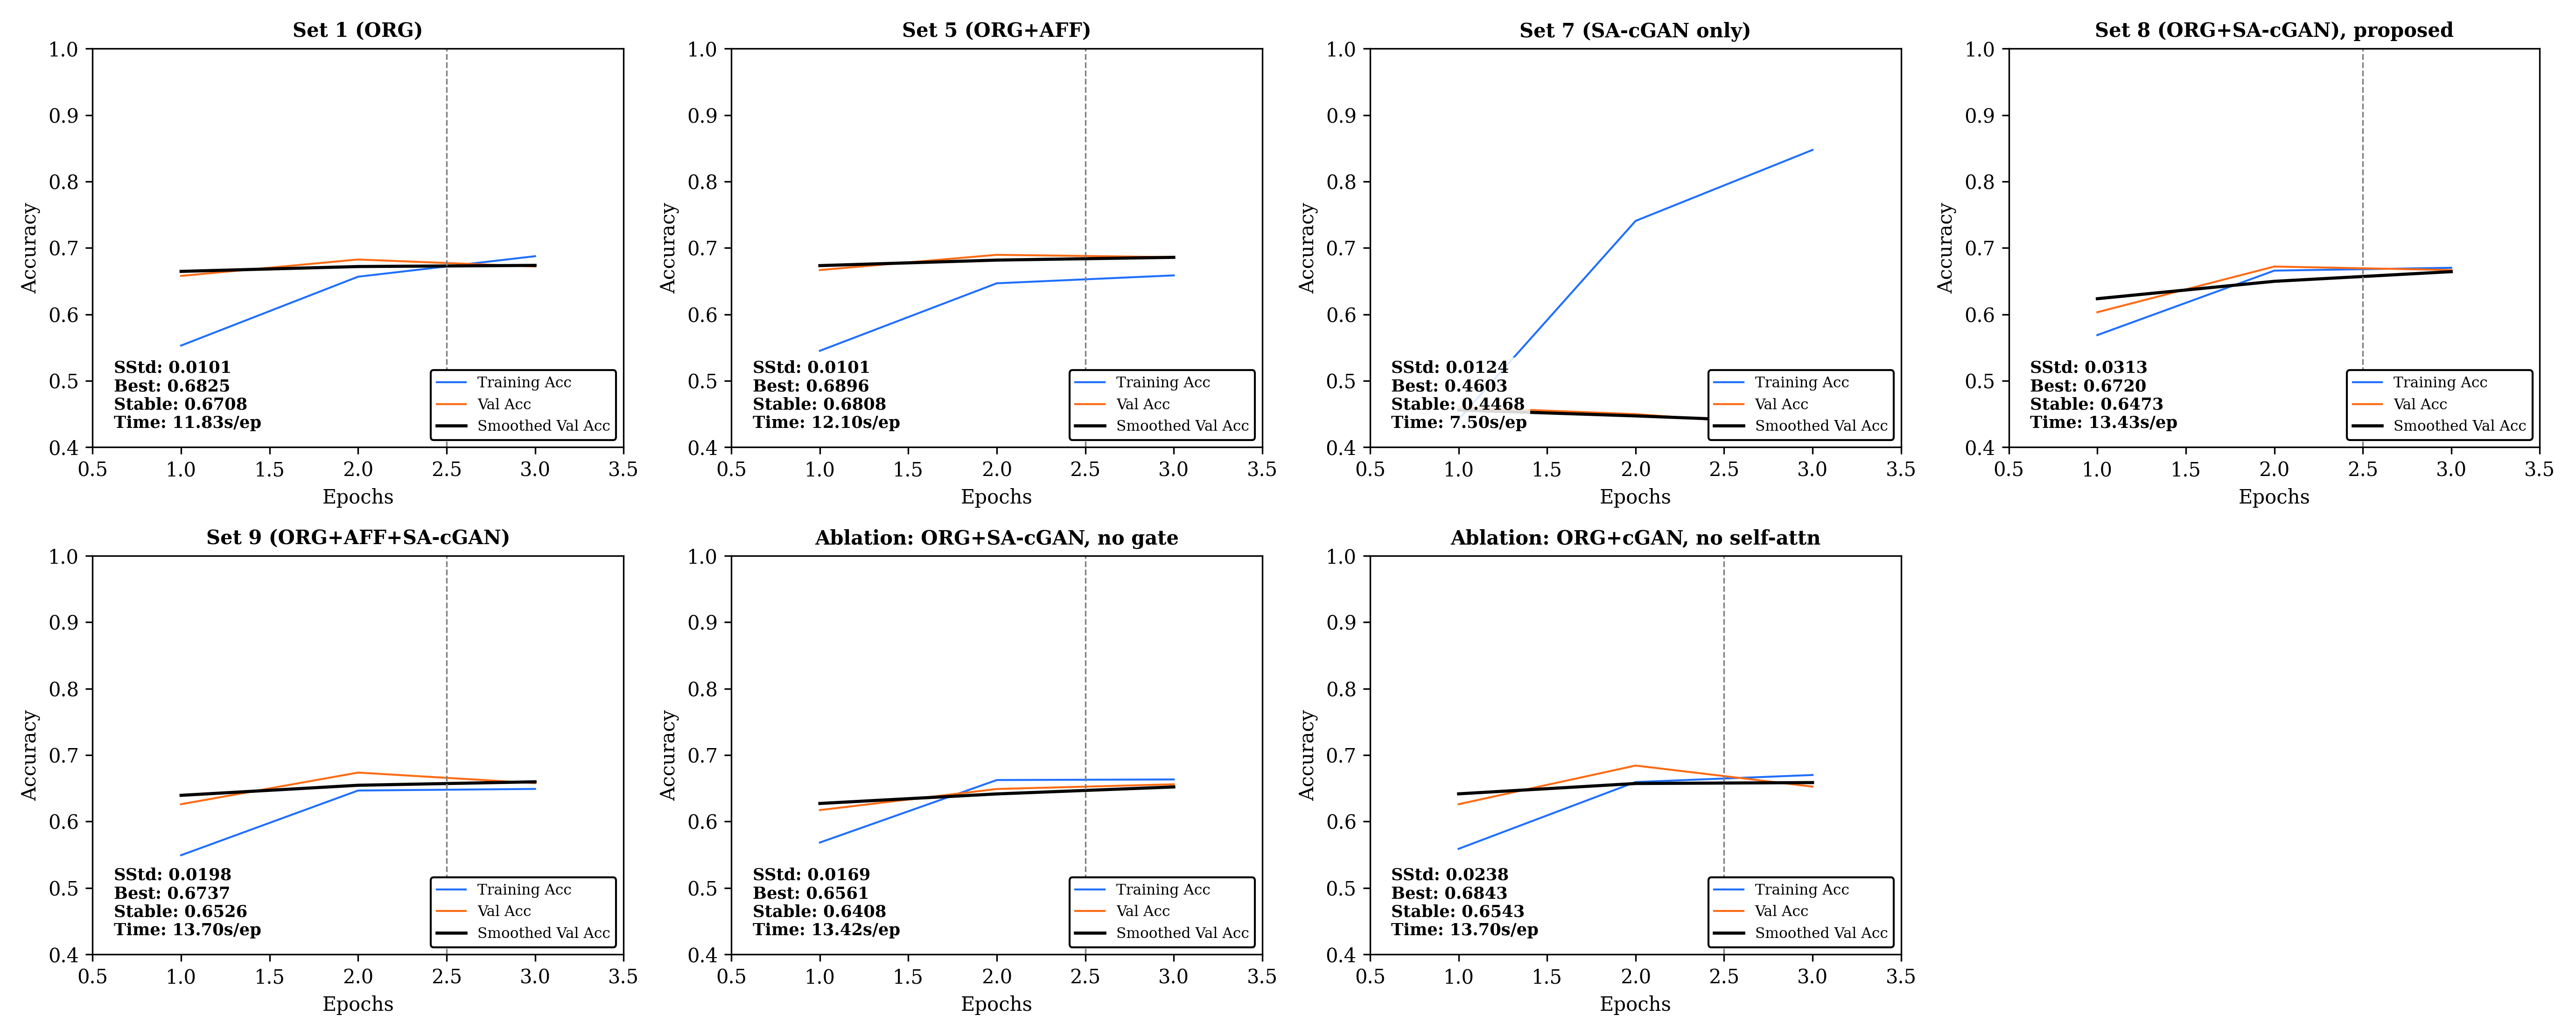

roc_curves.png


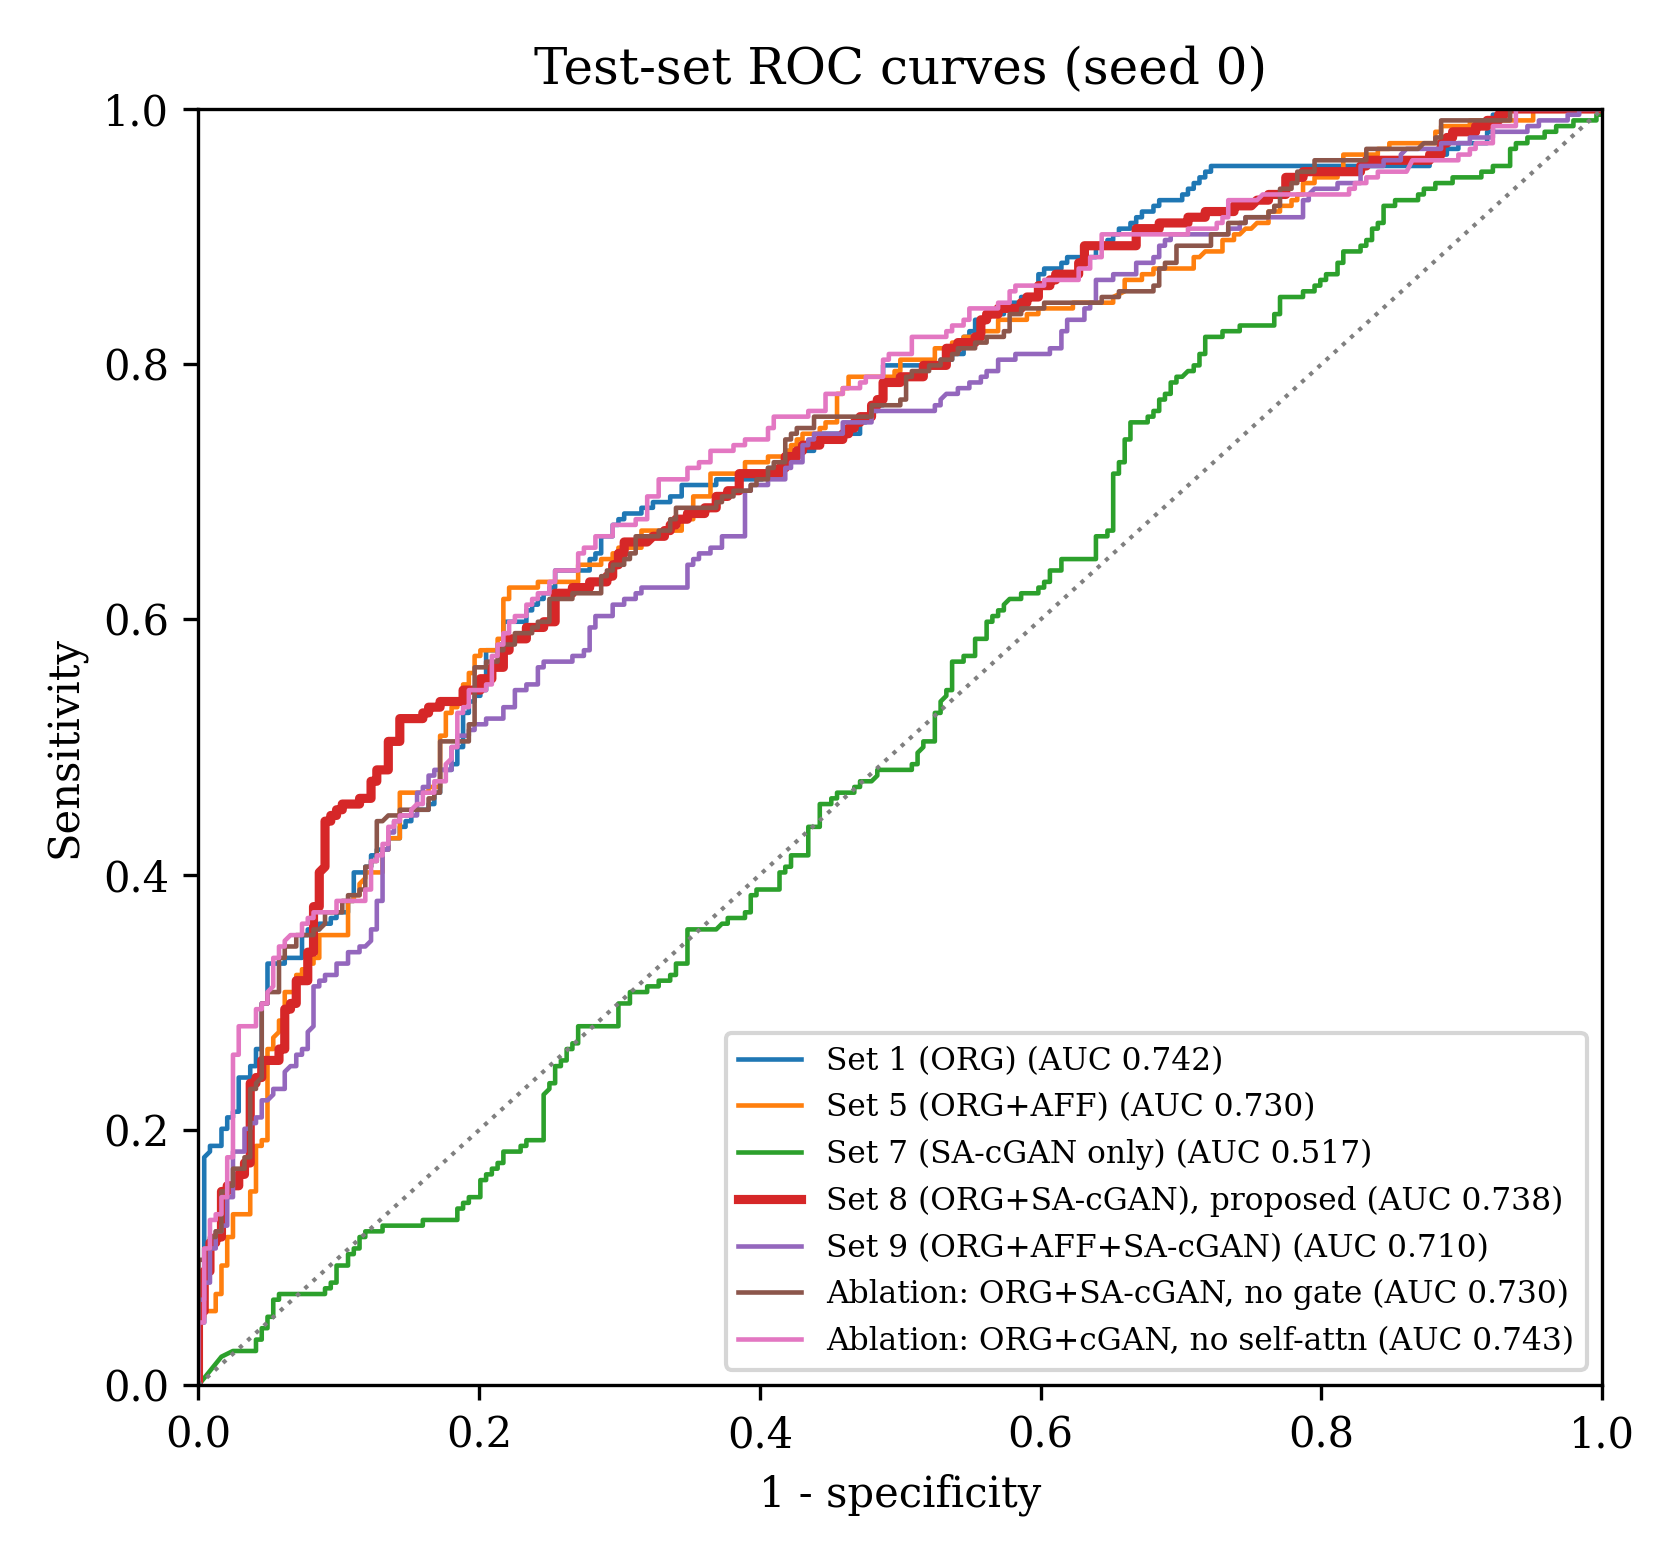

gan_fid_and_losses.png


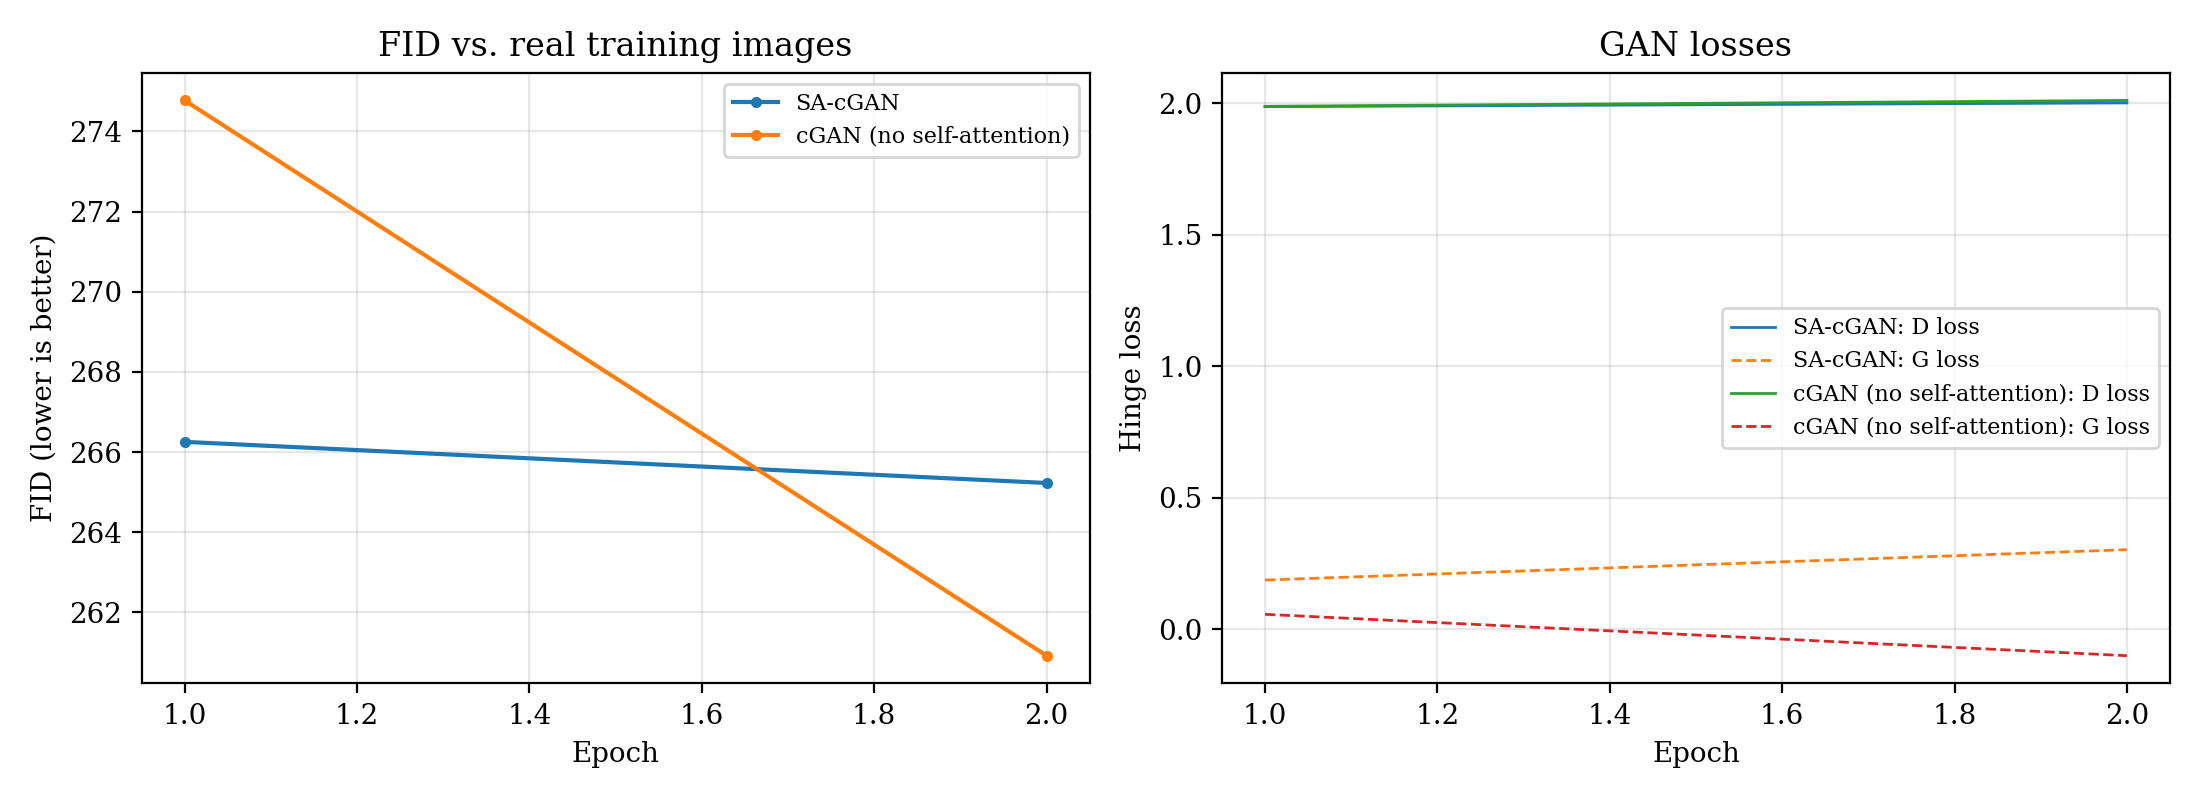

samples_real_vs_synthetic.png


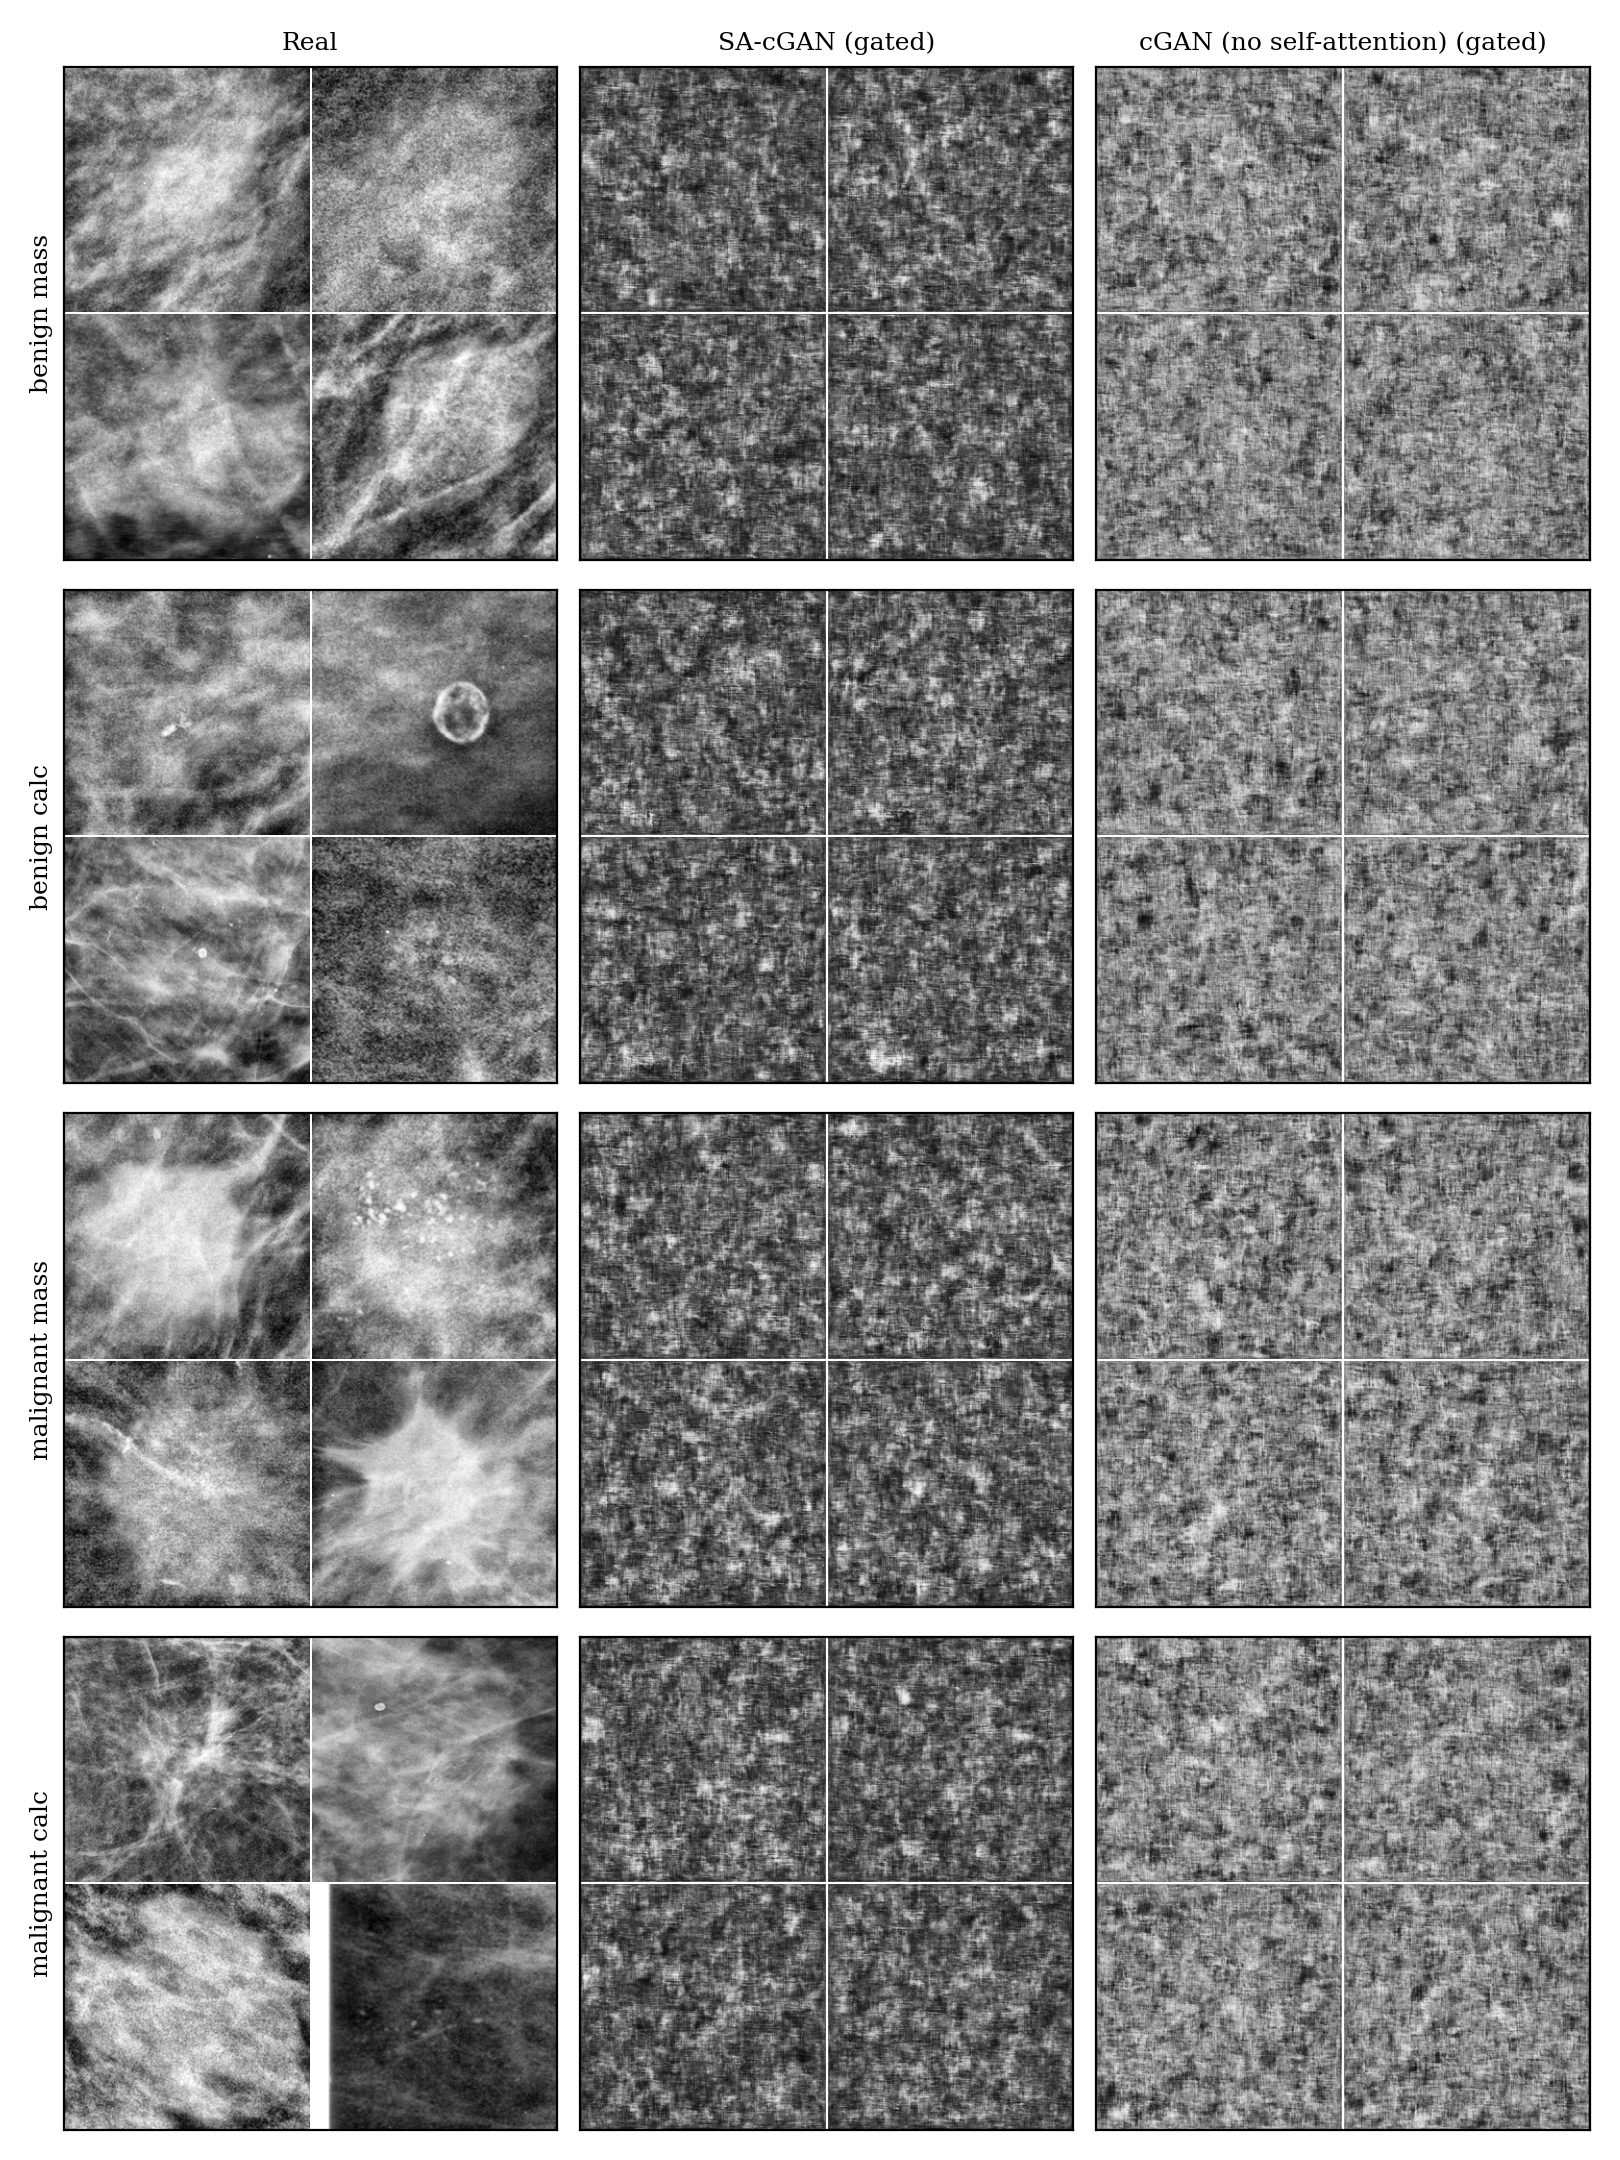

In [38]:
# Show the results produced so far (also works after an unfinished session)
from IPython.display import Image as IPImage, Markdown, display


def show_results():
    res = os.path.join(build_config([])["out_dir"], "results")
    summary = os.path.join(res, "summary.md")
    if not os.path.exists(summary):
        print("No results yet in", res)
        return
    display(Markdown(open(summary).read()))
    for name in ("training_curves.png", "roc_curves.png", "gan_fid_and_losses.png",
                 "samples_real_vs_synthetic.png"):
        path = os.path.join(res, name)
        if os.path.exists(path):
            print(name)
            display(IPImage(filename=path, width=1000))


show_results()
